# Synthetic models to reproduce the Voynich bounce

The multilingual notebook demonstrated that the bounce in the Voynich entropy curve (H drops at H1, then rises at H2-H4) is **unique**: none of the 6 natural languages or 2 ciphers produces it.

Objective: build 5 synthetic models that attempt to reproduce this bounce to identify the generative mechanism.

| # | Model | Idea | Parameters |
|---|-------|------|------------|
| 1 | **Independent slots** | Each position samples from a position-specific distribution | tau (temperature), noise |
| 2 | **Verbose cipher (codebook)** | Each plaintext letter maps to 1-3 glyphs | codeword length distribution |
| 3 | **Nomenclator** | Homophonic substitution + codebook for frequent n-grams + nulls | n_homophones, p_nom_use, null_rate |
| 4 | **Slot+Markov hybrid** | Positional slots + Markov transitions between adjacent glyphs | tau, alpha, noise |
| 5 | **Polyalphabetic nomenclator** | Nomenclator with periodically shifted table (Alberti-style) | shift_period, shift_amount, n_homophones |


In [1]:
# ── Cell 1: Imports + visual constants ──────────────────────────
import re, math, random, io, os, tarfile, json, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

# ── Colors: Voynich + 3 synthetics + 8 multilingual reference ──
COLOR_MAP = {
    'Voynich':      '#E53935',
    'Slot':         '#7B1FA2',
    'Verbose':      '#00897B',
    'Nomenclator':  '#FF6F00',
    'Hybrid':       '#304FFE',
    'NomPoly':      '#2E7D32',
    'Silabico':     '#795548',
    'SilPart':      '#009688',
    # Multilingual (reference)
    'Latin':        '#1E88E5',
    'Cesar':        '#43A047',
    'Vigenere':     '#FB8C00',
    'Hebreo':       '#8E24AA',
    'Arabe':        '#00ACC1',
    'Turco':        '#6D4C41',
    'Fines':        '#D81B60',
    # Models from literature
    'Cardan':       '#F44336',
    'AutoCita':     '#FF9800',
    'Polyg3':       '#3F51B5',
    'Naibbe':       '#607D8B',
}

MARKER_MAP = {
    'Voynich':      'o',
    'Slot':         's',
    'Verbose':      '^',
    'Nomenclator':  'D',
    'Hybrid':       'H',
    'NomPoly':      '8',
    'Silabico':     'P',
    'SilPart':      '2',
    'Latin':        'v',
    'Cesar':        'P',
    'Vigenere':     'X',
    'Hebreo':       '*',
    'Arabe':        'h',
    'Turco':        'p',
    'Fines':        'd',
    'Cardan':       'p',
    'AutoCita':     '*',
    'Polyg3':       'h',
    'Naibbe':       'd',
}

LW_MAP = {k: (3 if k == 'Voynich' else 2) for k in COLOR_MAP}

SYNTH_ORDER = ['Voynich', 'Slot', 'Verbose', 'Nomenclator', 'Hybrid', 'NomPoly', 'Silabico', 'SilPart',
               'Cardan', 'AutoCita', 'Polyg3', 'Naibbe']
ALL_ORDER   = ['Voynich', 'Slot', 'Verbose', 'Nomenclator', 'Hybrid', 'NomPoly', 'Silabico', 'SilPart',
               'Cardan', 'AutoCita', 'Polyg3', 'Naibbe',
               'Latin', 'Cesar', 'Vigenere', 'Hebreo', 'Arabe', 'Turco', 'Fines']

print('Imports OK')


Imports OK


In [2]:
# ── Cell 2: Reused functions (with OPTIMIZED conditional_entropy_n) ──

def parsear_sta_completo(filepath):
    """Correct parser for STA1 2.0."""
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


def entropia_condicional_n(corpus_plano, n, max_tokens=500_000):
    """
    H(token | n previous tokens) with Witten-Bell smoothing.
    OPTIMIZED: precomputation of types_per_ctx to avoid linear scan.
    """
    corpus = corpus_plano[:max_tokens]
    vocab  = sorted(set(corpus))
    V      = len(vocab)

    if n == 0:
        freq  = Counter(corpus)
        total = len(corpus)
        return -sum((c / total) * math.log2(c / total) for c in freq.values())

    ngram_counts  = Counter()
    nplus1_counts = Counter()

    for i in range(len(corpus) - n):
        ctx      = tuple(corpus[i:i + n])
        next_tok = corpus[i + n]
        ngram_counts[ctx] += 1
        nplus1_counts[(ctx, next_tok)] += 1

    # Precompute types per context (O(|nplus1_counts|) one time)
    tipos_por_ctx = Counter()
    for (ctx, tok) in nplus1_counts:
        tipos_por_ctx[ctx] += 1

    # Precompute counts per context for O(1) access
    ctx_to_toks = defaultdict(dict)
    for (ctx, tok), count in nplus1_counts.items():
        ctx_to_toks[ctx][tok] = count

    total_ctx = sum(ngram_counts.values())
    H = 0.0

    for ctx, ctx_count in ngram_counts.items():
        p_ctx     = ctx_count / total_ctx
        tipos_ctx = tipos_por_ctx[ctx]  # O(1)
        denom     = ctx_count + tipos_ctx
        if denom == 0:
            continue

        H_ctx = 0.0
        toks_in_ctx = ctx_to_toks[ctx]
        # Tokens observed in this context
        for tok, c in toks_in_ctx.items():
            p = c / denom
            H_ctx -= p * math.log2(p)
        # Unobserved tokens: all share the same probability
        n_unseen = V - tipos_ctx
        if n_unseen > 0:
            p_unseen = (tipos_ctx / denom) / V
            if p_unseen > 0:
                H_ctx -= n_unseen * p_unseen * math.log2(p_unseen)

        H += p_ctx * H_ctx

    return H


def construir_matriz_transicion(corpus_palabras):
    corpus_plano = [g for p in corpus_palabras for g in p]
    tokens = sorted(set(corpus_plano))
    index  = {tok: i for i, tok in enumerate(tokens)}
    n      = len(tokens)
    M = np.zeros((n, n))
    for i in range(len(corpus_plano) - 1):
        r, c = index[corpus_plano[i]], index[corpus_plano[i + 1]]
        M[r, c] += 1
    row_sums = M.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M = M / row_sums
    return M, tokens, index


def analisis_espectral(M, nombre, tokens=None):
    eigvals, eigvecs = np.linalg.eig(M)
    orden       = np.argsort(np.abs(eigvals))[::-1]
    eigvals_abs = np.abs(eigvals)[orden]
    lambda1 = eigvals_abs[0]
    lambda2 = eigvals_abs[1]
    gap     = lambda1 - lambda2
    t_mix   = 1.0 / gap if gap > 0 else np.inf
    return {
        'nombre': nombre, 'lambda1': lambda1, 'lambda2': lambda2,
        'gap': gap, 't_mix': t_mix, 'eigvals_abs': eigvals_abs
    }


def metricas_curva(nombre, vals, ordenes):
    h0      = vals[0]
    norm    = [v / h0 for v in vals]
    h_min   = min(vals)
    n_min   = ordenes[vals.index(h_min)]
    rebote  = vals[-1] - h_min
    pendiente_ini = (vals[0] - vals[1]) / vals[0]
    try:
        auc = np.trapezoid(norm, ordenes) / ordenes[-1]
    except AttributeError:
        auc = np.trapz(norm, ordenes) / ordenes[-1]
    return {
        'nombre': nombre, 'H0': h0, 'H_min': h_min,
        'N_min': n_min, 'rebote': rebote,
        'pendiente_ini': pendiente_ini, 'AUC_norm': auc,
    }


def construir_tabla_tp(corpus):
    conteo_tp = defaultdict(int)
    conteo_t = defaultdict(int)
    conteo_p = defaultdict(int)
    total = 0
    for palabra in corpus:
        n = len(palabra)
        for i, token in enumerate(palabra):
            if i == 0:
                pos = 'inicio'
            elif i == n-1:
                pos = 'final'
            else:
                pos = 'medio'
            conteo_tp[(token, pos)] += 1
            conteo_t[token] += 1
            conteo_p[pos] += 1
            total += 1
    return conteo_tp, conteo_t, conteo_p, total


def mutual_information(corpus):
    conteo_tp, conteo_t, conteo_p, total = construir_tabla_tp(corpus)
    mi = 0.0
    for (token, pos), count_tp in conteo_tp.items():
        p_tp = count_tp / total
        p_t  = conteo_t[token] / total
        p_p  = conteo_p[pos] / total
        mi += p_tp * math.log(p_tp / (p_t * p_p), 2)
    return mi


def mutual_information_bigram(corpus):
    bigram_counts = Counter()
    unigram_counts = Counter()
    total_bigrams = 0
    total_tokens = 0
    for palabra in corpus:
        total_tokens += len(palabra)
        unigram_counts.update(palabra)
        for i in range(len(palabra) - 1):
            bigram = (palabra[i], palabra[i+1])
            bigram_counts[bigram] += 1
            total_bigrams += 1
    mi = 0.0
    for (t1, t2), count in bigram_counts.items():
        p_xy = count / total_bigrams
        p_x = unigram_counts[t1] / total_tokens
        p_y = unigram_counts[t2] / total_tokens
        mi += p_xy * math.log2(p_xy / (p_x * p_y))
    return mi


print('Functions loaded OK (conditional_entropy_n optimized)')


# ── Parallel sweep helper ────────────────────────────────────────────
import os, io, contextlib
from multiprocessing import Pool, cpu_count

os.environ['CUDA_VISIBLE_DEVICES'] = ''

def compute_metrics_from_words(words, label=''):
    """Compute all fingerprint metrics from a generated word list."""
    flat = [g for p in words for g in p]
    h_vals = [entropia_condicional_n(flat, n) for n in range(5)]
    mi_p = mutual_information(words)
    mi_b = mutual_information_bigram(words)
    mc = metricas_curva(label, h_vals, [0,1,2,3,4])
    decay = (h_vals[0] - h_vals[4]) / h_vals[0] if h_vals[0] > 0 else 0
    with contextlib.redirect_stdout(io.StringIO()):
        M_tmp, _, _ = construir_matriz_transicion(words)
        sp = analisis_espectral(M_tmp, '', tokens=None)
    return {
        'H_curve': h_vals, 'MI_pos': mi_p, 'MI_big': mi_b,
        'rebote': mc['rebote'], 'decay': decay, 'gap': sp['gap'],
        'n_words': len(words), 'vocab': len(set(flat)),
    }

N_CPUS = max(1, cpu_count() - 1)
print(f'Parallel sweep helper loaded (N_CPUS={N_CPUS})')


Functions loaded OK (conditional_entropy_n optimized)
Parallel sweep helper loaded (N_CPUS=15)


In [3]:
# ── Cell 3: Distance function to Voynich ────────────────────────

def voynich_distance(metrics, target):
    """
    Weighted Euclidean distance in fingerprint space.
    metrics/target: dicts with keys 'rebote', 'decay', 'MI_pos', 'MI_big', 'gap'.
    Weights: bounce=3, decay=2, MI_pos=1.5, MI_big=1.5, gap=1.
    """
    pesos = {'rebote': 3.0, 'decay': 2.0, 'MI_pos': 1.5, 'MI_big': 1.5, 'gap': 1.0}
    d2 = 0.0
    for key, w in pesos.items():
        diff = metrics.get(key, 0) - target.get(key, 0)
        d2 += w * diff ** 2
    return math.sqrt(d2)


print('voynich_distance OK')

voynich_distance OK


In [4]:
# ── Cell 4: Load Voynich + extract empirical distributions ──────
STA_PATH = 'corpus/voynich_sta.txt'

tokens_voynich = parsear_sta_completo(STA_PATH)
palabras_voynich = tokens_a_palabras(tokens_voynich)
corpus_plano_voynich = [g for p in palabras_voynich for g in p]

N_VOYNICH = len(palabras_voynich)
VOCAB_VOYNICH = sorted(set(corpus_plano_voynich))

# Distribution of word lengths
wlen_counter = Counter(len(p) for p in palabras_voynich)
total_words = sum(wlen_counter.values())
wlen_dist = {k: v / total_words for k, v in sorted(wlen_counter.items())}

# Distribution by absolute position: pos_probs[pos_int][glyph] = prob
max_wlen = max(len(p) for p in palabras_voynich)
pos_counts = defaultdict(Counter)
for palabra in palabras_voynich:
    for i, g in enumerate(palabra):
        pos_counts[i][g] += 1

pos_probs = {}
for pos, cnt in pos_counts.items():
    total = sum(cnt.values())
    pos_probs[pos] = {g: c / total for g, c in cnt.items()}

print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano_voynich):,} tokens, '
      f'vocab = {len(VOCAB_VOYNICH)}')
print(f'Mean length: {np.mean([len(p) for p in palabras_voynich]):.2f}')
print(f'Length: {dict(sorted(wlen_counter.items())[:10])}...')
print(f'Positions with distribution: {len(pos_probs)}')

Voynich: 37,087 words, 157,254 tokens, vocab = 166
Mean length: 4.24
Length: {1: 883, 2: 3529, 3: 8143, 4: 9328, 5: 8269, 6: 4342, 7: 1605, 8: 516, 9: 222, 10: 113}...
Positions with distribution: 17


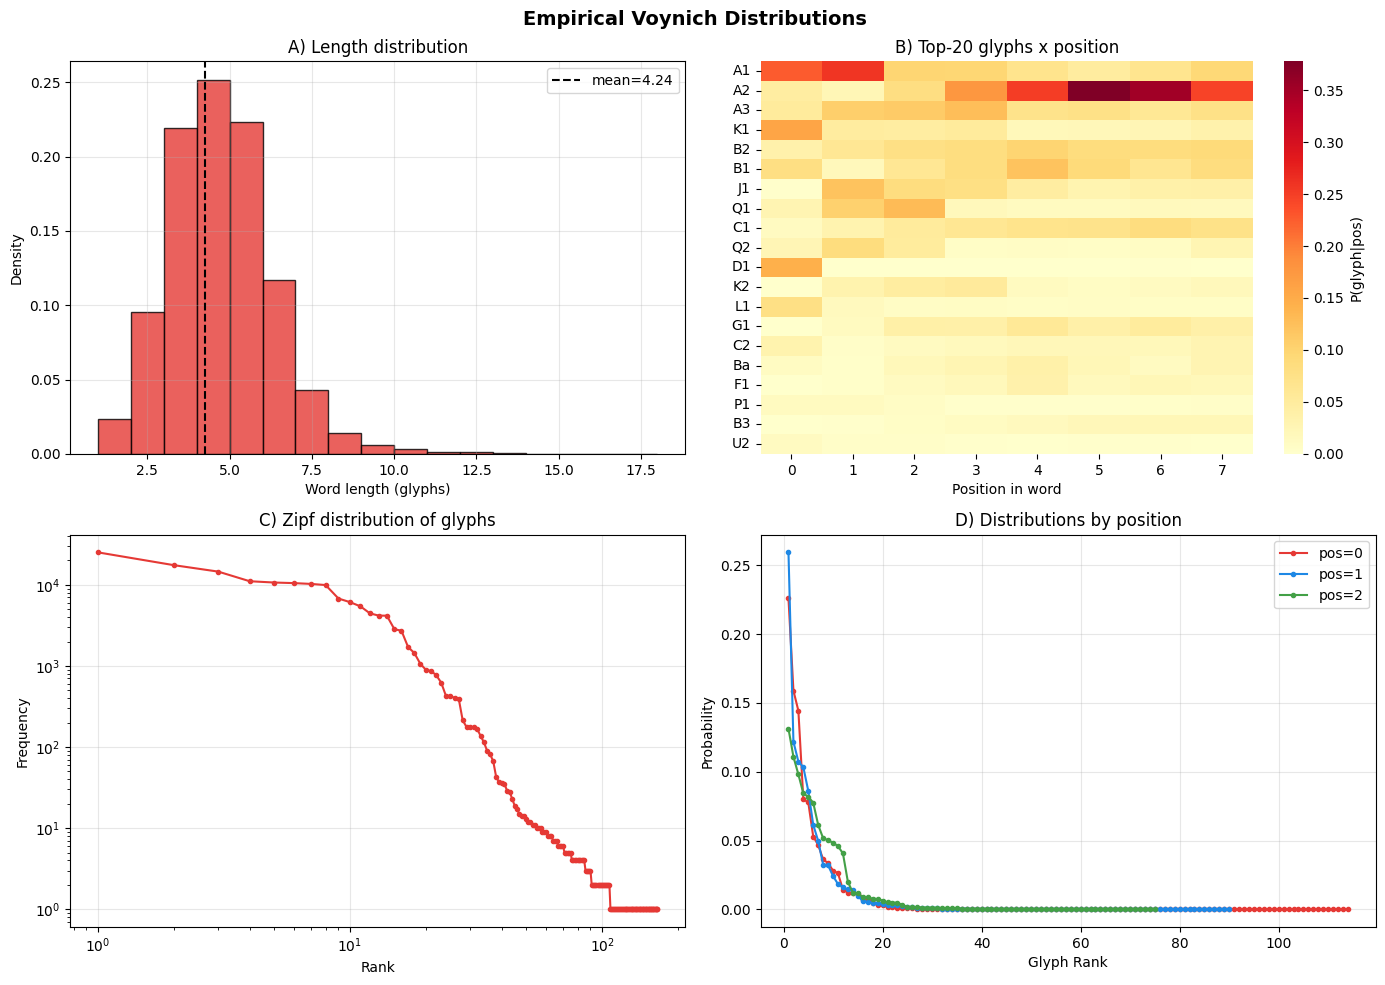

Saved: voynich_distribuciones.png


In [5]:
# ── Cell 5: Visualisation of empirical distributions ─────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel A: Histogram of lengths
ax = axes[0, 0]
lens = [len(p) for p in palabras_voynich]
ax.hist(lens, bins=range(1, max_wlen + 2), color='#E53935', alpha=0.8,
        edgecolor='black', density=True)
ax.set_xlabel('Word length (glyphs)')
ax.set_ylabel('Density')
ax.set_title('A) Length distribution')
ax.axvline(np.mean(lens), color='black', ls='--', label=f'mean={np.mean(lens):.2f}')
ax.legend()
ax.grid(True, alpha=0.3)

# Panel B: Heatmap top-20 glyphs x positions (0-7)
ax = axes[0, 1]
top_glifos = [g for g, _ in Counter(corpus_plano_voynich).most_common(20)]
pos_range = range(min(8, max_wlen))
heat_data = np.zeros((len(top_glifos), len(pos_range)))
for j, pos in enumerate(pos_range):
    if pos in pos_probs:
        for i, g in enumerate(top_glifos):
            heat_data[i, j] = pos_probs[pos].get(g, 0)
sns.heatmap(heat_data, ax=ax, xticklabels=[str(p) for p in pos_range],
            yticklabels=top_glifos, cmap='YlOrRd', cbar_kws={'label': 'P(glyph|pos)'})
ax.set_xlabel('Position in word')
ax.set_title('B) Top-20 glyphs x position')

# Panel C: Zipf
ax = axes[1, 0]
freq = Counter(corpus_plano_voynich)
ranks = range(1, len(freq) + 1)
freqs_sorted = sorted(freq.values(), reverse=True)
ax.loglog(list(ranks), freqs_sorted, 'o-', color='#E53935', markersize=3)
ax.set_xlabel('Rank')
ax.set_ylabel('Frequency')
ax.set_title('C) Zipf distribution of glyphs')
ax.grid(True, alpha=0.3)

# Panel D: Distributions in positions 0, 1, 2
ax = axes[1, 1]
for pos_i, color_i in [(0, '#E53935'), (1, '#1E88E5'), (2, '#43A047')]:
    if pos_i in pos_probs:
        probs = pos_probs[pos_i]
        sorted_probs = sorted(probs.values(), reverse=True)
        ax.plot(range(1, len(sorted_probs) + 1), sorted_probs, 'o-',
                color=color_i, markersize=3, label=f'pos={pos_i}')
ax.set_xlabel('Glyph Rank')
ax.set_ylabel('Probability')
ax.set_title('D) Distributions by position')
ax.legend()
ax.grid(True, alpha=0.3)

fig.suptitle('Empirical Voynich Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig('images/voynich_distribuciones.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: voynich_distribuciones.png')

In [6]:
# ── Cell 6: Extended entropy H0-H6 + spectral + MI → VOYNICH_TARGET ──
print('Computing H0-H6 Voynich...')
ordenes_ext = [0, 1, 2, 3, 4, 5, 6]
H_voynich_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(corpus_plano_voynich, n)
    H_voynich_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral
M_v, toks_v, idx_v = construir_matriz_transicion(palabras_voynich)
spec_v = analisis_espectral(M_v, 'Voynich', tokens=toks_v)

# MI
mi_pos_v = mutual_information(palabras_voynich)
mi_big_v = mutual_information_bigram(palabras_voynich)
print(f'\nMI_pos = {mi_pos_v:.4f}, MI_big = {mi_big_v:.4f}')

# Curve metrics (about H0-H4 for compatibility)
mc_v = metricas_curva('Voynich', H_voynich_ext[:5], [0,1,2,3,4])

VOYNICH_TARGET = {
    'H_curve': H_voynich_ext,
    'H0': H_voynich_ext[0],
    'decay': mc_v['pendiente_ini'] * (len(ordenes_ext[:5]) - 1) / (len(ordenes_ext[:5]) - 1)  # use actual
            if False else (H_voynich_ext[0] - H_voynich_ext[4]) / H_voynich_ext[0],
    'rebote': mc_v['rebote'],
    'gap': spec_v['gap'],
    'MI_pos': mi_pos_v,
    'MI_big': mi_big_v,
    'vocab': len(VOCAB_VOYNICH),
    'mean_wlen': np.mean([len(p) for p in palabras_voynich]),
}

print(f'\nVOYNICH_TARGET:')
for k, v in VOYNICH_TARGET.items():
    if k == 'H_curve':
        print(f'  {k}: [{", ".join(f"{x:.3f}" for x in v)}]')
    else:
        print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

Computing H0-H6 Voynich...
  H0 = 4.1408
  H1 = 2.9608
  H2 = 2.9898
  H3 = 3.3165
  H4 = 3.7739
  H5 = 4.1740
  H6 = 4.4086

MI_pos = 0.6578, MI_big = 1.6811

VOYNICH_TARGET:
  H_curve: [4.141, 2.961, 2.990, 3.317, 3.774, 4.174, 4.409]
  H0: 4.1408
  decay: 0.0886
  rebote: 0.8131
  gap: 0.5406
  MI_pos: 0.6578
  MI_big: 1.6811
  vocab: 166
  mean_wlen: 4.2401


## Model 1: Independent slots

Each word position samples **independently** from a position-specific distribution (extracted from empirical Voynich data).

**Parameters:**
- `tau` (temperature): <1 sharpens the distributions (more probable glyphs dominate more), >1 flattens them
- `noise` (break probability): with probability `noise`, the glyph is sampled uniformly instead of from the slot

**Prediction:** Low H1 (strong local structure from positional slots), H2+ rises (context crossing a slot boundary provides no information because slots are independent).

In [7]:
# ── Cell 8: Slot model generator ──────────────────────────────

def generar_slot_model(pos_probs, wlen_dist, tau, noise, vocab, n_words, seed=42):
    """
    Generates synthetic corpus with independent positional slots.
    
    pos_probs: dict[pos_int, dict[glyph, prob]] — empirical distributions
    wlen_dist: dict[length, prob] — length distribution
    tau: temperature (applies to log-probs)
    noise: uniform sampling prob
    vocab: list of glyphs
    n_words: number of words to generate
    """
    rng = np.random.RandomState(seed)
    vocab_arr = np.array(vocab)
    V = len(vocab)
    
    # Prepare length distribution
    wlens = sorted(wlen_dist.keys())
    wlen_probs = np.array([wlen_dist[l] for l in wlens])
    
    # Prepare temperature-scaled distributions per position
    pos_dist_cache = {}
    for pos, glyph_probs in pos_probs.items():
        # Construct probabilities vector aligned with vocab
        probs = np.array([glyph_probs.get(g, 1e-10) for g in vocab])
        probs = np.maximum(probs, 1e-10)
        
        log_probs = np.log(probs) / tau
        log_probs -= log_probs.max()  # numerical stability
        tempered = np.exp(log_probs)
        tempered /= tempered.sum()
        pos_dist_cache[pos] = tempered
    
    uniform = np.ones(V) / V
    
    palabras = []
    for _ in range(n_words):
        wlen = rng.choice(wlens, p=wlen_probs)
        palabra = []
        for pos in range(wlen):
            if rng.random() < noise:
                # Uniform sample
                g = vocab_arr[rng.choice(V)]
            else:
                # Sample from positional slot
                if pos in pos_dist_cache:
                    g = vocab_arr[rng.choice(V, p=pos_dist_cache[pos])]
                else:
                    # Position not seen: fall back to nearest available
                    fallback_pos = max(p for p in pos_dist_cache if p <= pos) if any(p <= pos for p in pos_dist_cache) else min(pos_dist_cache.keys())
                    g = vocab_arr[rng.choice(V, p=pos_dist_cache[fallback_pos])]
            palabra.append(g)
        palabras.append(palabra)
    
    return palabras


print('generar_slot_model OK')

generar_slot_model OK


In [8]:
# ── Cell 9: Default example + quick fingerprint ───────────────────
print('Generating Slot model (tau=1.0, noise=0.0)...')
slot_default = generar_slot_model(pos_probs, wlen_dist, tau=1.0, noise=0.0,
                                   vocab=VOCAB_VOYNICH, n_words=N_VOYNICH, seed=42)

flat_slot = [g for p in slot_default for g in p]
print(f'  Words: {len(slot_default):,}, Tokens: {len(flat_slot):,}, '
      f'Vocab: {len(set(flat_slot))}')
print(f' Mean Length: {np.mean([len(p) for p in slot_default]):.2f}')

# Fingerprint quick H0-H4
print('\nH0-H4:')
for n in range(5):
    h = entropia_condicional_n(flat_slot, n)
    print(f'  H{n} = {h:.4f}')

mi_p_slot = mutual_information(slot_default)
mi_b_slot = mutual_information_bigram(slot_default)
print(f'\nMI_pos = {mi_p_slot:.4f}, MI_big = {mi_b_slot:.4f}')

Generating Slot model (tau=1.0, noise=0.0)...
  Words: 37,087, Tokens: 157,539, Vocab: 144
 Mean Length: 4.25

H0-H4:
  H0 = 4.1353
  H1 = 4.1430
  H2 = 4.4153
  H3 = 4.9791
  H4 = 5.0108

MI_pos = 0.2246, MI_big = 0.1681


In [9]:
# ── Cell 10: Sweep Slot model (parallel) ───────────────────────────
taus   = [0.3, 0.5, 0.7, 1.0, 1.5, 2.0]
noises = [0.0, 0.05, 0.1, 0.2, 0.3]

configs = [(tau, noise) for tau in taus for noise in noises]
print(f'Sweep: {len(configs)} configurations ({N_CPUS} workers)')

def _slot_worker(args):
    tau, noise = args
    words = generar_slot_model(pos_probs, wlen_dist, tau=tau, noise=noise,
                                vocab=VOCAB_VOYNICH, n_words=N_VOYNICH, seed=42)
    m = compute_metrics_from_words(words, f'tau={tau},noise={noise}')
    m.update({'tau': tau, 'noise': noise})
    dist = voynich_distance(m, VOYNICH_TARGET)
    m['distance'] = dist
    return m

with Pool(N_CPUS) as pool:
    slot_sweep_results = pool.map(_slot_worker, configs)

# Show top-5
slot_sweep_results.sort(key=lambda x: x['distance'])
print(f'\nTop-5 configurations:')
print(f'{"tau":>6} {"noise":>6} {"dist":>8} {"bounce":>8} {"decay":>8} {"MI_pos":>8} {"MI_big":>8}')
for r in slot_sweep_results[:5]:
    print(f'{r["tau"]:>6.1f} {r["noise"]:>6.2f} {r["distance"]:>8.3f} '
          f'{r["rebote"]:>8.3f} {r["decay"]:>8.3f} {r["MI_pos"]:>8.3f} {r["MI_big"]:>8.3f}')


Sweep: 30 configurations (15 workers)

Top-5 configurations:
   tau  noise     dist   bounce    decay   MI_pos   MI_big
   0.3   0.05    1.410    0.657   -0.142    0.396    0.623
   0.3   0.10    1.452    0.700   -0.149    0.368    0.586
   0.3   0.20    1.605    0.473   -0.081    0.319    0.539
   0.5   0.10    1.696    0.761   -0.163    0.320    0.390
   0.5   0.05    1.716    0.950   -0.227    0.343    0.396


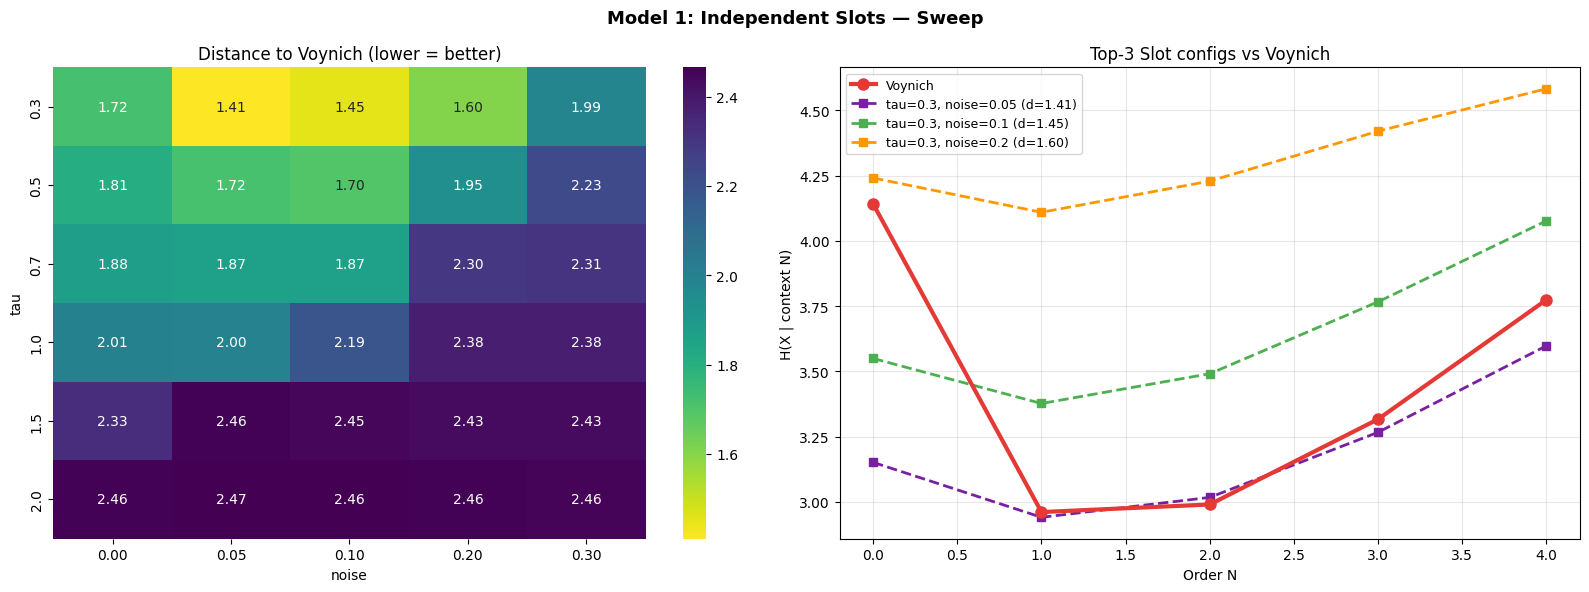

In [10]:
# ── Cell 11: Visualisation sweep Slot ──────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Heatmap tau x noise colored by distance
dist_matrix = np.full((len(taus), len(noises)), np.nan)
for r in slot_sweep_results:
    i = taus.index(r['tau'])
    j = noises.index(r['noise'])
    dist_matrix[i, j] = r['distance']

sns.heatmap(dist_matrix, ax=ax1, annot=True, fmt='.2f', cmap='viridis_r',
            xticklabels=[f'{n:.2f}' for n in noises],
            yticklabels=[f'{t:.1f}' for t in taus])
ax1.set_xlabel('noise')
ax1.set_ylabel('tau')
ax1.set_title('Distance to Voynich (lower = better)')

# Panel B: H0-H4 curves top-3 vs Voynich
ordenes_plot = [0, 1, 2, 3, 4]
ax2.plot(ordenes_plot, VOYNICH_TARGET['H_curve'][:5], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich', zorder=10)

top3_colors = ['#7B1FA2', '#4CAF50', '#FF9800']
for idx, r in enumerate(slot_sweep_results[:3]):
    label = f'tau={r["tau"]}, noise={r["noise"]} (d={r["distance"]:.2f})'
    ax2.plot(ordenes_plot, r['H_curve'], 's--', color=top3_colors[idx],
             lw=2, markersize=6, label=label)

ax2.set_xlabel('Order N')
ax2.set_ylabel('H(X | context N)')
ax2.set_title('Top-3 Slot configs vs Voynich')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

fig.suptitle('Model 1: Independent Slots — Sweep', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Best Slot: tau=0.3, noise=0.05, distance=1.410

H0-H6:
  H0 = 3.1511
  H1 = 2.9407
  H2 = 3.0170
  H3 = 3.2664
  H4 = 3.5977
  H5 = 3.9323
  H6 = 4.2229
MI_pos = 0.3956, MI_big = 0.6226


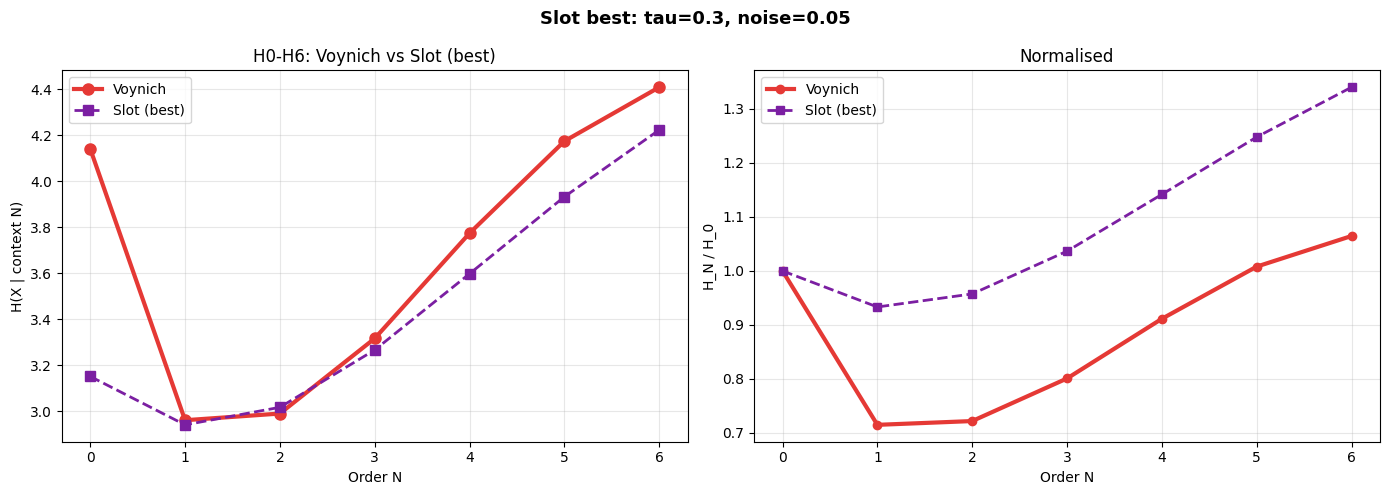

Saved: slot_mejor.png


In [11]:
# ── Cell 12: Best Slot — full analysis H0-H6 ─────────────────
best_slot = slot_sweep_results[0]
print(f'Best Slot: tau={best_slot["tau"]}, noise={best_slot["noise"]}, '
      f'distance={best_slot["distance"]:.3f}')

# Regenerate with the best config
slot_best_words = generar_slot_model(pos_probs, wlen_dist,
                                      tau=best_slot['tau'], noise=best_slot['noise'],
                                      vocab=VOCAB_VOYNICH, n_words=N_VOYNICH, seed=42)
slot_best_flat = [g for p in slot_best_words for g in p]

# H0-H6
print('\nH0-H6:')
H_slot_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(slot_best_flat, n)
    H_slot_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral + MI
M_sb, toks_sb, _ = construir_matriz_transicion(slot_best_words)
spec_sb = analisis_espectral(M_sb, 'Slot (best)')
mi_p_sb = mutual_information(slot_best_words)
mi_b_sb = mutual_information_bigram(slot_best_words)
print(f'MI_pos = {mi_p_sb:.4f}, MI_big = {mi_b_sb:.4f}')

# Save figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(ordenes_ext, VOYNICH_TARGET['H_curve'], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich')
ax1.plot(ordenes_ext, H_slot_ext, 's--',
         color=COLOR_MAP['Slot'], lw=2, markersize=7, label='Slot (best)')
ax1.set_xlabel('Order N')
ax1.set_ylabel('H(X | context N)')
ax1.set_title('H0-H6: Voynich vs Slot (best)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Normalised
norm_v = [v / VOYNICH_TARGET['H_curve'][0] for v in VOYNICH_TARGET['H_curve']]
norm_s = [v / H_slot_ext[0] for v in H_slot_ext]
ax2.plot(ordenes_ext, norm_v, 'o-', color=COLOR_MAP['Voynich'], lw=3, label='Voynich')
ax2.plot(ordenes_ext, norm_s, 's--', color=COLOR_MAP['Slot'], lw=2, label='Slot (best)')
ax2.set_xlabel('Order N')
ax2.set_ylabel('H_N / H_0')
ax2.set_title('Normalised')
ax2.legend()
ax2.grid(True, alpha=0.3)

fig.suptitle(f'Slot best: tau={best_slot["tau"]}, noise={best_slot["noise"]}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/slot_mejor.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: slot_mejor.png')

## Model 2: Verbose cipher (codebook)

Each plaintext letter (Latin) maps to a sequence of 1-3 glyphs (fixed codebook). The resulting glyph stream is segmented into "words" according to the Voynich length distribution.

**Reason for expected bounce:** Within a codeword, H1 is very low (the glyphs composing a letter's code are nearly deterministic). But crossing codeword boundaries, the previous context (glyphs from the prior codeword) does not help predict the next codeword's glyphs → H2+ rises.

**Parameters:** `cw_len_probs` — codeword length distribution: from {1:1.0} (monoalphabetic) to {3:1.0} (each letter = 3 glyphs).

In [12]:
# ── Cell 14: Model generator: Verbose Cipher ───────────────────

def generar_verbose_cipher(plaintext_chars, glyph_vocab, cw_len_probs, wlen_dist,
                            n_words, seed=42):
    """
   Verbose encryption: each letter of the plaintext is encoded with 1-3 glyphs.
    
    plaintext_chars: flat list of plaintext characters
    glyph_vocab: list of available synthetic glyphs
    cw_len_probs: dict[length, prob] — e.g. {1:0.3, 2:0.5, 3:0.2}
    wlen_dist: dict[word_length, prob]
    n_words: number of target words
    """
    rng = np.random.RandomState(seed)
    
    # Plaintext vocabulary
    pt_chars = sorted(set(plaintext_chars))
    V_glyph = len(glyph_vocab)
    
    # Build codebook: each letter → glyph sequence
    cw_lengths = sorted(cw_len_probs.keys())
    cw_probs = np.array([cw_len_probs[l] for l in cw_lengths])
    cw_probs /= cw_probs.sum()
    
    codebook = {}
    used_codes = set()
    for ch in pt_chars:
        cw_len = rng.choice(cw_lengths, p=cw_probs)
        # Generate unique code
        while True:
            code = tuple(glyph_vocab[rng.randint(V_glyph)] for _ in range(cw_len))
            if code not in used_codes:
                used_codes.add(code)
                codebook[ch] = code
                break
    
    # Encode plaintext → glyphs stream  
    glyph_stream = []
    for ch in plaintext_chars:
        if ch in codebook:
            glyph_stream.extend(codebook[ch])
    
    # Segment into words - distribution lengths
    wlens = sorted(wlen_dist.keys())
    wlen_p = np.array([wlen_dist[l] for l in wlens])
    
    palabras = []
    pos = 0
    while len(palabras) < n_words and pos < len(glyph_stream):
        wlen = rng.choice(wlens, p=wlen_p)
        if pos + wlen > len(glyph_stream):
            break
        palabras.append(list(glyph_stream[pos:pos + wlen]))
        pos += wlen
    
    return palabras, codebook


print('generar_verbose_cipher OK')

generar_verbose_cipher OK


In [13]:
# ── Cell 15: Download Vulgata, extract flat stream ───────────────
print('Downloading Vulgata...')
url_vulgata = 'https://www.gutenberg.org/cache/epub/8300/pg8300.txt'
texto_latin = requests.get(url_vulgata, timeout=30).text

# Extract only lowercase letters as flat stream
plaintext_latin = [c for c in texto_latin.lower() if c.isalpha()]
print(f'Latin flat stream: {len(plaintext_latin):,} chars')
print(f'Alphabet: {sorted(set(plaintext_latin))}')

# Generate synthetic glyph vocabulary
GLYPH_VOCAB_200 = [f'G{i:03d}' for i in range(200)]
print(f'Synthetic glyphs: {len(GLYPH_VOCAB_200)} (G000..G199)')

Latin flat stream: 4,082,121 chars
Alphabet: ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', 'ã']
Synthetic glyphs: 200 (G000..G199)


In [14]:
# ── Cell 16: Sweep Verbose Cipher (parallel) ──────────────────────
cw_configs = [
    ({1: 1.0},                       'mono {1:1.0}'),
    ({1: 0.7, 2: 0.3},              'mix {1:.7, 2:.3}'),
    ({1: 0.3, 2: 0.5, 3: 0.2},     'mix {1:.3, 2:.5, 3:.2}'),
    ({2: 1.0},                       'di {2:1.0}'),
    ({2: 0.5, 3: 0.5},              'mix {2:.5, 3:.5}'),
    ({3: 1.0},                       'tri {3:1.0}'),
]

def _verbose_worker(args):
    cw_probs, label = args
    words, codebook = generar_verbose_cipher(
        plaintext_latin, GLYPH_VOCAB_200, cw_probs, wlen_dist,
        n_words=N_VOYNICH, seed=42)
    m = compute_metrics_from_words(words, label)
    m.update({'config': label, 'cw_probs': cw_probs,
              'codebook_sizes': {ch: len(code) for ch, code in codebook.items()}})
    m['distance'] = voynich_distance(m, VOYNICH_TARGET)
    return m

with Pool(N_CPUS) as pool:
    verbose_sweep_results = pool.map(_verbose_worker, cw_configs)

verbose_sweep_results.sort(key=lambda x: x['distance'])
print(f'Results:')
print(f'{"Config":<28} {"dist":>7} {"bounce":>8} {"decay":>7} {"MI_pos":>7} {"MI_big":>7}')
for r in verbose_sweep_results:
    print(f'{r["config"]:<28} {r["distance"]:>7.3f} {r["rebote"]:>8.3f} '
          f'{r["decay"]:>7.3f} {r["MI_pos"]:>7.3f} {r["MI_big"]:>7.3f}')


Results:
Config                          dist   bounce   decay  MI_pos  MI_big
mix {1:.7, 2:.3}               1.749    0.000   0.475   0.000   1.389
mix {1:.3, 2:.5, 3:.2}         1.932    0.000   0.579   0.000   2.324
mono {1:1.0}                   2.102    0.000   0.401   0.000   0.656
di {2:1.0}                     2.435    0.139   0.648   0.000   3.105
mix {2:.5, 3:.5}               3.081    0.000   0.741   0.000   3.669
tri {3:1.0}                    3.234    0.000   0.785   0.001   3.802


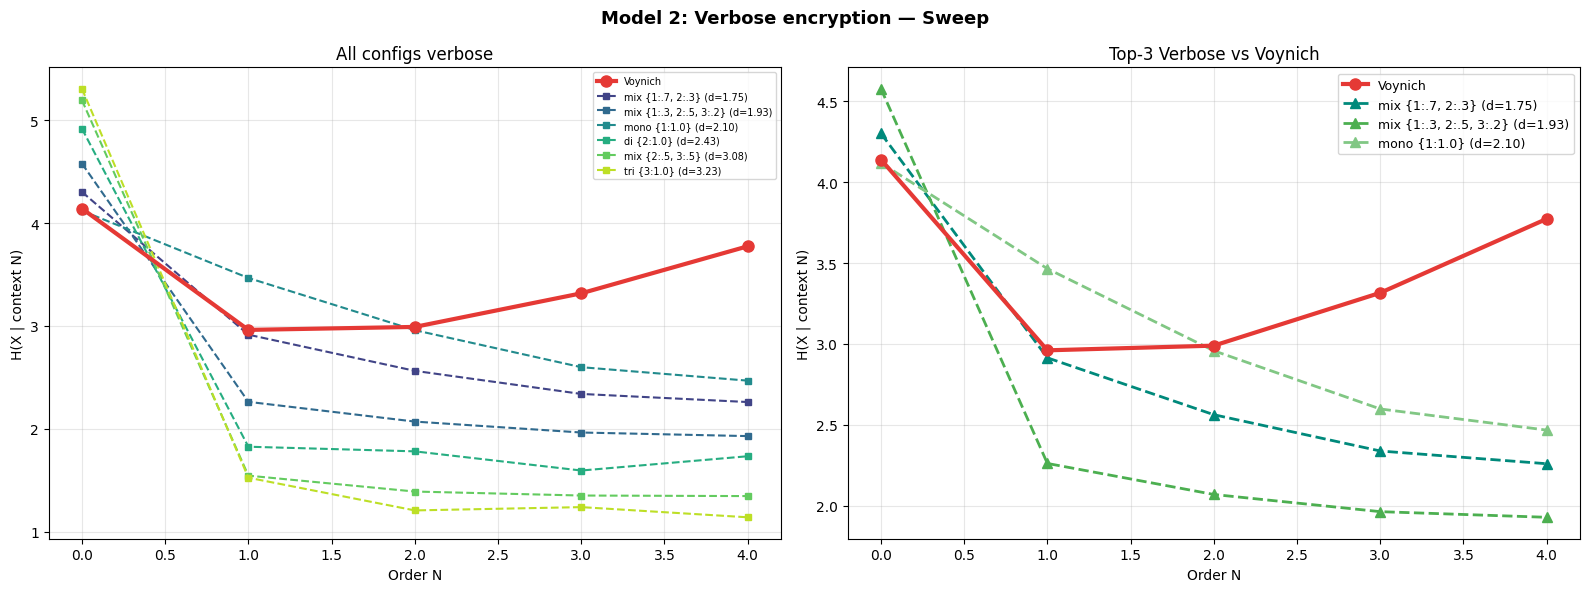

Saved: verbose_sweep.png


In [15]:
# ── Cell 17: Visualisation sweep Verbose ───────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: All configs
ax1.plot([0,1,2,3,4], VOYNICH_TARGET['H_curve'][:5], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich', zorder=10)
cmap_v = plt.cm.viridis(np.linspace(0.2, 0.9, len(verbose_sweep_results)))
for idx, r in enumerate(verbose_sweep_results):
    ax1.plot([0,1,2,3,4], r['H_curve'], 's--', color=cmap_v[idx],
             lw=1.5, markersize=5, label=f'{r["config"]} (d={r["distance"]:.2f})')
ax1.set_xlabel('Order N')
ax1.set_ylabel('H(X | context N)')
ax1.set_title('All configs verbose')
ax1.legend(fontsize=7, loc='best')
ax1.grid(True, alpha=0.3)

# Panel B: Top-3 vs Voynich
ax2.plot([0,1,2,3,4], VOYNICH_TARGET['H_curve'][:5], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich', zorder=10)
top3_colors_v = ['#00897B', '#4CAF50', '#81C784']
for idx, r in enumerate(verbose_sweep_results[:3]):
    label = f'{r["config"]} (d={r["distance"]:.2f})'
    ax2.plot([0,1,2,3,4], r['H_curve'], '^--', color=top3_colors_v[idx],
             lw=2, markersize=7, label=label)
ax2.set_xlabel('Order N')
ax2.set_ylabel('H(X | context N)')
ax2.set_title('Top-3 Verbose vs Voynich')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

fig.suptitle('Model 2: Verbose encryption — Sweep', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/verbose_sweep.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: verbose_sweep.png')

Best Verbose: mix {1:.7, 2:.3}, distance=1.749

H0-H6:
  H0 = 4.3025
  H1 = 2.9144
  H2 = 2.5627
  H3 = 2.3382
  H4 = 2.2595
  H5 = 2.3122
  H6 = 2.4282
MI_pos = 0.0002, MI_big = 1.3888


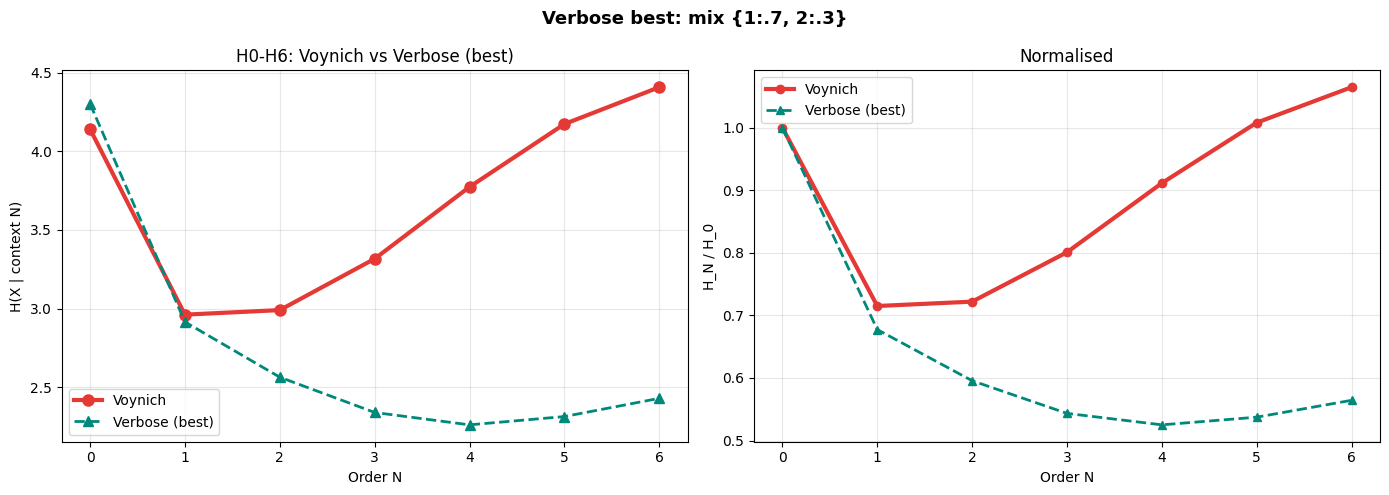

Saved: verbose_mejor.png


In [16]:
# ── Cell 18: Best Verbose — full analysis H0-H6 ──────────────
best_verbose = verbose_sweep_results[0]
print(f'Best Verbose: {best_verbose["config"]}, distance={best_verbose["distance"]:.3f}')

# Regenerate
verbose_best_words, verbose_best_cb = generar_verbose_cipher(
    plaintext_latin, GLYPH_VOCAB_200, best_verbose['cw_probs'], wlen_dist,
    n_words=N_VOYNICH, seed=42
)
verbose_best_flat = [g for p in verbose_best_words for g in p]

# H0-H6
print('\nH0-H6:')
H_verbose_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(verbose_best_flat, n)
    H_verbose_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral + MI
M_vb, toks_vb, _ = construir_matriz_transicion(verbose_best_words)
spec_vb = analisis_espectral(M_vb, 'Verbose (best)')
mi_p_vb = mutual_information(verbose_best_words)
mi_b_vb = mutual_information_bigram(verbose_best_words)
print(f'MI_pos = {mi_p_vb:.4f}, MI_big = {mi_b_vb:.4f}')

# Save figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(ordenes_ext, VOYNICH_TARGET['H_curve'], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich')
ax1.plot(ordenes_ext, H_verbose_ext, '^--',
         color=COLOR_MAP['Verbose'], lw=2, markersize=7, label='Verbose (best)')
ax1.set_xlabel('Order N')
ax1.set_ylabel('H(X | context N)')
ax1.set_title('H0-H6: Voynich vs Verbose (best)')
ax1.legend()
ax1.grid(True, alpha=0.3)

norm_vb = [v / H_verbose_ext[0] for v in H_verbose_ext]
ax2.plot(ordenes_ext, norm_v, 'o-', color=COLOR_MAP['Voynich'], lw=3, label='Voynich')
ax2.plot(ordenes_ext, norm_vb, '^--', color=COLOR_MAP['Verbose'], lw=2, label='Verbose (best)')
ax2.set_xlabel('Order N')
ax2.set_ylabel('H_N / H_0')
ax2.set_title('Normalised')
ax2.legend()
ax2.grid(True, alpha=0.3)

fig.suptitle(f'Verbose best: {best_verbose["config"]}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/verbose_mejor.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: verbose_mejor.png')

## Model 3: Nomenclator

A 15th-century historical cipher combining:
1. **Homophonic substitution**: each plaintext letter can map to N distinct glyphs (chosen at random)
2. **Codebook for frequent n-grams**: frequent Latin bigrams and trigrams are replaced by multi-glyph codes
3. **Optional nulls**: with some probability, random meaningless glyphs are inserted

**Parameters:**
- `n_homophones`: number of homophonic glyphs per letter (1=no homophones, 5=high variety)
- `p_nom_use`: probability of using the codebook for n-grams instead of letter-by-letter encipherment
- `null_rate`: proportion of inserted nulls
- `n_nomenclature`: number of n-gram codebook entries

In [17]:
# ── Cell 20: Nomenclator Model Generator ──────────────────────

def generar_nomenclator(plaintext_words, glyph_vocab, n_homophones, n_nomenclature,
                         p_nom_use, null_rate, nom_len_dist=None, seed=42):
    """
   Nomenclator: homophones + n-gram codebook + nulls.
    
    plaintext_words: list of words (each is list of chars)
    glyph_vocab: list of synthetic glyphs
    n_homophones: homophone glyphs per plaintext letter
    n_nomenclature: entries in the n-gram codebook
    p_nom_use: try to use codebook when an eligible n-gram is found
    null_rate: proportion of null glyphs inserted
    nom_len_dist: dict with code length for nomenclator entries
    """
    rng = np.random.RandomState(seed)
    if nom_len_dist is None:
        nom_len_dist = {2: 0.5, 3: 0.5}
    
    V_glyph = len(glyph_vocab)
    
    # 1. Build homophone table
    pt_chars = sorted(set(c for w in plaintext_words for c in w))
    glyph_idx = 0
    homo_table = {}  # char → glyph list
    for ch in pt_chars:
        homos = []
        for _ in range(n_homophones):
            homos.append(glyph_vocab[glyph_idx % V_glyph])
            glyph_idx += 1
        homo_table[ch] = homos
    
    # 2. Identify the most frequent bigrams/trigrams of plaintext
    flat_pt = [c for w in plaintext_words for c in w]
    bigram_freq = Counter()
    trigram_freq = Counter()
    for w in plaintext_words:
        for i in range(len(w) - 1):
            bigram_freq[tuple(w[i:i+2])] += 1
        for i in range(len(w) - 2):
            trigram_freq[tuple(w[i:i+3])] += 1
    
    # Select top n-grams for the codebook
    nom_entries = {}  # tuple(chars) → tuple(glyphs)
    nom_lens = sorted(nom_len_dist.keys())
    nom_lens_p = np.array([nom_len_dist[l] for l in nom_lens])
    nom_lens_p /= nom_lens_p.sum()
    
    # Mix bigrams and trigrams, ordered by frequency
    candidates = ([(ng, f) for ng, f in bigram_freq.most_common(n_nomenclature)] +
                  [(ng, f) for ng, f in trigram_freq.most_common(n_nomenclature)])
    candidates.sort(key=lambda x: -x[1])
    
    used_codes = set()
    for ng, _ in candidates[:n_nomenclature]:
        code_len = rng.choice(nom_lens, p=nom_lens_p)
        while True:
            code = tuple(glyph_vocab[glyph_idx % V_glyph]
                         for _ in range(code_len))
            glyph_idx += 1
            if code not in used_codes:
                used_codes.add(code)
                nom_entries[ng] = code
                break
    
    # Null glyphs (the last ones of the unused word)
    null_glyphs = glyph_vocab[-5:]  # 5 glyphs reserved for nulls
    
    # 3. Encode word by word
    output_palabras = []
    for word in plaintext_words:
        glyph_word = []
        i = 0
        while i < len(word):
            used_nom = False
            # Try codebook (trigrams first, then bigrams)
            if p_nom_use > 0:
                for ng_len in [3, 2]:
                    if i + ng_len <= len(word):
                        ng = tuple(word[i:i + ng_len])
                        if ng in nom_entries and rng.random() < p_nom_use:
                            glyph_word.extend(nom_entries[ng])
                            i += ng_len
                            used_nom = True
                            break
            
            if not used_nom:
                # Homophone substitution
                ch = word[i]
                if ch in homo_table:
                    g = homo_table[ch][rng.randint(len(homo_table[ch]))]
                    glyph_word.append(g)
                i += 1
            
            # Insert null
            if null_rate > 0 and rng.random() < null_rate:
                glyph_word.append(null_glyphs[rng.randint(len(null_glyphs))])
        
        if glyph_word:
            output_palabras.append(glyph_word)
    
    return output_palabras, homo_table, nom_entries


print('generar_nomenclator OK')

generar_nomenclator OK


In [18]:
# ── Cell 21: Sweep Nomenclator (parallel) ─────────────────────────
palabras_latin_raw = re.findall(r'[a-zA-Z]+', texto_latin.lower())
plaintext_words_latin = [[c for c in p] for p in palabras_latin_raw if 2 <= len(p) <= 15]
plaintext_words_latin = plaintext_words_latin[:N_VOYNICH]

n_homos_list = [1, 3, 5]
p_nom_list   = [0.2, 0.5, 0.8]
null_list    = [0.0, 0.05, 0.1]

configs = [(n_h, p_n, nr) for n_h in n_homos_list for p_n in p_nom_list for nr in null_list]
print(f'Sweep: {len(configs)} configurations ({N_CPUS} workers)')

def _nom_worker(args):
    n_h, p_n, nr = args
    words, _, _ = generar_nomenclator(
        plaintext_words_latin, GLYPH_VOCAB_200,
        n_homophones=n_h, n_nomenclature=50,
        p_nom_use=p_n, null_rate=nr, seed=42)
    flat = [g for p in words for g in p]
    if len(flat) < 100:
        return None
    m = compute_metrics_from_words(words, f'h={n_h},p={p_n},nr={nr}')
    m.update({'n_homophones': n_h, 'p_nom_use': p_n, 'null_rate': nr})
    m['distance'] = voynich_distance(m, VOYNICH_TARGET)
    return m

with Pool(N_CPUS) as pool:
    nom_sweep_results = [r for r in pool.map(_nom_worker, configs) if r is not None]

nom_sweep_results.sort(key=lambda x: x['distance'])
print(f'\nTop-5:')
print(f'{"n_h":>5} {"p_nom":>6} {"null":>6} {"dist":>7} {"bounce":>8} {"decay":>7} {"MI_pos":>7} {"MI_big":>7}')
for r in nom_sweep_results[:5]:
    print(f'{r["n_homophones"]:>5} {r["p_nom_use"]:>6.2f} {r["null_rate"]:>6.2f} '
          f'{r["distance"]:>7.3f} {r["rebote"]:>8.3f} {r["decay"]:>7.3f} '
          f'{r["MI_pos"]:>7.3f} {r["MI_big"]:>7.3f}')


Sweep: 27 configurations (15 workers)

Top-5:
  n_h  p_nom   null    dist   bounce   decay  MI_pos  MI_big
    1   0.20   0.10   1.386    0.102   0.267   0.247   1.847
    1   0.20   0.05   1.444    0.087   0.295   0.253   1.974
    1   0.20   0.00   1.451    0.121   0.333   0.257   2.101
    3   0.20   0.10   1.557    0.000   0.296   0.248   1.878
    5   0.20   0.10   1.574    0.000   0.316   0.248   1.930


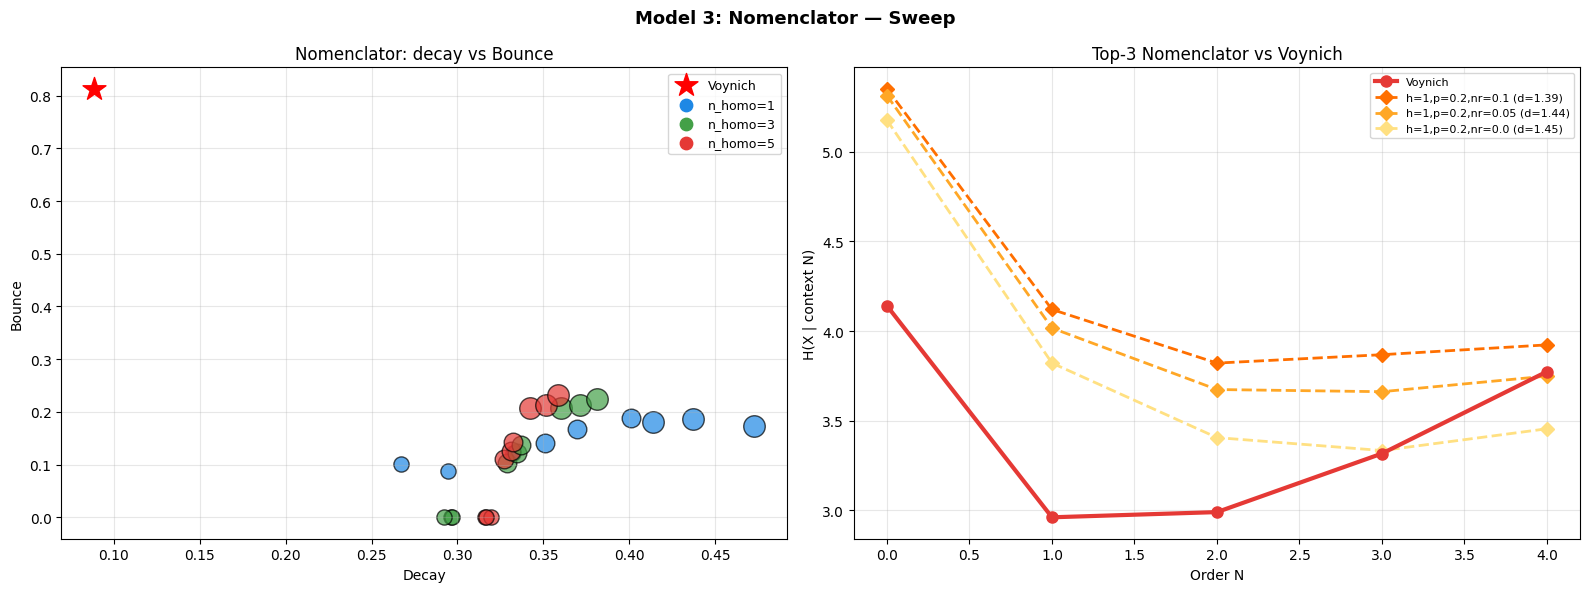

Saved: nomenclator_sweep.png


In [19]:
# ── Cell 22: Visualisation sweep Nomenclator ───────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Scatter distance vs bounce, colored by n_homophones
homo_colors = {1: '#1E88E5', 3: '#43A047', 5: '#E53935'}
for r in nom_sweep_results:
    ax1.scatter(r['decay'], r['rebote'],
               color=homo_colors.get(r['n_homophones'], 'gray'),
               s=80 + r['p_nom_use'] * 200,
               alpha=0.7, edgecolors='black')
# Voynich
ax1.scatter(VOYNICH_TARGET['decay'], VOYNICH_TARGET['rebote'],
            color='red', marker='*', s=300, zorder=10, label='Voynich')
# Legend
for nh, col in homo_colors.items():
    ax1.scatter([], [], color=col, s=80, label=f'n_homo={nh}')
ax1.set_xlabel('Decay')
ax1.set_ylabel('Bounce')
ax1.set_title('Nomenclator: decay vs Bounce')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# Panel B: Top-3 curves vs Voynich
ax2.plot([0,1,2,3,4], VOYNICH_TARGET['H_curve'][:5], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich', zorder=10)
top3_colors_n = ['#FF6F00', '#FFA726', '#FFE082']
for idx, r in enumerate(nom_sweep_results[:3]):
    label = f'h={r["n_homophones"]},p={r["p_nom_use"]},nr={r["null_rate"]} (d={r["distance"]:.2f})'
    ax2.plot([0,1,2,3,4], r['H_curve'], 'D--', color=top3_colors_n[idx],
             lw=2, markersize=7, label=label)
ax2.set_xlabel('Order N')
ax2.set_ylabel('H(X | context N)')
ax2.set_title('Top-3 Nomenclator vs Voynich')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

fig.suptitle('Model 3: Nomenclator — Sweep', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/nomenclator_sweep.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: nomenclator_sweep.png')

Best Nomenclator: n_h=1, p_nom=0.2, null=0.1, distance=1.386

H0-H6:
  H0 = 5.3518
  H1 = 4.1205
  H2 = 3.8212
  H3 = 3.8681
  H4 = 3.9229
  H5 = 3.9859
  H6 = 4.0435
MI_pos = 0.2470, MI_big = 1.8467


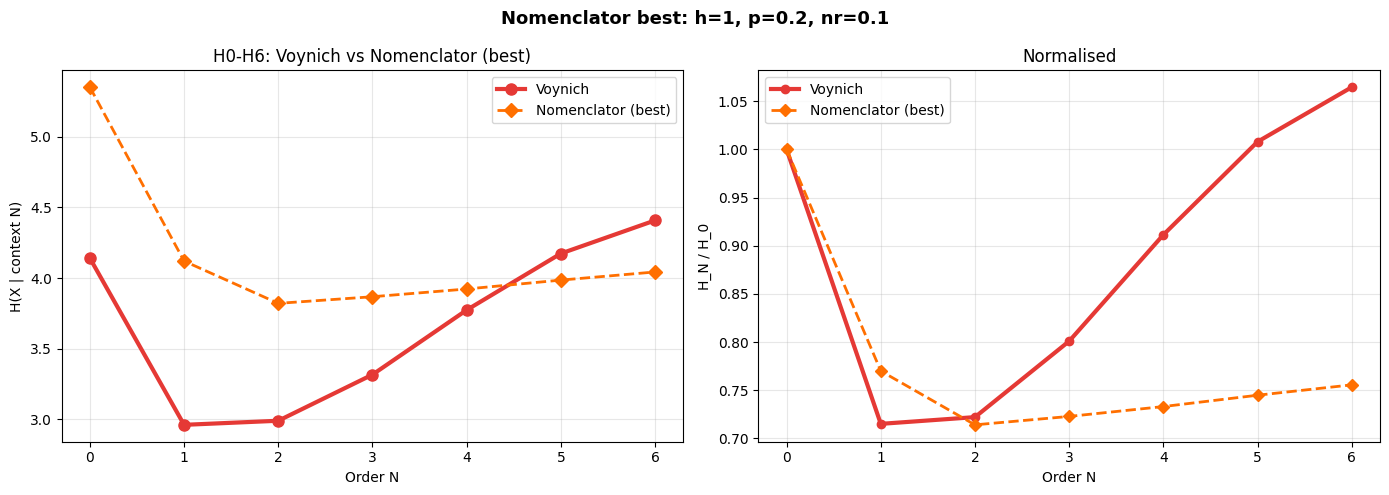

Saved: nomenclator_mejor.png


In [20]:
# ── Cell 23: Best Nomenclator — full analysis H0-H6 ──────────
best_nom = nom_sweep_results[0]
print(f'Best Nomenclator: n_h={best_nom["n_homophones"]}, '
      f'p_nom={best_nom["p_nom_use"]}, null={best_nom["null_rate"]}, '
      f'distance={best_nom["distance"]:.3f}')

# Regenerate
nom_best_words, _, _ = generar_nomenclator(
    plaintext_words_latin, GLYPH_VOCAB_200,
    n_homophones=best_nom['n_homophones'],
    n_nomenclature=50,
    p_nom_use=best_nom['p_nom_use'],
    null_rate=best_nom['null_rate'],
    seed=42
)
nom_best_flat = [g for p in nom_best_words for g in p]

# H0-H6
print('\nH0-H6:')
H_nom_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(nom_best_flat, n)
    H_nom_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral + MI
M_nb, toks_nb, _ = construir_matriz_transicion(nom_best_words)
spec_nb = analisis_espectral(M_nb, 'Nomenclator (best)')
mi_p_nb = mutual_information(nom_best_words)
mi_b_nb = mutual_information_bigram(nom_best_words)
print(f'MI_pos = {mi_p_nb:.4f}, MI_big = {mi_b_nb:.4f}')

# Save figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(ordenes_ext, VOYNICH_TARGET['H_curve'], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich')
ax1.plot(ordenes_ext, H_nom_ext, 'D--',
         color=COLOR_MAP['Nomenclator'], lw=2, markersize=7, label='Nomenclator (best)')
ax1.set_xlabel('Order N')
ax1.set_ylabel('H(X | context N)')
ax1.set_title('H0-H6: Voynich vs Nomenclator (best)')
ax1.legend()
ax1.grid(True, alpha=0.3)

norm_nb = [v / H_nom_ext[0] for v in H_nom_ext]
ax2.plot(ordenes_ext, norm_v, 'o-', color=COLOR_MAP['Voynich'], lw=3, label='Voynich')
ax2.plot(ordenes_ext, norm_nb, 'D--', color=COLOR_MAP['Nomenclator'], lw=2, label='Nomenclator (best)')
ax2.set_xlabel('Order N')
ax2.set_ylabel('H_N / H_0')
ax2.set_title('Normalised')
ax2.legend()
ax2.grid(True, alpha=0.3)

fig.suptitle(f'Nomenclator best: h={best_nom["n_homophones"]}, '
             f'p={best_nom["p_nom_use"]}, nr={best_nom["null_rate"]}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/nomenclator_mejor.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: nomenclator_mejor.png')

## Model 4: Slot+Markov hybrid

The independent slots model (Model 1) produces a bounce but has low bigram MI (0.62 vs 1.68 for the Voynich). Voynich glyphs show strong dependencies between adjacent positions that pure slots do not capture.

**Idea**: Combine the slot positional distribution with a Markov chain that conditions the current glyph on the previous one.

$$P(g_i | pos=i, g_{i-1}) = (1-\alpha) \cdot P_{slot}(g_i | pos=i) + \alpha \cdot P_{trans}(g_i | g_{i-1})$$

- `alpha=0` → pure slot (Model 1)
- `alpha=1` → pure Markov (no positional structure)
- intermediate `alpha` → hybrid capturing both positional preference and local dependencies

**Parameters:** `tau` (slot temperature), `alpha` (Markov weight), `noise` (uniform break)

**Prediction:** Should maintain the slot bounce (low H1 from slots, H2+ rises from inter-word independence) but with higher MI_big (the Markov component creates dependencies between adjacent glyphs).

In [21]:
# ── Cell 25: Model generator Slot+Markov hybrid ─────────────

def extraer_trans_matrix(palabras, vocab):
    """
    Extracts empirical transition matrix P(g_next | g_prev) from the corpus.
    Returns dict[glyph_prev, np.array of probs aligned with vocab].
    """
    V = len(vocab)
    g2i = {g: i for i, g in enumerate(vocab)}
    counts = np.zeros((V, V))
    for palabra in palabras:
        for j in range(len(palabra) - 1):
            a, b = palabra[j], palabra[j + 1]
            if a in g2i and b in g2i:
                counts[g2i[a], g2i[b]] += 1
    # Normalize rows with Laplace smoothing
    counts += 1e-6
    row_sums = counts.sum(axis=1, keepdims=True)
    trans = counts / row_sums
    # Return as dict for quick access
    trans_dict = {}
    for g in vocab:
        trans_dict[g] = trans[g2i[g]]
    return trans_dict


def generar_slot_markov(pos_probs, trans_probs, wlen_dist, tau, alpha, noise,
                         vocab, n_words, seed=42):
    """
    Slot+Markov hybrid: mixture of positional distribution with Markov transition.
    
    P(g_i | pos, g_{i-1}) = (1-alpha) * P_slot(g|pos, tau) + alpha * P_trans(g|g_{i-1})
    
    alpha=0 → slot pure, alpha=1 → Markov pure.
    """
    rng = np.random.RandomState(seed)
    vocab_arr = np.array(vocab)
    V = len(vocab)
    
    # Length distribution
    wlens = sorted(wlen_dist.keys())
    wlen_probs = np.array([wlen_dist[l] for l in wlens])
    
    # Slot distributions 
    pos_dist_cache = {}
    for pos, glyph_probs in pos_probs.items():
        probs = np.array([glyph_probs.get(g, 1e-10) for g in vocab])
        probs = np.maximum(probs, 1e-10)
        log_probs = np.log(probs) / tau
        log_probs -= log_probs.max()
        tempered = np.exp(log_probs)
        tempered /= tempered.sum()
        pos_dist_cache[pos] = tempered
    
    uniform = np.ones(V) / V
    
    palabras = []
    for _ in range(n_words):
        wlen = rng.choice(wlens, p=wlen_probs)
        palabra = []
        prev_glyph = None
        
        for pos in range(wlen):
            if rng.random() < noise:
                g = vocab_arr[rng.choice(V)]
            else:
                # Slot distribution
                if pos in pos_dist_cache:
                    p_slot = pos_dist_cache[pos]
                else:
                    fallback = max((p for p in pos_dist_cache if p <= pos), default=min(pos_dist_cache.keys()))
                    p_slot = pos_dist_cache[fallback]
                
                if prev_glyph is not None and alpha > 0:
                    # Mix slot + Markov
                    p_trans = trans_probs[prev_glyph]
                    p_combined = (1 - alpha) * p_slot + alpha * p_trans
                    p_combined /= p_combined.sum()
                    g = vocab_arr[rng.choice(V, p=p_combined)]
                else:
                    # Position 0 o alpha=0: slot pure
                    g = vocab_arr[rng.choice(V, p=p_slot)]
            
            palabra.append(g)
            prev_glyph = g
        
        palabras.append(palabra)
    
    return palabras


# Extract empirical transition matrix of the Voynich
trans_voynich = extraer_trans_matrix(palabras_voynich, VOCAB_VOYNICH)
print(f'Extracted transition matrix: {len(trans_voynich)} entries')
print('generar_slot_markov OK')

Extracted transition matrix: 166 entries
generar_slot_markov OK


In [22]:
# ── Cell 26: Sweep Slot+Markov (parallel) ─────────────────────────
taus_h   = [0.3, 0.5, 0.7, 1.0]
alphas_h = [0.1, 0.3, 0.5, 0.7, 0.9]
noises_h = [0.0, 0.05]

configs = [(tau, alpha, noise) for tau in taus_h for alpha in alphas_h for noise in noises_h]
print(f'Sweep Hybrid: {len(configs)} configurations ({N_CPUS} workers)')

def _hybrid_worker(args):
    tau, alpha, noise = args
    words = generar_slot_markov(
        pos_probs, trans_voynich, wlen_dist,
        tau=tau, alpha=alpha, noise=noise,
        vocab=VOCAB_VOYNICH, n_words=N_VOYNICH, seed=42)
    m = compute_metrics_from_words(words, f't={tau},a={alpha},n={noise}')
    m.update({'tau': tau, 'alpha': alpha, 'noise': noise})
    m['distance'] = voynich_distance(m, VOYNICH_TARGET)
    return m

with Pool(N_CPUS) as pool:
    hybrid_sweep_results = pool.map(_hybrid_worker, configs)

hybrid_sweep_results.sort(key=lambda x: x['distance'])
print(f'\nTop-10 Hybrid:')
print(f'{"tau":>5} {"alpha":>6} {"noise":>6} {"dist":>7} {"bounce":>8} '
      f'{"decay":>7} {"MI_pos":>7} {"MI_big":>7}')
for r in hybrid_sweep_results[:10]:
    print(f'{r["tau"]:>5.1f} {r["alpha"]:>6.1f} {r["noise"]:>6.2f} '
          f'{r["distance"]:>7.3f} {r["rebote"]:>8.3f} {r["decay"]:>7.3f} '
          f'{r["MI_pos"]:>7.3f} {r["MI_big"]:>7.3f}')


Sweep Hybrid: 40 configurations (15 workers)

Top-10 Hybrid:
  tau  alpha  noise    dist   bounce   decay  MI_pos  MI_big
  0.3    0.9   0.00   0.783    0.957  -0.069   0.400   1.178
  0.3    0.9   0.05   0.842    1.065  -0.087   0.370   1.214
  0.5    0.9   0.00   0.881    1.021  -0.087   0.310   1.176
  0.5    0.9   0.05   0.896    1.069  -0.088   0.287   1.211
  0.7    0.9   0.05   0.930    1.052  -0.086   0.227   1.200
  1.0    0.9   0.05   0.954    1.012  -0.077   0.170   1.181
  0.7    0.9   0.00   0.970    1.062  -0.100   0.244   1.159
  0.3    0.7   0.00   1.120    0.943  -0.127   0.394   0.881
  1.0    0.9   0.00   1.122    1.171  -0.130   0.186   1.139
  0.3    0.7   0.05   1.131    1.032  -0.137   0.365   0.910


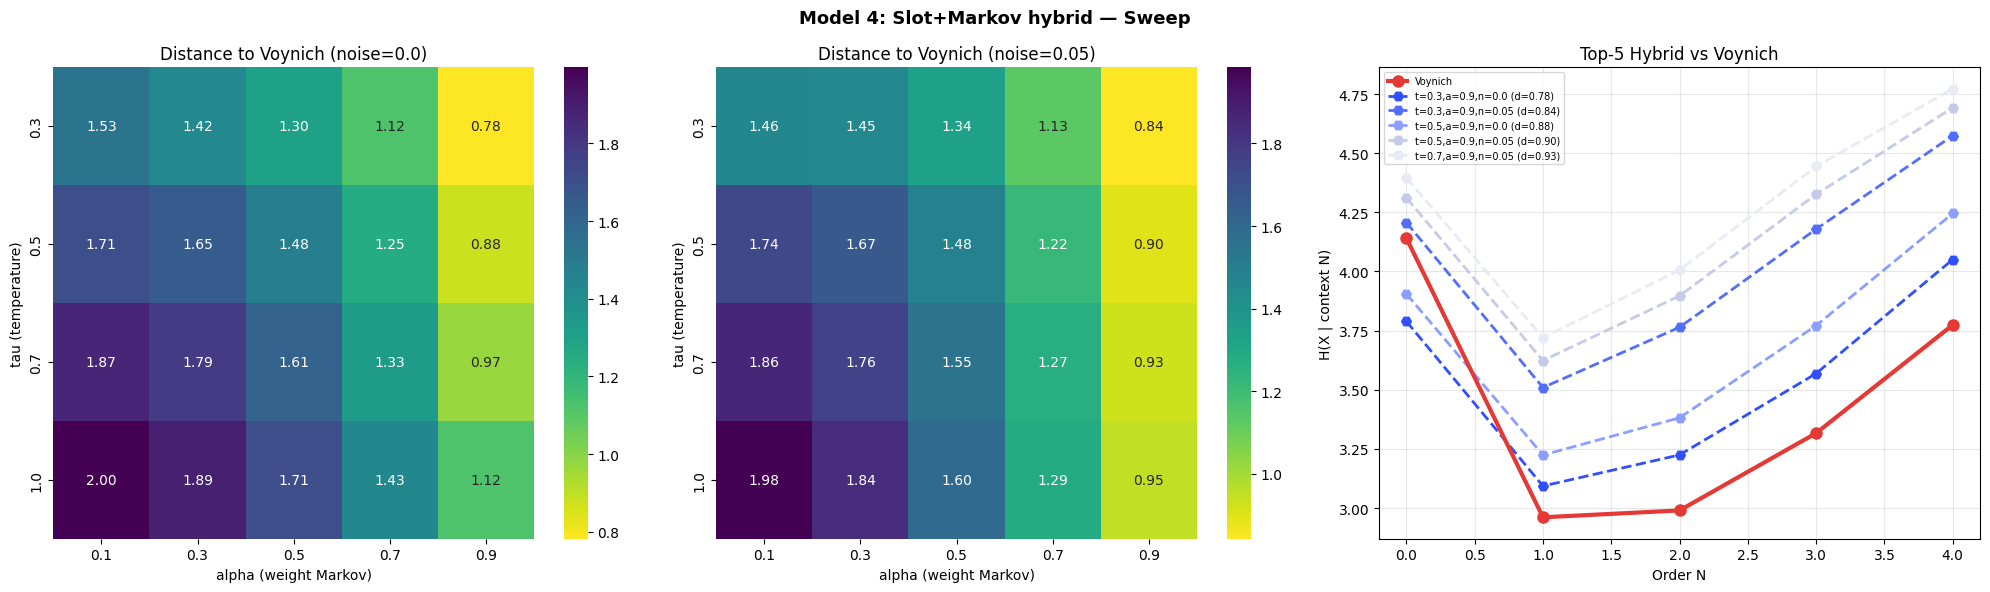

Saved: hybrid_sweep.png


In [23]:
# ── Cell 27: Visualisation sweep Hybrid ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Panel A: Heatmap tau x alpha (noise=0.0) colored by distance
ax = axes[0]
dist_matrix_h = np.full((len(taus_h), len(alphas_h)), np.nan)
for r in hybrid_sweep_results:
    if r['noise'] == 0.0:
        i = taus_h.index(r['tau'])
        j = alphas_h.index(r['alpha'])
        dist_matrix_h[i, j] = r['distance']
sns.heatmap(dist_matrix_h, ax=ax, annot=True, fmt='.2f', cmap='viridis_r',
            xticklabels=[f'{a:.1f}' for a in alphas_h],
            yticklabels=[f'{t:.1f}' for t in taus_h])
ax.set_xlabel('alpha (weight Markov)')
ax.set_ylabel('tau (temperature)')
ax.set_title('Distance to Voynich (noise=0.0)')

# Panel B: Heatmap tau x alpha (noise=0.05)
ax = axes[1]
dist_matrix_h2 = np.full((len(taus_h), len(alphas_h)), np.nan)
for r in hybrid_sweep_results:
    if r['noise'] == 0.05:
        i = taus_h.index(r['tau'])
        j = alphas_h.index(r['alpha'])
        dist_matrix_h2[i, j] = r['distance']
sns.heatmap(dist_matrix_h2, ax=ax, annot=True, fmt='.2f', cmap='viridis_r',
            xticklabels=[f'{a:.1f}' for a in alphas_h],
            yticklabels=[f'{t:.1f}' for t in taus_h])
ax.set_xlabel('alpha (weight Markov)')
ax.set_ylabel('tau (temperature)')
ax.set_title('Distance to Voynich (noise=0.05)')

# Panel C: H0-H4 curves top-5 vs Voynich
ax = axes[2]
ax.plot([0,1,2,3,4], VOYNICH_TARGET['H_curve'][:5], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich', zorder=10)
top5_colors = ['#304FFE', '#536DFE', '#8C9EFF', '#C5CAE9', '#E8EAF6']
for idx, r in enumerate(hybrid_sweep_results[:5]):
    label = (f't={r["tau"]},a={r["alpha"]},n={r["noise"]} '
             f'(d={r["distance"]:.2f})')
    ax.plot([0,1,2,3,4], r['H_curve'], 'H--', color=top5_colors[idx],
             lw=2, markersize=7, label=label)
ax.set_xlabel('Order N')
ax.set_ylabel('H(X | context N)')
ax.set_title('Top-5 Hybrid vs Voynich')
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

fig.suptitle('Model 4: Slot+Markov hybrid — Sweep', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/hybrid_sweep.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: hybrid_sweep.png')

Best Hybrid: tau=0.3, alpha=0.9, noise=0.0, distance=0.783

H0-H6:
  H0 = 3.7893
  H1 = 3.0930
  H2 = 3.2245
  H3 = 3.5686
  H4 = 4.0504
  H5 = 4.3976
  H6 = 4.4262
MI_pos = 0.4000, MI_big = 1.1779

--- Comparison Voynich vs Hybrid ---
Metric          Voynich     Hybrid      Delta
--------------------------------------------
Bounce           0.8131     0.9574    +0.1443
Decay            0.0886    -0.0689    -0.1575
MI_pos           0.6578     0.4000    -0.2578
MI_big           1.6811     1.1779    -0.5033
Gap              0.5406     0.6847    +0.1441


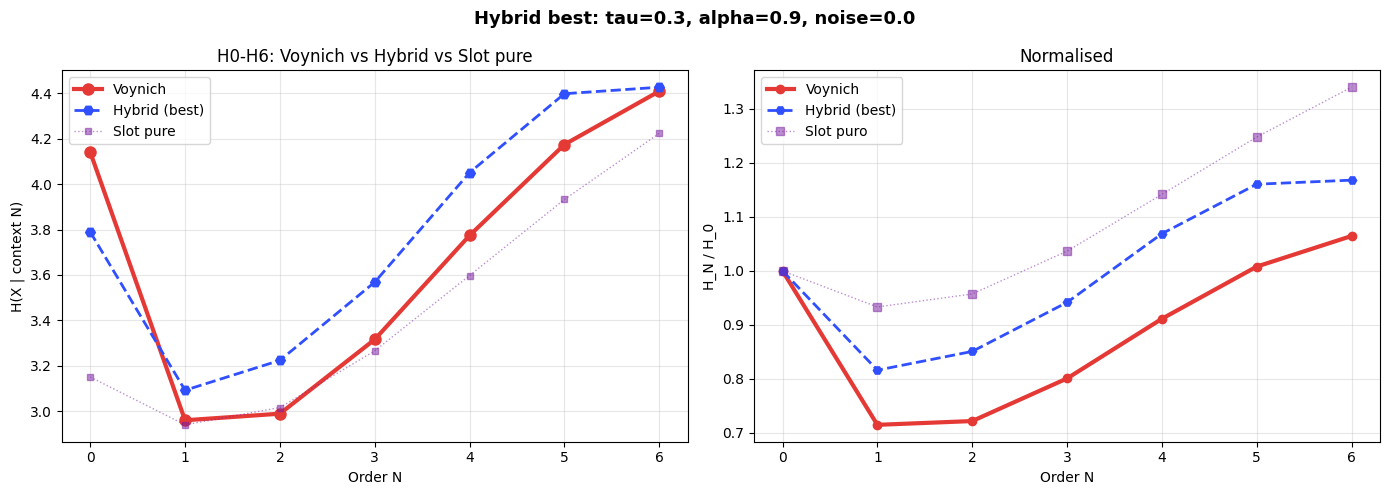

Saved: hybrid_mejor.png


In [24]:
# ── Cell 28: Best Hybrid — full analysis H0-H6 ────────────────
best_hybrid = hybrid_sweep_results[0]
print(f'Best Hybrid: tau={best_hybrid["tau"]}, alpha={best_hybrid["alpha"]}, '
      f'noise={best_hybrid["noise"]}, distance={best_hybrid["distance"]:.3f}')

# Regenerate
hybrid_best_words = generar_slot_markov(
    pos_probs, trans_voynich, wlen_dist,
    tau=best_hybrid['tau'], alpha=best_hybrid['alpha'],
    noise=best_hybrid['noise'],
    vocab=VOCAB_VOYNICH, n_words=N_VOYNICH, seed=42
)
hybrid_best_flat = [g for p in hybrid_best_words for g in p]

# H0-H6
print('\nH0-H6:')
H_hybrid_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(hybrid_best_flat, n)
    H_hybrid_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral + MI
M_hyb, toks_hyb, _ = construir_matriz_transicion(hybrid_best_words)
spec_hyb = analisis_espectral(M_hyb, 'Hybrid (best)')
mi_p_hyb = mutual_information(hybrid_best_words)
mi_b_hyb = mutual_information_bigram(hybrid_best_words)
print(f'MI_pos = {mi_p_hyb:.4f}, MI_big = {mi_b_hyb:.4f}')

# Direct comparison
print('\n--- Comparison Voynich vs Hybrid ---')
print(f'{"Metric":<12} {"Voynich":>10} {"Hybrid":>10} {"Delta":>10}')
print('-' * 44)
h_mc = metricas_curva('Hybrid', H_hybrid_ext[:5], [0,1,2,3,4])
h_decay = (H_hybrid_ext[0] - H_hybrid_ext[4]) / H_hybrid_ext[0]
comparisons = [
    ('Bounce', VOYNICH_TARGET['rebote'], h_mc['rebote']),
    ('Decay', VOYNICH_TARGET['decay'], h_decay),
    ('MI_pos', VOYNICH_TARGET['MI_pos'], mi_p_hyb),
    ('MI_big', VOYNICH_TARGET['MI_big'], mi_b_hyb),
    ('Gap', VOYNICH_TARGET['gap'], spec_hyb['gap']),
]
for name, vv, hv in comparisons:
    print(f'{name:<12} {vv:>10.4f} {hv:>10.4f} {hv-vv:>+10.4f}')

# Save figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(ordenes_ext, VOYNICH_TARGET['H_curve'], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich')
ax1.plot(ordenes_ext, H_hybrid_ext, 'H--',
         color=COLOR_MAP['Hybrid'], lw=2, markersize=7, label='Hybrid (best)')
# Incluir Slot puro as referencia
ax1.plot(ordenes_ext, H_slot_ext, 's:',
         color=COLOR_MAP['Slot'], lw=1, markersize=5, alpha=0.5, label='Slot pure')
ax1.set_xlabel('Order N')
ax1.set_ylabel('H(X | context N)')
ax1.set_title('H0-H6: Voynich vs Hybrid vs Slot pure')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Normalised
norm_v = [v / VOYNICH_TARGET['H_curve'][0] for v in VOYNICH_TARGET['H_curve']]
norm_hyb = [v / H_hybrid_ext[0] for v in H_hybrid_ext]
norm_sl = [v / H_slot_ext[0] for v in H_slot_ext]
ax2.plot(ordenes_ext, norm_v, 'o-', color=COLOR_MAP['Voynich'], lw=3, label='Voynich')
ax2.plot(ordenes_ext, norm_hyb, 'H--', color=COLOR_MAP['Hybrid'], lw=2, label='Hybrid (best)')
ax2.plot(ordenes_ext, norm_sl, 's:', color=COLOR_MAP['Slot'], lw=1, alpha=0.5, label='Slot puro')
ax2.set_xlabel('Order N')
ax2.set_ylabel('H_N / H_0')
ax2.set_title('Normalised')
ax2.legend()
ax2.grid(True, alpha=0.3)

fig.suptitle(f'Hybrid best: tau={best_hybrid["tau"]}, alpha={best_hybrid["alpha"]}, '
             f'noise={best_hybrid["noise"]}', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/hybrid_mejor.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: hybrid_mejor.png')

## Model 5: Polyalphabetic nomenclator

A historically plausible 15th-century cipher. Combines a nomenclator (homophones + n-gram codebook) with a **periodic table shift**, inspired by the Alberti cipher disk (1467).

**Mechanism:**
1. A base nomenclator is built: each plaintext letter maps to one or more glyphs (homophones), and frequent bigrams/trigrams have their own multi-glyph codes
2. Every `shift_period` words, the glyph table is **rotated** by `shift_amount` positions: glyph G005 becomes G010, etc.
3. Within each period the structure is coherent (same transition rules) → high MI_pos and MI_big
4. Crossing the period boundary, the previous context is no longer useful (different table) → H2+ rises → **bounce**

**Parameters:** `shift_period` (words between shifts), `shift_amount` (shift magnitude), `n_homophones`

**Prediction:** If the period is ~1 word, it should produce a strong bounce + high intra-word MI. This is the model with the highest historical plausibility (15th century).

In [25]:
# ── Cell 30:Polyalphabetic Nomenclator Generator ───────────────

def generar_nompoly(plaintext_words, glyph_vocab, n_homophones, n_nomenclature,
                     p_nom_use, null_rate, shift_period, shift_amount, seed=42):
    """
   Polyalphabetic nomenclator: base nomenclator + periodic displacement.
    
    Every shift_period words, the glyph table rotates shift_amount positions.
    Within each period the rules are coherent; when crossing period
    context is broken.
    """
    rng = np.random.RandomState(seed)
    V_glyph = len(glyph_vocab)
    
    # 1. Build base nomenclator using INDEXES (not glyphs directly)
    pt_chars = sorted(set(c for w in plaintext_words for c in w))
    glyph_idx = 0
    homo_table = {}  # char → index list in glyph_vocab
    for ch in pt_chars:
        homos = []
        for _ in range(n_homophones):
            homos.append(glyph_idx % V_glyph)
            glyph_idx += 1
        homo_table[ch] = homos
    
    # 2. Codebook for frequent bigrams/trigrams
    bigram_freq = Counter()
    trigram_freq = Counter()
    for w in plaintext_words:
        for i in range(len(w) - 1):
            bigram_freq[tuple(w[i:i+2])] += 1
        for i in range(len(w) - 2):
            trigram_freq[tuple(w[i:i+3])] += 1
    
    candidates = ([(ng, f) for ng, f in bigram_freq.most_common(n_nomenclature * 2)] +
                  [(ng, f) for ng, f in trigram_freq.most_common(n_nomenclature * 2)])
    candidates.sort(key=lambda x: -x[1])
    
    nom_entries = {}  # tuple(chars) → tuple(indices)
    used_codes = set()
    for ng, _ in candidates[:n_nomenclature]:
        code_len = rng.choice([2, 3])
        while True:
            code = tuple((glyph_idx + k) % V_glyph for k in range(code_len))
            glyph_idx += code_len
            if code not in used_codes:
                used_codes.add(code)
                nom_entries[ng] = code
                break
    
    null_indices = [(V_glyph - 1 - k) % V_glyph for k in range(5)]
    
    # 3. Encode word by word with periodic shifting
    output_palabras = []
    for word_num, word in enumerate(plaintext_words):
        # Compute shift for this word
        period_num = word_num // shift_period
        shift = (period_num * shift_amount) % V_glyph
        
        glyph_word = []
        i = 0
        while i < len(word):
            used_nom = False
            # Attempt codebook
            if p_nom_use > 0:
                for ng_len in [3, 2]:
                    if i + ng_len <= len(word):
                        ng = tuple(word[i:i + ng_len])
                        if ng in nom_entries and rng.random() < p_nom_use:
                            for gi in nom_entries[ng]:
                                shifted = (gi + shift) % V_glyph
                                glyph_word.append(glyph_vocab[shifted])
                            i += ng_len
                            used_nom = True
                            break
            
            if not used_nom:
                ch = word[i]
                if ch in homo_table:
                    gi = homo_table[ch][rng.randint(len(homo_table[ch]))]
                    shifted = (gi + shift) % V_glyph
                    glyph_word.append(glyph_vocab[shifted])
                i += 1
            
            # Insert null
            if null_rate > 0 and rng.random() < null_rate:
                ni = null_indices[rng.randint(len(null_indices))]
                shifted = (ni + shift) % V_glyph
                glyph_word.append(glyph_vocab[shifted])
        
        if glyph_word:
            output_palabras.append(glyph_word)
    
    return output_palabras


print('generar_nompoly OK')

generar_nompoly OK


In [26]:
# ── Cell 31: Sweep Nomenclator Polyalphabetic (parallel) ──────────
shift_periods = [1, 3, 7, 15]
shift_amounts = [5, 15, 40, 80]
n_homos_np    = [1, 3]

FIXED_NOM  = 50
FIXED_PNOM = 0.2
FIXED_NULL = 0.05

configs = [(sp, sa, nh) for sp in shift_periods for sa in shift_amounts for nh in n_homos_np]
print(f'Sweep NomPoly: {len(configs)} configurations ({N_CPUS} workers)')

def _nompoly_worker(args):
    sp, sa, nh = args
    words = generar_nompoly(
        plaintext_words_latin, GLYPH_VOCAB_200,
        n_homophones=nh, n_nomenclature=FIXED_NOM,
        p_nom_use=FIXED_PNOM, null_rate=FIXED_NULL,
        shift_period=sp, shift_amount=sa, seed=42)
    flat = [g for p in words for g in p]
    if len(flat) < 100:
        return None
    m = compute_metrics_from_words(words, f'sp={sp},sa={sa},nh={nh}')
    m.update({'shift_period': sp, 'shift_amount': sa, 'n_homophones': nh})
    m['distance'] = voynich_distance(m, VOYNICH_TARGET)
    return m

with Pool(N_CPUS) as pool:
    nompoly_sweep_results = [r for r in pool.map(_nompoly_worker, configs) if r is not None]

nompoly_sweep_results.sort(key=lambda x: x['distance'])
print(f'\nTop-10 NomPoly:')
print(f'{"period":>7} {"shift":>6} {"n_h":>5} {"dist":>7} {"bounce":>8} '
      f'{"decay":>7} {"MI_pos":>7} {"MI_big":>7} {"vocab":>6}')
for r in nompoly_sweep_results[:10]:
    print(f'{r["shift_period"]:>7} {r["shift_amount"]:>6} {r["n_homophones"]:>5} '
          f'{r["distance"]:>7.3f} {r["rebote"]:>8.3f} {r["decay"]:>7.3f} '
          f'{r["MI_pos"]:>7.3f} {r["MI_big"]:>7.3f} {r["vocab"]:>6}')


Sweep NomPoly: 32 configurations (15 workers)

Top-10 NomPoly:
 period  shift   n_h    dist   bounce   decay  MI_pos  MI_big  vocab
      3     80     3   1.637    0.000   0.351   0.120   1.968    200
      7     80     3   1.637    0.000   0.351   0.120   1.966    200
      1     40     3   1.637    0.000   0.351   0.120   1.969    200
      7     40     3   1.638    0.000   0.351   0.121   1.966    200
      1     80     3   1.638    0.000   0.351   0.121   1.969    200
     15     80     3   1.638    0.000   0.351   0.120   1.966    200
      3     40     3   1.638    0.000   0.351   0.120   1.968    200
     15     40     3   1.638    0.000   0.351   0.120   1.966    200
      1      5     3   1.733    0.000   0.370   0.005   1.297    200
      1     15     3   1.733    0.000   0.370   0.005   1.297    200


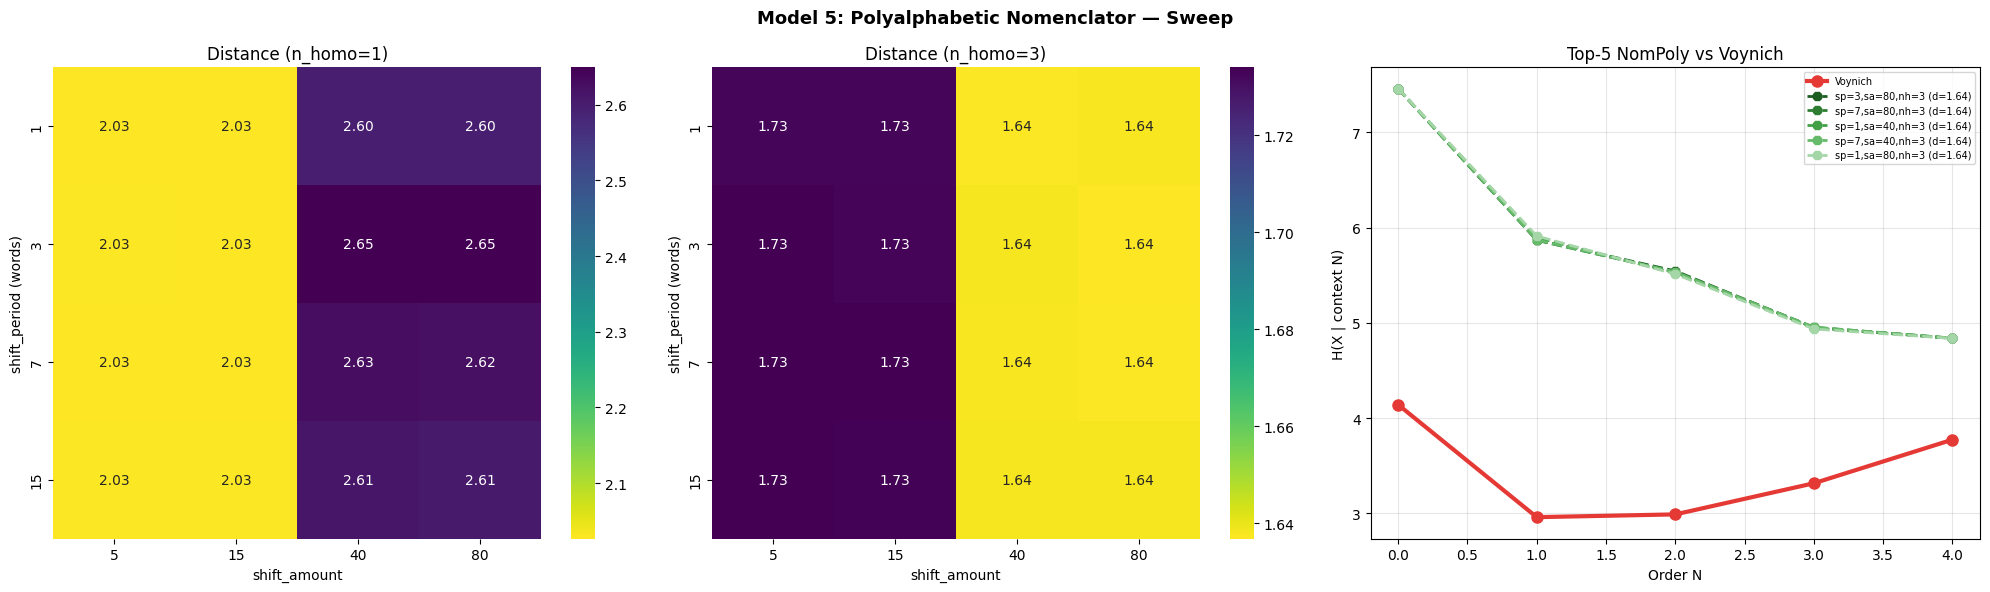

Saved: nompoly_sweep.png


In [27]:
# ── Cell 32: Visualisation sweep NomPoly ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Panel A: Heatmap period x shift_amount (n_homophones=1)
ax = axes[0]
dist_mat = np.full((len(shift_periods), len(shift_amounts)), np.nan)
for r in nompoly_sweep_results:
    if r['n_homophones'] == 1:
        i = shift_periods.index(r['shift_period'])
        j = shift_amounts.index(r['shift_amount'])
        dist_mat[i, j] = r['distance']
sns.heatmap(dist_mat, ax=ax, annot=True, fmt='.2f', cmap='viridis_r',
            xticklabels=[str(s) for s in shift_amounts],
            yticklabels=[str(s) for s in shift_periods])
ax.set_xlabel('shift_amount')
ax.set_ylabel('shift_period (words)')
ax.set_title('Distance (n_homo=1)')

# Panel B: Heatmap period x shift_amount (n_homophones=3)
ax = axes[1]
dist_mat2 = np.full((len(shift_periods), len(shift_amounts)), np.nan)
for r in nompoly_sweep_results:
    if r['n_homophones'] == 3:
        i = shift_periods.index(r['shift_period'])
        j = shift_amounts.index(r['shift_amount'])
        dist_mat2[i, j] = r['distance']
sns.heatmap(dist_mat2, ax=ax, annot=True, fmt='.2f', cmap='viridis_r',
            xticklabels=[str(s) for s in shift_amounts],
            yticklabels=[str(s) for s in shift_periods])
ax.set_xlabel('shift_amount')
ax.set_ylabel('shift_period (words)')
ax.set_title('Distance (n_homo=3)')

# Panel C: Top-5 curves vs Voynich
ax = axes[2]
ax.plot([0,1,2,3,4], VOYNICH_TARGET['H_curve'][:5], 'o-',
        color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich', zorder=10)
top5_greens = ['#1B5E20', '#2E7D32', '#43A047', '#66BB6A', '#A5D6A7']
for idx, r in enumerate(nompoly_sweep_results[:5]):
    label = (f'sp={r["shift_period"]},sa={r["shift_amount"]},nh={r["n_homophones"]} '
             f'(d={r["distance"]:.2f})')
    ax.plot([0,1,2,3,4], r['H_curve'], '8--', color=top5_greens[idx],
            lw=2, markersize=7, label=label)
ax.set_xlabel('Order N')
ax.set_ylabel('H(X | context N)')
ax.set_title('Top-5 NomPoly vs Voynich')
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

fig.suptitle('Model 5: Polyalphabetic Nomenclator — Sweep', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/nompoly_sweep.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: nompoly_sweep.png')

Best NomPoly: period=3, shift=80, n_h=3, distance=1.637

H0-H6:
  H0 = 7.4583
  H1 = 5.8721
  H2 = 5.5457
  H3 = 4.9515
  H4 = 4.8376
  H5 = 4.8041
  H6 = 4.8009
MI_pos = 0.1204, MI_big = 1.9683

--- Comparison Voynich vs NomPoly vs Hybrid ---
Metric          Voynich     Hybrid    NomPoly
--------------------------------------------
Bounce           0.8131     0.9574     0.0000
Decay            0.0886    -0.0689     0.3514
MI_pos           0.6578     0.4000     0.1204
MI_big           1.6811     1.1779     1.9683
Gap              0.5406     0.6847     0.5072


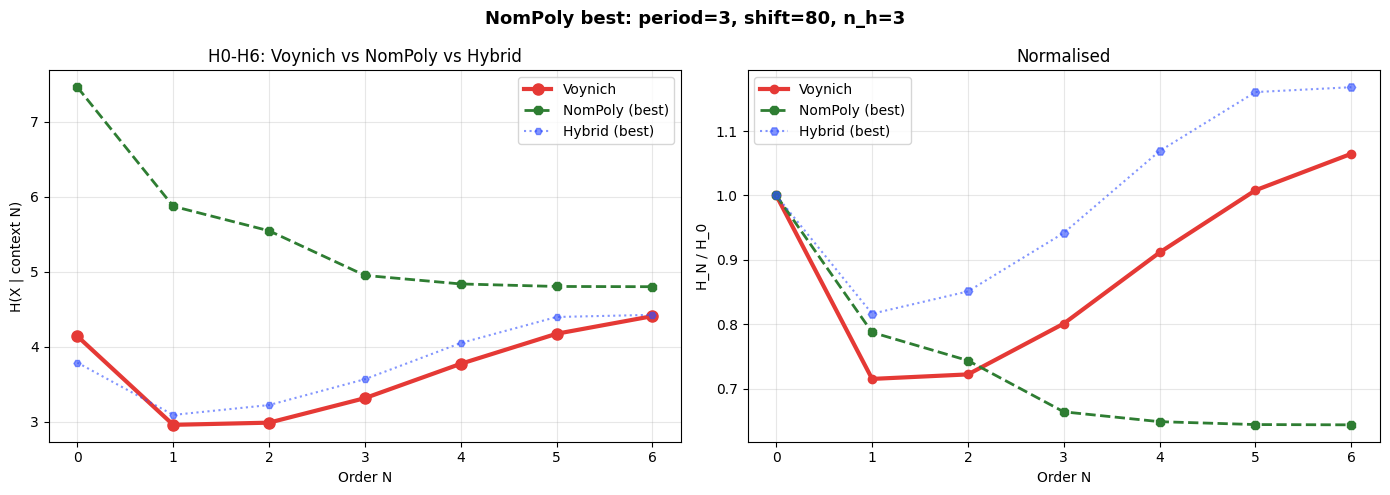

Saved: nompoly_mejor.png


In [28]:
# ── Cell 33: Best NomPoly — full analysis H0-H6 ────────────────
best_np = nompoly_sweep_results[0]
print(f'Best NomPoly: period={best_np["shift_period"]}, shift={best_np["shift_amount"]}, '
      f'n_h={best_np["n_homophones"]}, distance={best_np["distance"]:.3f}')

# Regenerate
nompoly_best_words = generar_nompoly(
    plaintext_words_latin, GLYPH_VOCAB_200,
    n_homophones=best_np['n_homophones'], n_nomenclature=FIXED_NOM,
    p_nom_use=FIXED_PNOM, null_rate=FIXED_NULL,
    shift_period=best_np['shift_period'], shift_amount=best_np['shift_amount'],
    seed=42
)
nompoly_best_flat = [g for p in nompoly_best_words for g in p]

# H0-H6
print('\nH0-H6:')
H_nompoly_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(nompoly_best_flat, n)
    H_nompoly_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral + MI
M_npy, toks_npy, _ = construir_matriz_transicion(nompoly_best_words)
spec_npy = analisis_espectral(M_npy, 'NomPoly (best)')
mi_p_npy = mutual_information(nompoly_best_words)
mi_b_npy = mutual_information_bigram(nompoly_best_words)
print(f'MI_pos = {mi_p_npy:.4f}, MI_big = {mi_b_npy:.4f}')

# Direct comparison
print('\n--- Comparison Voynich vs NomPoly vs Hybrid ---')
print(f'{"Metric":<12} {"Voynich":>10} {"Hybrid":>10} {"NomPoly":>10}')
print('-' * 44)
np_mc = metricas_curva('NomPoly', H_nompoly_ext[:5], [0,1,2,3,4])
np_decay = (H_nompoly_ext[0] - H_nompoly_ext[4]) / H_nompoly_ext[0]
h_mc = metricas_curva('Hybrid', H_hybrid_ext[:5], [0,1,2,3,4])
h_decay = (H_hybrid_ext[0] - H_hybrid_ext[4]) / H_hybrid_ext[0]
comparisons = [
    ('Bounce', VOYNICH_TARGET['rebote'], h_mc['rebote'], np_mc['rebote']),
    ('Decay', VOYNICH_TARGET['decay'], h_decay, np_decay),
    ('MI_pos', VOYNICH_TARGET['MI_pos'], mi_p_hyb, mi_p_npy),
    ('MI_big', VOYNICH_TARGET['MI_big'], mi_b_hyb, mi_b_npy),
    ('Gap', VOYNICH_TARGET['gap'], spec_hyb['gap'], spec_npy['gap']),
]
for name, vv, hv, npv in comparisons:
    print(f'{name:<12} {vv:>10.4f} {hv:>10.4f} {npv:>10.4f}')

# Save figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(ordenes_ext, VOYNICH_TARGET['H_curve'], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich')
ax1.plot(ordenes_ext, H_nompoly_ext, '8--',
         color=COLOR_MAP['NomPoly'], lw=2, markersize=7, label='NomPoly (best)')
ax1.plot(ordenes_ext, H_hybrid_ext, 'H:',
         color=COLOR_MAP['Hybrid'], lw=1.5, markersize=5, alpha=0.6, label='Hybrid (best)')
ax1.set_xlabel('Order N')
ax1.set_ylabel('H(X | context N)')
ax1.set_title('H0-H6: Voynich vs NomPoly vs Hybrid')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Normalised
norm_v = [v / VOYNICH_TARGET['H_curve'][0] for v in VOYNICH_TARGET['H_curve']]
norm_npy = [v / H_nompoly_ext[0] for v in H_nompoly_ext]
norm_hyb = [v / H_hybrid_ext[0] for v in H_hybrid_ext]
ax2.plot(ordenes_ext, norm_v, 'o-', color=COLOR_MAP['Voynich'], lw=3, label='Voynich')
ax2.plot(ordenes_ext, norm_npy, '8--', color=COLOR_MAP['NomPoly'], lw=2, label='NomPoly (best)')
ax2.plot(ordenes_ext, norm_hyb, 'H:', color=COLOR_MAP['Hybrid'], lw=1.5, alpha=0.6, label='Hybrid (best)')
ax2.set_xlabel('Order N')
ax2.set_ylabel('H_N / H_0')
ax2.set_title('Normalised')
ax2.legend()
ax2.grid(True, alpha=0.3)

fig.suptitle(f'NomPoly best: period={best_np["shift_period"]}, shift={best_np["shift_amount"]}, '
             f'n_h={best_np["n_homophones"]}', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/nompoly_mejor.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: nompoly_mejor.png')

## Model 6: Probabilistic syllabic generator

Evolution of the fixed syllabic model. Instead of each syllable being a deterministic glyph sequence, each **syllable type** has a *distribution* over glyphs at each internal position.

### Why the fixed syllabic model failed

With fixed syllables, knowing the first glyph determines the entire syllable → H1=0.67 (vs 2.96 for the Voynich), decay=71% (vs 8.9%). Too deterministic.

### Probabilistic syllabic mechanism

Each syllable type `t` has:
- A fixed length (1-3 glyphs)
- For each internal position: a distribution over `intra_k` preferred glyphs

The key parameter is **`intra_k`** (internal variants):
- `intra_k=1`: degenerates to fixed syllabic (very low H1)
- `intra_k=5-15`: moderate variability (region of interest)
- `intra_k=V`: uniform (no syllabic structure)

### Historical plausibility (15th century)

Compatible with: (1) natural language in a syllabary with allographic variation, (2) nomenclator with structured homophones (same code "family" per unit), (3) constructed language with morphophonological variation. Only requires pen, paper and a lookup table.

### Parameters

| Parameter | Description | Range |
|-----------|-------------|-------|
| `n_types` | Number of syllable types | 15-60 |
| `intra_k` | Preferred glyphs per internal position (variability) | 2-30 |
| `pos_bias` | Positional preference strength | 1.5-3.0 |
| `tau` | Temperature for type selection | 0.3-0.7 |

In [29]:
# -- Cell 35: Probabilistic syllabic model generator --------------------------
from scipy.stats import poisson

def generar_silabico_prob(vocab, wlen_dist, n_types, syl_len_probs, intra_k,
                          pos_bias, tau, n_words, seed=42):
    """Probabilistic syllable generator: each type of syllable has internal distributions."""
    rng = np.random.RandomState(seed)
    V = len(vocab)
    vocab_arr = np.array(vocab)

    # Phase 1: Build syllable types
    syl_lens = sorted(syl_len_probs.keys())
    syl_len_p = np.array([syl_len_probs[l] for l in syl_lens])
    syl_len_p /= syl_len_p.sum()

    types = []  # each type: (length, [dist_pos0, dist_pos1, ...])
    for _ in range(n_types):
        slen = rng.choice(syl_lens, p=syl_len_p)
        type_dists = []
        for _ in range(slen):
            # Select intra_k preferred glyphs for this position
            k = min(intra_k, V)
            selected_idx = rng.choice(V, size=k, replace=False)
            # Zipf weights: most preferred glyph gets highest weight
            weights = np.array([1.0 / (i + 1)**0.8 for i in range(k)])
            # Complete distribution on vocab (0 for unselected)
            dist = np.zeros(V)
            dist[selected_idx] = weights
            dist /= dist.sum()
            type_dists.append(dist)
        types.append((slen, type_dists))

    # Phase 2: Position-offset probabilities for types
    base_freq = np.array([1.0 / (i + 1)**0.8 for i in range(n_types)])
    base_freq /= base_freq.sum()

    group = np.zeros(n_types, dtype=int)
    g1 = n_types // 3
    g2 = 2 * n_types // 3
    group[:g1] = 0      # onset
    group[g1:g2] = 1    # middle
    group[g2:] = 2      # coda

    type_probs = {}
    for wp in [0, 1, 2]:
        logits = np.log(base_freq + 1e-12) / max(tau, 0.01)
        logits[group == wp] += pos_bias
        probs = np.exp(logits - logits.max())
        probs /= probs.sum()
        type_probs[wp] = probs

    # Phase 3: Distribution of syllables per word
    mean_syl_len = sum(l * p for l, p in syl_len_probs.items())
    mean_wlen = sum(l * p for l, p in wlen_dist.items())
    mean_n_syl = mean_wlen / mean_syl_len

    possible_ns = np.arange(1, 6)
    ns_probs = poisson.pmf(possible_ns, mu=max(mean_n_syl, 1.0))
    ns_probs /= ns_probs.sum()

    # Phase 4: Generate words
    palabras = []
    for _ in range(n_words):
        n_s = rng.choice(possible_ns, p=ns_probs)
        word = []
        for si in range(n_s):
            if n_s == 1:
                wp = 0
            elif si == 0:
                wp = 0
            elif si == n_s - 1:
                wp = 2
            else:
                wp = 1
            type_idx = rng.choice(n_types, p=type_probs[wp])
            slen, type_dists = types[type_idx]
            for pos in range(slen):
                glyph_idx = rng.choice(V, p=type_dists[pos])
                word.append(vocab_arr[glyph_idx])
        palabras.append(word)

    return palabras, types

In [30]:
# -- Cell 36: Default example + quick fingerprint ---------------------------------

print('Generating probabilistic syllabics (n_types=30, intra_k=8, pos_bias=2.0, tau=0.5)...')
syl_ejemplo, tipos_ej = generar_silabico_prob(
    VOCAB_VOYNICH, wlen_dist, n_types=30,
    syl_len_probs={1: 0.15, 2: 0.55, 3: 0.30},
    intra_k=8, pos_bias=2.0, tau=0.5,
    n_words=N_VOYNICH, seed=42
)

# Show syllable types
print(f'\nSyllable types ({len(tipos_ej)}):')
for i, (slen, dists) in enumerate(tipos_ej[:10]):
    top_glyphs = []
    for d in dists:
        top3 = np.argsort(d)[-3:][::-1]
        top_glyphs.append('/'.join(VOCAB_VOYNICH[j] for j in top3))
    print(f'  T{i:02d} (len={slen}): [{" | ".join(top_glyphs)}]')
print(f'  ...')

# Show first words
print(f'\nFirst 10 words:')
for i, w in enumerate(syl_ejemplo[:10]):
    print(f'  [{i}] {".".join(w)} (len={len(w)})')

# Basic stats
syl_flat = [g for p in syl_ejemplo for g in p]
print(f'\nWords: {len(syl_ejemplo):,}, Tokens: {len(syl_flat):,}')
print(f'Vocab effective: {len(set(syl_flat))}')
print(f'Mean length: {np.mean([len(p) for p in syl_ejemplo]):.2f} '
      f'(Voynich: {np.mean([len(p) for p in palabras_voynich]):.2f})')

# Quick fingerprint
print('\nH0-H4:')
for n in range(5):
    h = entropia_condicional_n(syl_flat, n)
    print(f'  H{n} = {h:.4f}')

mi_p_ej = mutual_information(syl_ejemplo)
mi_b_ej = mutual_information_bigram(syl_ejemplo)
print(f'MI_pos = {mi_p_ej:.4f}, MI_big = {mi_b_ej:.4f}')

Generating probabilistic syllabics (n_types=30, intra_k=8, pos_bias=2.0, tau=0.5)...

Syllable types (30):
  T00 (len=2): [Tb/To/Pe | B4/Ag/Cd]
  T01 (len=2): [E1/Qe/P1 | X2/Kc/Tg]
  T02 (len=2): [Pk/U7/E1 | Ub/E2/P1]
  T03 (len=2): [Yd/B5/Mb | Cm/T1/Kb]
  T04 (len=1): [Wq/Xe/Z1]
  T05 (len=1): [A1/Ve/Kb]
  T06 (len=2): [H1/K2/Kd | Rf/Wg/Jb]
  T07 (len=1): [Xc/Q1/K2]
  T08 (len=3): [Wn/Ul/Lp | Wr/Kj/Xc | Wk/Wb/Ab]
  T09 (len=2): [Cm/M1/Lq | V2/Rg/E1]
  ...

First 10 words:
  [0] S2 (len=1)
  [1] Aa.Rf.E1.P1 (len=4)
  [2] Ac.Ub.Pe.B4.Ki.Pc (len=6)
  [3] Ki.Eb (len=2)
  [4] Da.B4.Ki.B4.Tb.B4 (len=6)
  [5] Kb.E1.Ma.Jb.To.Cm.Rd (len=7)
  [6] T2.B4 (len=2)
  [7] Tb.Cd.Cm.Ub.Wq.Tb.Lh (len=7)
  [8] Tn.Cm.Pe.Cl (len=4)
  [9] Tb.B4.E1.Eb.Da.B4 (len=6)

Words: 37,087, Tokens: 163,938
Vocab effective: 158
Mean length: 4.42 (Voynich: 4.24)

H0-H4:
  H0 = 6.1308
  H1 = 4.7071
  H2 = 4.9087
  H3 = 5.0026
  H4 = 4.8418
MI_pos = 0.3537, MI_big = 1.8990


In [31]:
# -- Cell 37: Sweep Syllabic Probabilistic (parallel) ──────────────
n_types_list = [15, 30, 60]
intra_ks     = [2, 4, 8, 15, 30]
pos_biases   = [1.5, 3.0]
taus_syl     = [0.3, 0.7]
SYL_LEN_PROBS = {1: 0.15, 2: 0.55, 3: 0.30}

configs = [(nt, ik, pb, t) for nt in n_types_list for ik in intra_ks
           for pb in pos_biases for t in taus_syl]
print(f'Sweep syllabic probabilistic: {len(configs)} configurations ({N_CPUS} workers)')

def _syl_worker(args):
    nt, ik, pb, t = args
    palabras_s, _ = generar_silabico_prob(
        VOCAB_VOYNICH, wlen_dist, n_types=nt,
        syl_len_probs=SYL_LEN_PROBS,
        intra_k=ik, pos_bias=pb, tau=t,
        n_words=N_VOYNICH, seed=42)
    m = compute_metrics_from_words(palabras_s, 'sylp')
    m.update({'n_types': nt, 'intra_k': ik, 'pos_bias': pb, 'tau': t})
    m['distance'] = voynich_distance(m, VOYNICH_TARGET)
    return m

with Pool(N_CPUS) as pool:
    syl_sweep_results = pool.map(_syl_worker, configs)

syl_sweep_results.sort(key=lambda x: x['distance'])

print(f'\n{"="*90}')
print(f'TOP-8 configurations (of {len(configs)}):')
print(f'{"="*90}')
print(f'{"#":>3} {"n_typ":>6} {"intra_k":>8} {"p_bias":>7} {"tau":>5} {"dist":>8} '
      f'{"bounce":>8} {"decay":>8} {"MI_pos":>8} {"MI_big":>8}')
print(f'{"-"*90}')
for i, r in enumerate(syl_sweep_results[:8], 1):
    print(f'{i:>3} {r["n_types"]:>6} {r["intra_k"]:>8} {r["pos_bias"]:>7.1f} {r["tau"]:>5.1f} '
          f'{r["distance"]:>8.3f} {r["rebote"]:>8.3f} {r["decay"]:>8.3f} '
          f'{r["MI_pos"]:>8.3f} {r["MI_big"]:>8.3f}')


Sweep syllabic probabilistic: 60 configurations (15 workers)

TOP-8 configurations (of 60):
  #  n_typ  intra_k  p_bias   tau     dist   bounce    decay   MI_pos   MI_big
------------------------------------------------------------------------------------------
  1     15        8     3.0   0.3    0.506    0.907    0.080    0.458    1.668
  2     15        4     3.0   0.3    0.547    0.749    0.175    0.489    1.844
  3     30        4     3.0   0.3    0.555    0.782    0.156    0.443    1.767
  4     60        4     3.0   0.3    0.561    0.798    0.144    0.429    1.702
  5     60        4     1.5   0.3    0.570    0.789    0.148    0.426    1.677
  6     30        4     1.5   0.3    0.578    0.749    0.161    0.433    1.686
  7     15        4     1.5   0.3    0.615    0.674    0.185    0.442    1.690
  8     30        8     3.0   0.3    0.694    1.064    0.040    0.419    1.608


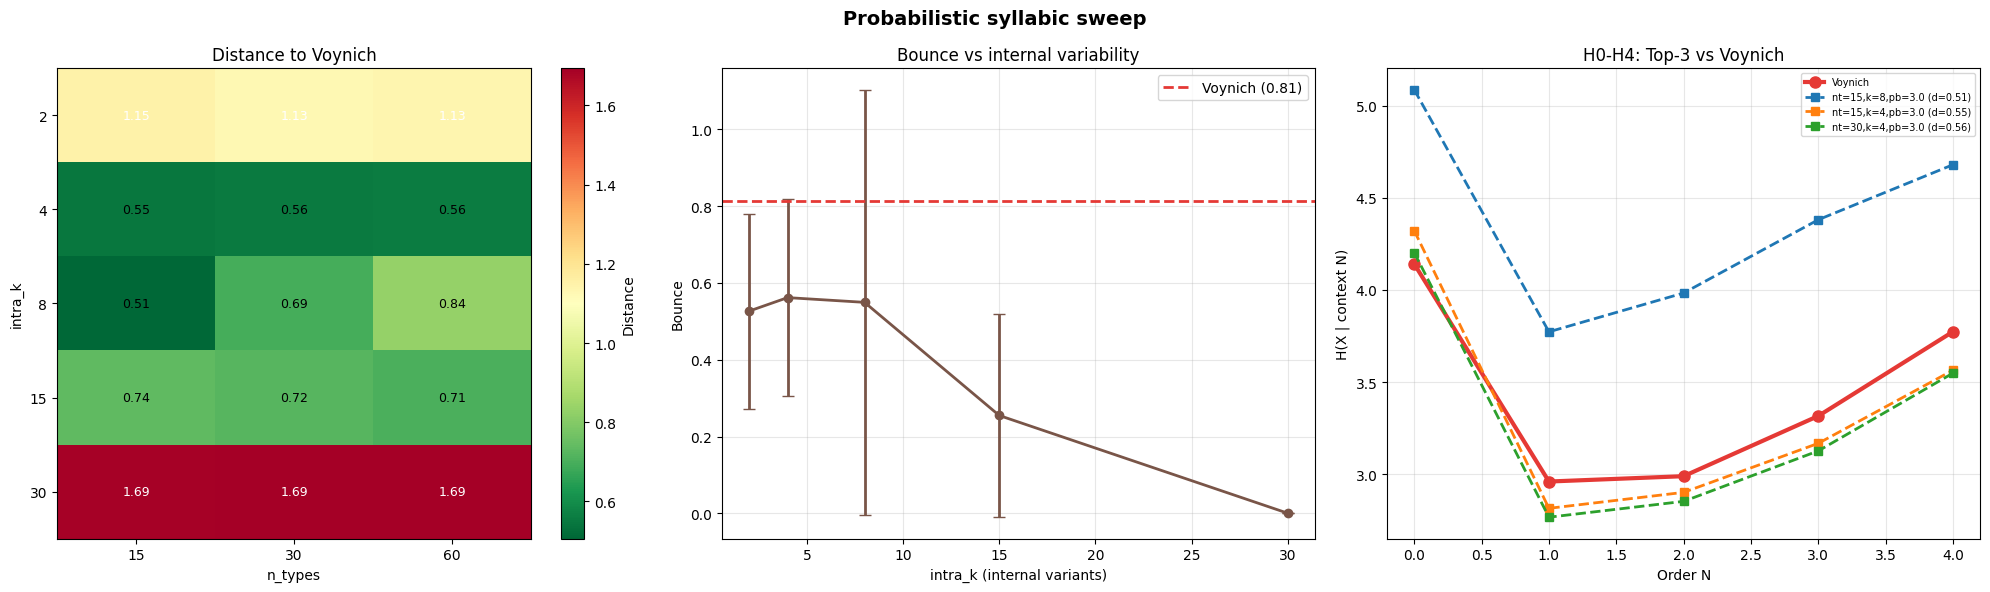

Saved: syllabic_sweep.png


In [32]:
# -- Cell 38: Visualisation sweep Syllabic Probabilistic ---------------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Panel 1: Heatmap n_types x intra_k (best tau+pos_bias per cell)
from collections import defaultdict as dd
best_by_cell = dd(lambda: {'distance': 999})
for r in syl_sweep_results:
    key = (r['n_types'], r['intra_k'])
    if r['distance'] < best_by_cell[key]['distance']:
        best_by_cell[key] = r

nt_vals = sorted(set(r['n_types'] for r in syl_sweep_results))
ik_vals = sorted(set(r['intra_k'] for r in syl_sweep_results))

heat = np.zeros((len(ik_vals), len(nt_vals)))
for i, ik in enumerate(ik_vals):
    for j, nt in enumerate(nt_vals):
        heat[i, j] = best_by_cell[(nt, ik)]['distance']

im = axes[0].imshow(heat, cmap='RdYlGn_r', aspect='auto',
                    vmin=heat.min(), vmax=min(heat.max(), 3.0))
axes[0].set_xticks(range(len(nt_vals)))
axes[0].set_xticklabels(nt_vals)
axes[0].set_yticks(range(len(ik_vals)))
axes[0].set_yticklabels(ik_vals)
axes[0].set_xlabel('n_types')
axes[0].set_ylabel('intra_k')
axes[0].set_title('Distance to Voynich')
for i in range(len(ik_vals)):
    for j in range(len(nt_vals)):
        axes[0].text(j, i, f'{heat[i,j]:.2f}', ha='center', va='center', fontsize=9,
                     color='white' if heat[i,j] > heat.mean() else 'black')
plt.colorbar(im, ax=axes[0], label='Distance')

# Panel 2: Bounce vs intra_k (media por intra_k)
ik_rebote = {}
for ik in ik_vals:
    vals = [r['rebote'] for r in syl_sweep_results if r['intra_k'] == ik]
    ik_rebote[ik] = (np.mean(vals), np.std(vals))
axes[1].errorbar(ik_vals, [ik_rebote[ik][0] for ik in ik_vals],
                 yerr=[ik_rebote[ik][1] for ik in ik_vals],
                 fmt='o-', color=COLOR_MAP['Silabico'], lw=2, capsize=4)
axes[1].axhline(VOYNICH_TARGET['rebote'], color=COLOR_MAP['Voynich'], ls='--', lw=2,
                label=f'Voynich ({VOYNICH_TARGET["rebote"]:.2f})')
axes[1].set_xlabel('intra_k (internal variants)')
axes[1].set_ylabel('Bounce')
axes[1].set_title('Bounce vs internal variability')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Panel 3: Curves H0-H4 top-3 vs Voynich
axes[2].plot([0,1,2,3,4], VOYNICH_TARGET['H_curve'][:5], 'o-',
             color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich')
for i, r in enumerate(syl_sweep_results[:3]):
    axes[2].plot([0,1,2,3,4], r['H_curve'], 's--', lw=2, markersize=6,
                 label=f'nt={r["n_types"]},k={r["intra_k"]},pb={r["pos_bias"]} '
                       f'(d={r["distance"]:.2f})')
axes[2].set_xlabel('Order N')
axes[2].set_ylabel('H(X | context N)')
axes[2].set_title('H0-H4: Top-3 vs Voynich')
axes[2].legend(fontsize=7)
axes[2].grid(True, alpha=0.3)

fig.suptitle('Probabilistic syllabic sweep', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig('images/silabico_sweep.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: syllabic_sweep.png')

Best Syllabic Prob: n_types=15, intra_k=8, pos_bias=3.0, tau=0.3, distance=0.506

H0-H6:
  H0 = 5.0858
  H1 = 3.7727
  H2 = 3.9832
  H3 = 4.3809
  H4 = 4.6793
  H5 = 4.6055
  H6 = 4.5149
MI_pos = 0.4581, MI_big = 1.6685

--- Comparison Voynich vs Syllabic Prob ---
Metric          Voynich   Syllabic      Delta
--------------------------------------------
Bounce           0.8131     0.9065    +0.0935
Decay            0.0886     0.0799    -0.0087
MI_pos           0.6578     0.4581    -0.1998
MI_big           1.6811     1.6685    -0.0126
Gap              0.5406     0.1284    -0.4122

--- vs Hybrid (previous best) ---
Metric           Hybrid   Syllabic
----------------------------------
Distance          0.783      0.506
Bounce            0.957      0.907
MI_pos            0.400      0.458
MI_big            1.178      1.668


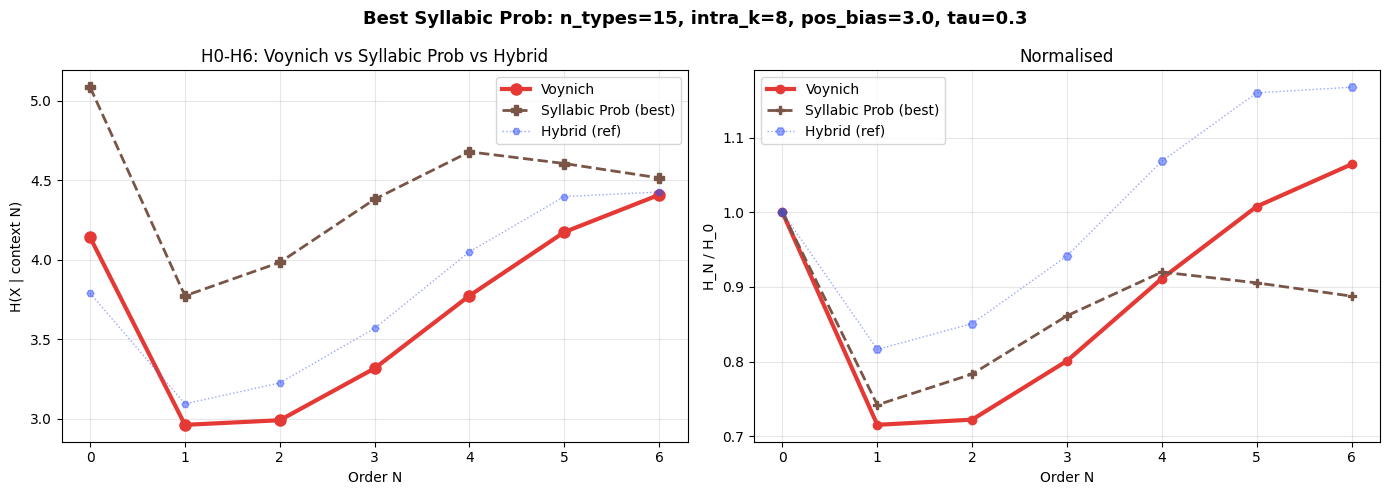

Saved: syllabic_mejor.png


In [33]:
# -- Cell 39: Best Syllabic Prob — full analysis H0-H6 ------------------------
best_syl = syl_sweep_results[0]
print(f'Best Syllabic Prob: n_types={best_syl["n_types"]}, intra_k={best_syl["intra_k"]}, '
      f'pos_bias={best_syl["pos_bias"]}, tau={best_syl["tau"]}, '
      f'distance={best_syl["distance"]:.3f}')

# Regenerate
syl_best_words, syl_best_types = generar_silabico_prob(
    VOCAB_VOYNICH, wlen_dist, n_types=best_syl['n_types'],
    syl_len_probs={1: 0.15, 2: 0.55, 3: 0.30},
    intra_k=best_syl['intra_k'],
    pos_bias=best_syl['pos_bias'], tau=best_syl['tau'],
    n_words=N_VOYNICH, seed=42
)
syl_best_flat = [g for p in syl_best_words for g in p]

# H0-H6
print('\nH0-H6:')
H_syl_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(syl_best_flat, n)
    H_syl_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral + MI
M_syl, toks_syl, _ = construir_matriz_transicion(syl_best_words)
spec_syl = analisis_espectral(M_syl, 'Syllabic Prob (best)')
mi_p_syl = mutual_information(syl_best_words)
mi_b_syl = mutual_information_bigram(syl_best_words)
print(f'MI_pos = {mi_p_syl:.4f}, MI_big = {mi_b_syl:.4f}')

# Direct comparison
print('\n--- Comparison Voynich vs Syllabic Prob ---')
print(f'{"Metric":<12} {"Voynich":>10} {"Syllabic":>10} {"Delta":>10}')
print('-' * 44)
s_mc = metricas_curva('Syllabic', H_syl_ext[:5], [0,1,2,3,4])
s_decay = (H_syl_ext[0] - H_syl_ext[4]) / H_syl_ext[0]
comparisons = [
    ('Bounce', VOYNICH_TARGET['rebote'], s_mc['rebote']),
    ('Decay', VOYNICH_TARGET['decay'], s_decay),
    ('MI_pos', VOYNICH_TARGET['MI_pos'], mi_p_syl),
    ('MI_big', VOYNICH_TARGET['MI_big'], mi_b_syl),
    ('Gap', VOYNICH_TARGET['gap'], spec_syl['gap']),
]
for name, vv, sv in comparisons:
    print(f'{name:<12} {vv:>10.4f} {sv:>10.4f} {sv-vv:>+10.4f}')

# Comparison with Hybrid
print('\n--- vs Hybrid (previous best) ---')
print(f'{"Metric":<12} {"Hybrid":>10} {"Syllabic":>10}')
print('-' * 34)
hyb_metrics = [
    ('Distance', 0.783, best_syl['distance']),
    ('Bounce', 0.957, s_mc['rebote']),
    ('MI_pos', 0.400, mi_p_syl),
    ('MI_big', 1.178, mi_b_syl),
]
for name, hv, sv in hyb_metrics:
    print(f'{name:<12} {hv:>10.3f} {sv:>10.3f}')

# Save figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(ordenes_ext, VOYNICH_TARGET['H_curve'], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich')
ax1.plot(ordenes_ext, H_syl_ext, 'P--',
         color=COLOR_MAP['Silabico'], lw=2, markersize=7, label='Syllabic Prob (best)')
ax1.plot(ordenes_ext, H_hybrid_ext, 'H:',
         color=COLOR_MAP['Hybrid'], lw=1, markersize=5, alpha=0.5, label='Hybrid (ref)')
ax1.set_xlabel('Order N')
ax1.set_ylabel('H(X | context N)')
ax1.set_title('H0-H6: Voynich vs Syllabic Prob vs Hybrid')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Normalised
norm_v = [v / VOYNICH_TARGET['H_curve'][0] for v in VOYNICH_TARGET['H_curve']]
norm_syl = [v / H_syl_ext[0] for v in H_syl_ext]
norm_hyb = [v / H_hybrid_ext[0] for v in H_hybrid_ext]
ax2.plot(ordenes_ext, norm_v, 'o-', color=COLOR_MAP['Voynich'], lw=3, label='Voynich')
ax2.plot(ordenes_ext, norm_syl, 'P--', color=COLOR_MAP['Silabico'], lw=2, label='Syllabic Prob (best)')
ax2.plot(ordenes_ext, norm_hyb, 'H:', color=COLOR_MAP['Hybrid'], lw=1, alpha=0.5, label='Hybrid (ref)')
ax2.set_xlabel('Order N')
ax2.set_ylabel('H_N / H_0')
ax2.set_title('Normalised')
ax2.legend()
ax2.grid(True, alpha=0.3)

fig.suptitle(f'Best Syllabic Prob: n_types={best_syl["n_types"]}, intra_k={best_syl["intra_k"]}, '
             f'pos_bias={best_syl["pos_bias"]}, tau={best_syl["tau"]}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/silabico_mejor.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: syllabic_mejor.png')

## Model 7: Syllabic with glyph partition (SilPart)

The probabilistic syllabic model (Model 6) reproduces decay, bounce and MI_big almost perfectly, but its MI_pos (0.458) falls below the Voynich (0.658). The problem: when building syllable types, preferred glyphs are chosen randomly from the full vocabulary, so onset and coda glyphs overlap.

### Solution: glyph partition

Divide the vocabulary into 3 groups (onset/middle/coda). Each syllable type selects its preferred glyphs **preferentially** from its group. A parameter `glyph_overlap` controls the overlap:

- `glyph_overlap = 0.0`: strict partition (onset glyphs NEVER appear in coda) → maximum MI_pos
- `glyph_overlap = 1.0`: no partition (Model 6 behaviour) → low MI_pos
- `glyph_overlap = 0.2`: partial overlap (region of interest)

### Hypothesis

The Voynich has high MI_pos because its "syllable" onsets and codas use **partially disjoint glyph sets** — phonotactic constraints analogous to those in real syllabic scripts.

In [34]:
# -- Cell: SilPart generator (syllabic with glyph partition) ---------------------

def generar_silabico_part(vocab, wlen_dist, n_types, syl_len_probs, intra_k,
                           pos_bias, tau, glyph_overlap, n_words, seed=42):
    """Probabilistic syllabic model with positional glyph partition."""
    rng = np.random.RandomState(seed)
    V = len(vocab)
    vocab_arr = np.array(vocab)

    # Fase 0: Particionar vocabulary en 3 grupos
    perm = rng.permutation(V)
    group_size = V // 3
    glyph_groups = {
        0: set(perm[:group_size].tolist()),           # onset glyphs
        1: set(perm[group_size:2*group_size].tolist()),# middle glyphs
        2: set(perm[2*group_size:].tolist()),          # coda glyphs
    }

    # Phase 1: Build syllable types
    syl_lens = sorted(syl_len_probs.keys())
    syl_len_p = np.array([syl_len_probs[l] for l in syl_lens])
    syl_len_p /= syl_len_p.sum()

    # Assign types to groups
    group_assign = np.zeros(n_types, dtype=int)
    g1 = n_types // 3
    g2 = 2 * n_types // 3
    group_assign[:g1] = 0
    group_assign[g1:g2] = 1
    group_assign[g2:] = 2

    types = []
    for t_idx in range(n_types):
        slen = rng.choice(syl_lens, p=syl_len_p)
        g = group_assign[t_idx]
        type_dists = []
        for _ in range(slen):
            # Selection weights: 1.0 for in-group, glyph_overlap for out-group
            sel_weights = np.full(V, max(glyph_overlap, 1e-10))
            for idx in glyph_groups[g]:
                sel_weights[idx] = 1.0
            sel_weights /= sel_weights.sum()

            # Seleccionar intra_k glyphs preferidos con estos weights
            k = min(intra_k, V)
            selected_idx = rng.choice(V, size=k, replace=False, p=sel_weights)

            # Asignar weights Zipf
            weights = np.array([1.0 / (i + 1)**0.8 for i in range(k)])
            dist = np.zeros(V)
            dist[selected_idx] = weights
            dist /= dist.sum()
            type_dists.append(dist)
        types.append((slen, type_dists))

    # Phase 2: Positional probabilities for types
    base_freq = np.array([1.0 / (i + 1)**0.8 for i in range(n_types)])
    base_freq /= base_freq.sum()

    type_probs = {}
    for wp in [0, 1, 2]:
        logits = np.log(base_freq + 1e-12) / max(tau, 0.01)
        logits[group_assign == wp] += pos_bias
        probs = np.exp(logits - logits.max())
        probs /= probs.sum()
        type_probs[wp] = probs

    # Phase 3: Syllable distribution per word
    mean_syl_len = sum(l * p for l, p in syl_len_probs.items())
    mean_wlen = sum(l * p for l, p in wlen_dist.items())
    mean_n_syl = mean_wlen / mean_syl_len

    possible_ns = np.arange(1, 6)
    ns_probs = poisson.pmf(possible_ns, mu=max(mean_n_syl, 1.0))
    ns_probs /= ns_probs.sum()

    # Phase 4: Generate words
    palabras = []
    for _ in range(n_words):
        n_s = rng.choice(possible_ns, p=ns_probs)
        word = []
        for si in range(n_s):
            if n_s == 1:
                wp = 0
            elif si == 0:
                wp = 0
            elif si == n_s - 1:
                wp = 2
            else:
                wp = 1
            type_idx = rng.choice(n_types, p=type_probs[wp])
            slen, type_dists = types[type_idx]
            for pos in range(slen):
                glyph_idx = rng.choice(V, p=type_dists[pos])
                word.append(vocab_arr[glyph_idx])
        palabras.append(word)

    return palabras, types

In [35]:
# -- Cell: SilPart default example --------------------------------------------------

print('Generando SilPart (n_types=15, intra_k=8, pos_bias=3.0, tau=0.3, glyph_overlap=0.2)...')
sp_ejemplo, sp_tipos = generar_silabico_part(
    VOCAB_VOYNICH, wlen_dist, n_types=15,
    syl_len_probs={1: 0.15, 2: 0.55, 3: 0.30},
    intra_k=8, pos_bias=3.0, tau=0.3, glyph_overlap=0.2,
    n_words=N_VOYNICH, seed=42
)

sp_flat = [g for p in sp_ejemplo for g in p]
print(f'\nWords: {len(sp_ejemplo):,}, Tokens: {len(sp_flat):,}')
print(f'Vocab efectivo: {len(set(sp_flat))}')
print(f'Mean length: {np.mean([len(p) for p in sp_ejemplo]):.2f}')

print('\nH0-H4:')
for n in range(5):
    h = entropia_condicional_n(sp_flat, n)
    print(f'  H{n} = {h:.4f}')

mi_p_ej = mutual_information(sp_ejemplo)
mi_b_ej = mutual_information_bigram(sp_ejemplo)
print(f'MI_pos = {mi_p_ej:.4f} (Voynich: {VOYNICH_TARGET["MI_pos"]:.4f})')
print(f'MI_big = {mi_b_ej:.4f} (Voynich: {VOYNICH_TARGET["MI_big"]:.4f})')

Generando SilPart (n_types=15, intra_k=8, pos_bias=3.0, tau=0.3, glyph_overlap=0.2)...

Words: 37,087, Tokens: 227,185
Vocab efectivo: 145
Mean length: 6.13

H0-H4:
  H0 = 5.3081
  H1 = 3.6381
  H2 = 3.7157
  H3 = 4.2032
  H4 = 4.6176
MI_pos = 0.4997 (Voynich: 0.6578)
MI_big = 1.9385 (Voynich: 1.6811)


In [36]:
# -- Cell 43: Sweep SilPart (parallel) ─────────────────────────────
n_types_sp   = [15, 30]
intra_ks_sp  = [4, 8]
overlaps     = [0.0, 0.1, 0.2, 0.4, 0.6, 1.0]
pos_biases_sp = [1.5, 3.0]
TAU_SP = 0.3
SYL_LEN_PROBS_SP = {1: 0.15, 2: 0.55, 3: 0.30}

configs = [(nt, ik, ov, pb) for nt in n_types_sp for ik in intra_ks_sp
           for ov in overlaps for pb in pos_biases_sp]
print(f'Sweep SilPart: {len(configs)} configurations ({N_CPUS} workers)')

def _silpart_worker(args):
    nt, ik, ov, pb = args
    palabras_sp, _ = generar_silabico_part(
        VOCAB_VOYNICH, wlen_dist, n_types=nt,
        syl_len_probs=SYL_LEN_PROBS_SP,
        intra_k=ik, pos_bias=pb, tau=TAU_SP,
        glyph_overlap=ov,
        n_words=N_VOYNICH, seed=42)
    m = compute_metrics_from_words(palabras_sp, 'sp')
    m.update({'n_types': nt, 'intra_k': ik, 'glyph_overlap': ov,
              'pos_bias': pb, 'tau': TAU_SP})
    m['distance'] = voynich_distance(m, VOYNICH_TARGET)
    return m

with Pool(N_CPUS) as pool:
    sp_sweep_results = pool.map(_silpart_worker, configs)

sp_sweep_results.sort(key=lambda x: x['distance'])

print(f'\n{"="*95}')
print(f'TOP-8 configurations (of {len(configs)}):')
print(f'{"="*95}')
print(f'{"#":>3} {"n_typ":>6} {"k":>3} {"overlap":>8} {"p_bias":>7} {"dist":>8} '
      f'{"bounce":>8} {"decay":>8} {"MI_pos":>8} {"MI_big":>8}')
print(f'{"-"*95}')
for i, r in enumerate(sp_sweep_results[:8], 1):
    print(f'{i:>3} {r["n_types"]:>6} {r["intra_k"]:>3} {r["glyph_overlap"]:>8.2f} '
          f'{r["pos_bias"]:>7.1f} {r["distance"]:>8.3f} {r["rebote"]:>8.3f} '
          f'{r["decay"]:>8.3f} {r["MI_pos"]:>8.3f} {r["MI_big"]:>8.3f}')


Sweep SilPart: 48 configurations (15 workers)

TOP-8 configurations (of 48):
  #  n_typ   k  overlap  p_bias     dist   bounce    decay   MI_pos   MI_big
-----------------------------------------------------------------------------------------------
  1     15   8     0.10     3.0    0.445    0.909    0.127    0.477    1.848
  2     15   8     0.10     1.5    0.524    1.012    0.095    0.445    1.702
  3     30   8     0.10     3.0    0.536    1.026    0.082    0.441    1.689
  4     15   8     0.20     3.0    0.570    0.979    0.130    0.500    1.939
  5     15   8     0.00     3.0    0.574    0.846    0.050    0.400    1.301
  6     30   8     0.20     3.0    0.596    1.040    0.106    0.467    1.837
  7     15   4     0.40     3.0    0.607    0.537    0.238    0.477    1.575
  8     30   4     1.00     3.0    0.626    0.560    0.245    0.490    1.761


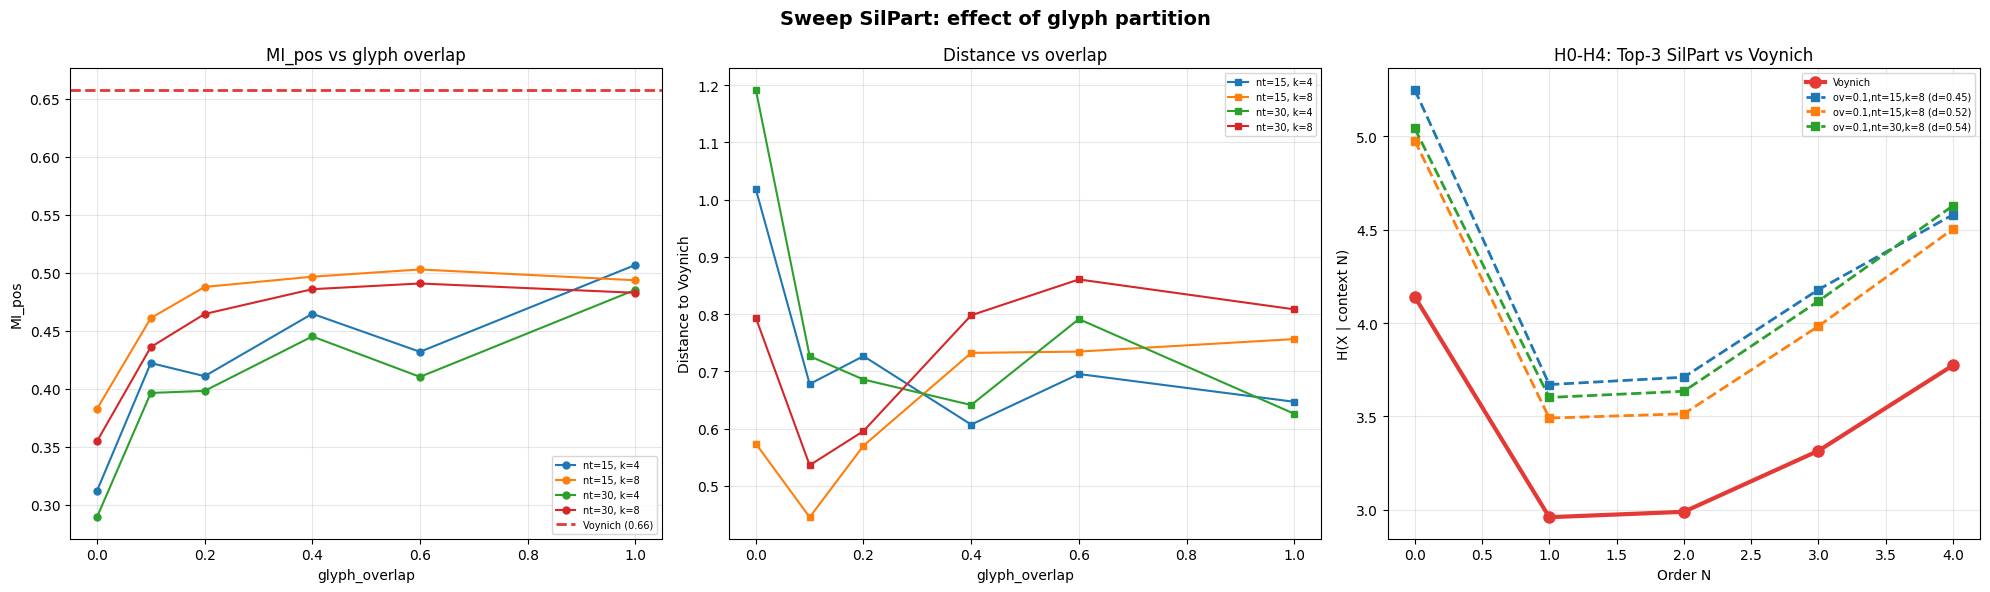

Saved: silpart_sweep.png


In [37]:
# -- Cell: Visualisation sweep SilPart -----------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Panel 1: MI_pos vs glyph_overlap (el grafico clave)
ov_vals = sorted(set(r['glyph_overlap'] for r in sp_sweep_results))
for nt in sorted(set(r['n_types'] for r in sp_sweep_results)):
    for ik in sorted(set(r['intra_k'] for r in sp_sweep_results)):
        mi_by_ov = []
        for ov in ov_vals:
            vals = [r['MI_pos'] for r in sp_sweep_results
                    if r['n_types'] == nt and r['intra_k'] == ik and r['glyph_overlap'] == ov]
            mi_by_ov.append(np.mean(vals) if vals else 0)
        axes[0].plot(ov_vals, mi_by_ov, 'o-', lw=1.5, markersize=5,
                     label=f'nt={nt}, k={ik}')
axes[0].axhline(VOYNICH_TARGET['MI_pos'], color=COLOR_MAP['Voynich'], ls='--', lw=2,
                label=f'Voynich ({VOYNICH_TARGET["MI_pos"]:.2f})')
axes[0].set_xlabel('glyph_overlap')
axes[0].set_ylabel('MI_pos')
axes[0].set_title('MI_pos vs glyph overlap')
axes[0].legend(fontsize=7)
axes[0].grid(True, alpha=0.3)

# Panel 2: Distance vs glyph_overlap
for nt in sorted(set(r['n_types'] for r in sp_sweep_results)):
    for ik in sorted(set(r['intra_k'] for r in sp_sweep_results)):
        d_by_ov = []
        for ov in ov_vals:
            vals = [r['distance'] for r in sp_sweep_results
                    if r['n_types'] == nt and r['intra_k'] == ik and r['glyph_overlap'] == ov]
            d_by_ov.append(np.min(vals) if vals else 999)
        axes[1].plot(ov_vals, d_by_ov, 's-', lw=1.5, markersize=5,
                     label=f'nt={nt}, k={ik}')
axes[1].set_xlabel('glyph_overlap')
axes[1].set_ylabel('Distance to Voynich')
axes[1].set_title('Distance vs overlap')
axes[1].legend(fontsize=7)
axes[1].grid(True, alpha=0.3)

# Panel 3: H0-H4 curves top-3 vs Voynich
axes[2].plot([0,1,2,3,4], VOYNICH_TARGET['H_curve'][:5], 'o-',
             color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich')
for i, r in enumerate(sp_sweep_results[:3]):
    axes[2].plot([0,1,2,3,4], r['H_curve'], 's--', lw=2, markersize=6,
                 label=f'ov={r["glyph_overlap"]},nt={r["n_types"]},k={r["intra_k"]} '
                       f'(d={r["distance"]:.2f})')
axes[2].set_xlabel('Order N')
axes[2].set_ylabel('H(X | context N)')
axes[2].set_title('H0-H4: Top-3 SilPart vs Voynich')
axes[2].legend(fontsize=7)
axes[2].grid(True, alpha=0.3)

fig.suptitle('Sweep SilPart: effect of glyph partition', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig('images/silpart_sweep.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: silpart_sweep.png')

Best SilPart: n_types=15, intra_k=8, glyph_overlap=0.1, pos_bias=3.0, tau=0.3, distance=0.445

H0-H6:
  H0 = 5.2484
  H1 = 3.6707
  H2 = 3.7100
  H3 = 4.1789
  H4 = 4.5799
  H5 = 4.6558
  H6 = 4.5658
MI_pos = 0.4768, MI_big = 1.8476

--- Comparison: Voynich vs SilPart vs Syllabic Prob ---
Metric          Voynich    SilPart    SylProb   Delta SP
------------------------------------------------------
Bounce           0.8131     0.9092     0.9065    +0.0961
Decay            0.0886     0.1274     0.0799    +0.0388
MI_pos           0.6578     0.4768     0.4581    -0.1810
MI_big           1.6811     1.8476     1.6685    +0.1665
Gap              0.5406     0.2635     0.1284    -0.2771


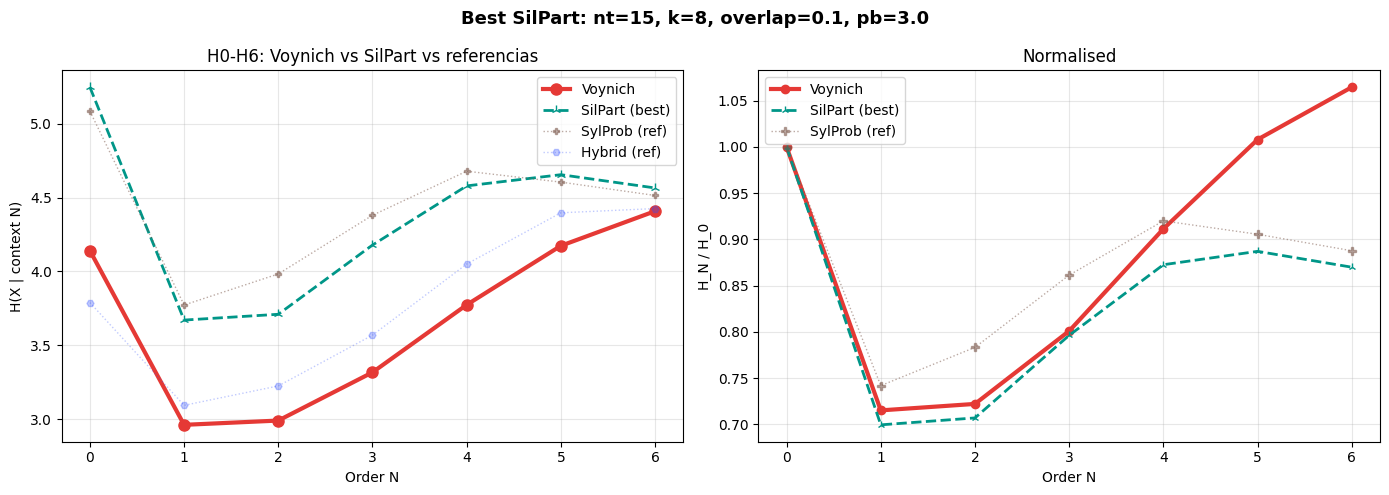

Saved: silpart_mejor.png


In [38]:
# -- Cell: Best SilPart -- full analysis H0-H6 ---------------------------------
best_sp = sp_sweep_results[0]
print(f'Best SilPart: n_types={best_sp["n_types"]}, intra_k={best_sp["intra_k"]}, '
      f'glyph_overlap={best_sp["glyph_overlap"]}, pos_bias={best_sp["pos_bias"]}, '
      f'tau={best_sp["tau"]}, distance={best_sp["distance"]:.3f}')

# Regenerate
sp_best_words, sp_best_types = generar_silabico_part(
    VOCAB_VOYNICH, wlen_dist, n_types=best_sp['n_types'],
    syl_len_probs={1: 0.15, 2: 0.55, 3: 0.30},
    intra_k=best_sp['intra_k'],
    pos_bias=best_sp['pos_bias'], tau=best_sp['tau'],
    glyph_overlap=best_sp['glyph_overlap'],
    n_words=N_VOYNICH, seed=42
)
sp_best_flat = [g for p in sp_best_words for g in p]

# H0-H6
print('\nH0-H6:')
H_sp_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(sp_best_flat, n)
    H_sp_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral + MI
M_spb, toks_spb, _ = construir_matriz_transicion(sp_best_words)
spec_sp = analisis_espectral(M_spb, 'SilPart (best)')
mi_p_sp = mutual_information(sp_best_words)
mi_b_sp = mutual_information_bigram(sp_best_words)
print(f'MI_pos = {mi_p_sp:.4f}, MI_big = {mi_b_sp:.4f}')

# Direct comparison
print('\n--- Comparison: Voynich vs SilPart vs Syllabic Prob ---')
print(f'{"Metric":<12} {"Voynich":>10} {"SilPart":>10} {"SylProb":>10} {"Delta SP":>10}')
print('-' * 54)
sp_mc = metricas_curva('SilPart', H_sp_ext[:5], [0,1,2,3,4])
sp_decay = (H_sp_ext[0] - H_sp_ext[4]) / H_sp_ext[0]
syl_prev_metrics = all_metrics.get('Silabico', {}) if 'all_metrics' in dir() else {}
comparisons = [
    ('Bounce', VOYNICH_TARGET['rebote'], sp_mc['rebote'], best_syl.get('rebote', 0)),
    ('Decay', VOYNICH_TARGET['decay'], sp_decay, best_syl.get('decay', 0)),
    ('MI_pos', VOYNICH_TARGET['MI_pos'], mi_p_sp, best_syl.get('MI_pos', 0)),
    ('MI_big', VOYNICH_TARGET['MI_big'], mi_b_sp, best_syl.get('MI_big', 0)),
    ('Gap', VOYNICH_TARGET['gap'], spec_sp['gap'], best_syl.get('gap', 0)),
]
for name, vv, spv, sylv in comparisons:
    print(f'{name:<12} {vv:>10.4f} {spv:>10.4f} {sylv:>10.4f} {spv-vv:>+10.4f}')

# Save figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(ordenes_ext, VOYNICH_TARGET['H_curve'], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich')
ax1.plot(ordenes_ext, H_sp_ext, '2--',
         color=COLOR_MAP['SilPart'], lw=2, markersize=7, label='SilPart (best)')
ax1.plot(ordenes_ext, H_syl_ext, 'P:',
         color=COLOR_MAP['Silabico'], lw=1, markersize=5, alpha=0.5, label='SylProb (ref)')
ax1.plot(ordenes_ext, H_hybrid_ext, 'H:',
         color=COLOR_MAP['Hybrid'], lw=1, markersize=5, alpha=0.3, label='Hybrid (ref)')
ax1.set_xlabel('Order N')
ax1.set_ylabel('H(X | context N)')
ax1.set_title('H0-H6: Voynich vs SilPart vs referencias')
ax1.legend()
ax1.grid(True, alpha=0.3)

norm_v = [v / VOYNICH_TARGET['H_curve'][0] for v in VOYNICH_TARGET['H_curve']]
norm_sp = [v / H_sp_ext[0] for v in H_sp_ext]
norm_syl = [v / H_syl_ext[0] for v in H_syl_ext]
ax2.plot(ordenes_ext, norm_v, 'o-', color=COLOR_MAP['Voynich'], lw=3, label='Voynich')
ax2.plot(ordenes_ext, norm_sp, '2--', color=COLOR_MAP['SilPart'], lw=2, label='SilPart (best)')
ax2.plot(ordenes_ext, norm_syl, 'P:', color=COLOR_MAP['Silabico'], lw=1, alpha=0.5, label='SylProb (ref)')
ax2.set_xlabel('Order N')
ax2.set_ylabel('H_N / H_0')
ax2.set_title('Normalised')
ax2.legend()
ax2.grid(True, alpha=0.3)

fig.suptitle(f'Best SilPart: nt={best_sp["n_types"]}, k={best_sp["intra_k"]}, '
             f'overlap={best_sp["glyph_overlap"]}, pb={best_sp["pos_bias"]}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/silpart_mejor.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: silpart_mejor.png')

## Model 8: Cardan grille (Rugg 2004)

Gordon Rugg [2004] proposed that the Voynich could have been generated with a **Cardan grille** over a prefix-root-suffix table.
Each table row contains fragments of 0-3 glyphs in three columns.
The grille exposes or hides the prefix and suffix columns; the root is always visible.

**Parameters**: `n_rows` (table rows), `p_prefix`/`p_suffix` (probability of exposing prefix/suffix).

**Sweep**: n_rows=[10, 20, 40, 80] × p_prefix=[0.3, 0.5, 0.8] × p_suffix=[0.3, 0.5, 0.8] = **36 configs**

In [39]:
# ── Model 8: Cardan generator + Sweep ─────────────────────────────

def generar_cardan(vocab, wlen_dist, n_rows=20, prefix_max=2, root_max=3,
                   suffix_max=2, p_prefix=0.5, p_suffix=0.5, n_words=37087, seed=42):
    """
    Cardan table (Rugg 2004): table of n_rows rows x 3 columns
    (prefix, root, suffix). Grille exposes/hides prefix and suffix.
    """
    rng = np.random.RandomState(seed)
    V = len(vocab)

    # Build table: each row = (prefix, root, suffix)
    tabla = []
    for _ in range(n_rows):
        plen = rng.randint(0, prefix_max + 1)  # 0 to prefix_max glyphs
        rlen = rng.randint(1, root_max + 1)     # 1 to root_max glyphs (always >=1)
        slen = rng.randint(0, suffix_max + 1)
        prefix = [vocab[rng.randint(V)] for _ in range(plen)]
        root   = [vocab[rng.randint(V)] for _ in range(rlen)]
        suffix = [vocab[rng.randint(V)] for _ in range(slen)]
        tabla.append((prefix, root, suffix))

    # Generate words with Voynich length distribution
    wlens = sorted(wlen_dist.keys())
    wlen_p = np.array([wlen_dist[l] for l in wlens])
    wlen_p /= wlen_p.sum()

    palabras = []
    for _ in range(n_words):
        target_len = rng.choice(wlens, p=wlen_p)
        # Try up to 20 times to find a combination of the desired length
        best_word = None
        best_diff = 999
        for _ in range(20):
            row = tabla[rng.randint(n_rows)]
            word = []
            if rng.random() < p_prefix:
                word.extend(row[0])
            word.extend(row[1])
            if rng.random() < p_suffix:
                word.extend(row[2])
            if not word:
                word = list(row[1])  # fallback: root only
            diff = abs(len(word) - target_len)
            if diff < best_diff:
                best_diff = diff
                best_word = word
            if diff == 0:
                break
        palabras.append(best_word)

    return palabras


# ── Sweep Cardan (parallel) ──
print('Sweep Cardan (36 configs)...')

configs = [(n_rows, p_pref, p_suff)
           for n_rows in [10, 20, 40, 80]
           for p_pref in [0.3, 0.5, 0.8]
           for p_suff in [0.3, 0.5, 0.8]]

def _cardan_worker(args):
    n_rows, p_pref, p_suff = args
    words = generar_cardan(VOCAB_VOYNICH, wlen_dist, n_rows=n_rows,
                           p_prefix=p_pref, p_suffix=p_suff,
                           n_words=N_VOYNICH, seed=42)
    m = compute_metrics_from_words(words, 'Cardan')
    m.update({'n_rows': n_rows, 'p_prefix': p_pref, 'p_suffix': p_suff})
    m['distance'] = voynich_distance(m, VOYNICH_TARGET)
    return m

with Pool(N_CPUS) as pool:
    cardan_sweep_results = pool.map(_cardan_worker, configs)

cardan_sweep_results.sort(key=lambda x: x['distance'])
print(f'Best Cardan: n_rows={cardan_sweep_results[0]["n_rows"]}, '
      f'p_pref={cardan_sweep_results[0]["p_prefix"]}, '
      f'p_suff={cardan_sweep_results[0]["p_suffix"]}, '
      f'd={cardan_sweep_results[0]["distance"]:.3f}')
print(f'  bounce={cardan_sweep_results[0]["rebote"]:.4f}, '
      f'decay={cardan_sweep_results[0]["decay"]:.4f}')


Sweep Cardan (36 configs)...
Best Cardan: n_rows=10, p_pref=0.3, p_suff=0.8, d=4.485
  bounce=0.1125, decay=0.7549


In [40]:
# ── Best Cardan — full analysis H0-H6 ─────────────────────────
best_cardan = cardan_sweep_results[0]
print(f'Best Cardan: n_rows={best_cardan["n_rows"]}, p_prefix={best_cardan["p_prefix"]}, '
      f'p_suffix={best_cardan["p_suffix"]}, distance={best_cardan["distance"]:.3f}')

# Regenerate
cardan_best_words = generar_cardan(
    VOCAB_VOYNICH, wlen_dist, n_rows=best_cardan['n_rows'],
    p_prefix=best_cardan['p_prefix'], p_suffix=best_cardan['p_suffix'],
    n_words=N_VOYNICH, seed=42
)
cardan_best_flat = [g for w in cardan_best_words for g in w]

# H0-H6
print('\nH0-H6:')
H_cardan_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(cardan_best_flat, n)
    H_cardan_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral + MI
M_crd, _, _ = construir_matriz_transicion(cardan_best_words)
spec_crd = analisis_espectral(M_crd, 'Cardan (best)')
mi_p_crd = mutual_information(cardan_best_words)
mi_b_crd = mutual_information_bigram(cardan_best_words)
print(f'Spectral gap = {spec_crd["gap"]:.4f}')
print(f'MI_pos = {mi_p_crd:.4f}, MI_big = {mi_b_crd:.4f}')

Best Cardan: n_rows=10, p_prefix=0.3, p_suffix=0.8, distance=4.485

H0-H6:
  H0 = 5.0235
  H1 = 1.2753
  H2 = 1.1186
  H3 = 1.1607
  H4 = 1.2311
  H5 = 1.3471
  H6 = 1.4931
Spectral gap = 0.2359
MI_pos = 1.0752, MI_big = 5.0870


## Model 9: Self-citation (Timm & Schinner 2020)

Timm and Schinner [2020] proposed that Voynich words are generated by **copy-and-mutate** from previous words.
Starting from a seed set, each new word is obtained by copying a previous one and applying stochastic mutations (substitution, insertion or deletion of glyphs).

**Parameters**: `seed_size` (seed words), `p_sub`/`p_ins`/`p_del` (per-glyph mutation probabilities).

**Sweep**: seed_size=[10, 30, 100] × p_sub=[0.05, 0.15, 0.3] × p_ins=[0.05, 0.1] × p_del=[0.05, 0.1] = **36 configs**

In [41]:
# ── Model 9: AutoCite generator + Sweep ───────────────────────────

def generar_autocita(vocab, wlen_dist, seed_size=30, p_sub=0.15,
                     p_ins=0.05, p_del=0.05, n_words=37087, seed=42):
    """
    Auto-citation (Timm & Schinner 2020): copy-and-mutate previous words.
    """
    rng = np.random.RandomState(seed)
    V = len(vocab)

    # Generate seed: random words with length distribution
    wlens = sorted(wlen_dist.keys())
    wlen_p = np.array([wlen_dist[l] for l in wlens])
    wlen_p /= wlen_p.sum()

    palabras = []
    for _ in range(seed_size):
        wl = rng.choice(wlens, p=wlen_p)
        word = [vocab[rng.randint(V)] for _ in range(wl)]
        palabras.append(word)

    # Generate rest by copy-and-mutation
    for _ in range(n_words - seed_size):
        # Copy a random previous word
        src_idx = rng.randint(len(palabras))
        word = list(palabras[src_idx])

        # Mutations
        # 1. Substitution
        for j in range(len(word)):
            if rng.random() < p_sub:
                word[j] = vocab[rng.randint(V)]

        # 2. Insertion (reverse order to preserve indices)
        inserts = []
        for j in range(len(word)):
            if rng.random() < p_ins:
                inserts.append((j + 1, vocab[rng.randint(V)]))
        for pos, glyph in reversed(inserts):
            word.insert(pos, glyph)

        # 3. Deletion
        if len(word) > 1:
            word = [g for g in word if rng.random() >= p_del or len(word) <= 1]
            if not word:
                word = [vocab[rng.randint(V)]]

        palabras.append(word)

    return palabras[:n_words]


# ── Sweep AutoCita (parallel) ──
print('Sweep AutoCita (36 configs)...')

configs = [(seed_sz, p_s, p_i, p_d)
           for seed_sz in [10, 30, 100]
           for p_s in [0.05, 0.15, 0.3]
           for p_i in [0.05, 0.1]
           for p_d in [0.05, 0.1]]

def _autocita_worker(args):
    seed_sz, p_s, p_i, p_d = args
    words = generar_autocita(VOCAB_VOYNICH, wlen_dist,
                             seed_size=seed_sz, p_sub=p_s,
                             p_ins=p_i, p_del=p_d,
                             n_words=N_VOYNICH, seed=42)
    m = compute_metrics_from_words(words, 'AutoCita')
    m.update({'seed_size': seed_sz, 'p_sub': p_s, 'p_ins': p_i, 'p_del': p_d})
    m['distance'] = voynich_distance(m, VOYNICH_TARGET)
    return m

with Pool(N_CPUS) as pool:
    autocita_sweep_results = pool.map(_autocita_worker, configs)

autocita_sweep_results.sort(key=lambda x: x['distance'])
print(f'Best AutoCita: seed={autocita_sweep_results[0]["seed_size"]}, '
      f'p_sub={autocita_sweep_results[0]["p_sub"]}, '
      f'p_ins={autocita_sweep_results[0]["p_ins"]}, '
      f'p_del={autocita_sweep_results[0]["p_del"]}, '
      f'd={autocita_sweep_results[0]["distance"]:.3f}')


Sweep AutoCita (36 configs)...
Best AutoCita: seed=10, p_sub=0.05, p_ins=0.05, p_del=0.05, d=1.356


In [42]:
# ── Best AutoCite — full analysis H0-H6 ───────────────────────
best_autocita = autocita_sweep_results[0]
print(f'Best AutoCita: seed_size={best_autocita["seed_size"]}, '
      f'p_sub={best_autocita["p_sub"]}, p_ins={best_autocita["p_ins"]}, '
      f'p_del={best_autocita["p_del"]}, distance={best_autocita["distance"]:.3f}')

# Regenerate
autocita_best_words = generar_autocita(
    VOCAB_VOYNICH, wlen_dist, seed_size=best_autocita['seed_size'],
    p_sub=best_autocita['p_sub'], p_ins=best_autocita['p_ins'],
    p_del=best_autocita['p_del'], n_words=N_VOYNICH, seed=42
)
autocita_best_flat = [g for w in autocita_best_words for g in w]

# H0-H6
print('\nH0-H6:')
H_autocita_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(autocita_best_flat, n)
    H_autocita_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral + MI
M_ac, _, _ = construir_matriz_transicion(autocita_best_words)
spec_ac = analisis_espectral(M_ac, 'AutoCita (best)')
mi_p_ac = mutual_information(autocita_best_words)
mi_b_ac = mutual_information_bigram(autocita_best_words)
print(f'Spectral gap = {spec_ac["gap"]:.4f}')
print(f'MI_pos = {mi_p_ac:.4f}, MI_big = {mi_b_ac:.4f}')

Best AutoCita: seed_size=10, p_sub=0.05, p_ins=0.05, p_del=0.05, distance=1.356

H0-H6:
  H0 = 6.8058
  H1 = 5.3205
  H2 = 4.5116
  H3 = 4.2429
  H4 = 4.3631
  H5 = 4.4819
  H6 = 4.5620
Spectral gap = 0.7324
MI_pos = 0.3116, MI_big = 1.8363


## Model 10: Polygraphia III (Hermes 2022)

Hermes [2022] proposed a system based on Trithemius' *Polygraphia*: a **polyalphabetic cipher** with `n_alphabets` substitution tables that rotate cyclically character by character.
Each table maps a plaintext character (Latin) to a sequence of 1-`sub_max_len` glyphs.
The rotation creates patterns that simulate an artificial language.

**Parameters**: `n_alphabets` (substitution tables), `sub_max_len` (maximum substitution length).

**Sweep**: n_alphabets=[3, 5, 8, 13, 21] × sub_max_len=[1, 2, 3] = **15 configs**

In [43]:
# ── Model 10: Polyg3 generator + Sweep ────────────────────────────

def generar_polyg3(vocab, wlen_dist, plaintext_flat, n_alphabets=5,
                   sub_max_len=2, n_words=37087, seed=42):
    """
    Polygraphia III (Hermes 2022): polyalphabetic cipher with n tables
    of rotating substitution. Each table maps char to 1..sub_max_len glyphs.
    """
    rng = np.random.RandomState(seed)
    V = len(vocab)
    pt_chars = sorted(set(plaintext_flat))

    # Build n_alphabets substitution tables
    tables = []
    for _ in range(n_alphabets):
        table = {}
        for ch in pt_chars:
            slen = rng.randint(1, sub_max_len + 1)  # 1 to sub_max_len
            table[ch] = [vocab[rng.randint(V)] for _ in range(slen)]
        tables.append(table)

    # Encrypt: rotate table character by character
    glyph_stream = []
    for i, ch in enumerate(plaintext_flat):
        table_idx = i % n_alphabets
        if ch in tables[table_idx]:
            glyph_stream.extend(tables[table_idx][ch])

    # Segment into words
    wlens = sorted(wlen_dist.keys())
    wlen_p = np.array([wlen_dist[l] for l in wlens])
    wlen_p /= wlen_p.sum()

    palabras = []
    pos = 0
    while len(palabras) < n_words and pos < len(glyph_stream):
        wl = rng.choice(wlens, p=wlen_p)
        if pos + wl > len(glyph_stream):
            break
        palabras.append(list(glyph_stream[pos:pos + wl]))
        pos += wl

    return palabras


# ── Sweep Polyg3 (parallel) ──
print('Sweep Polyg3 (15 configs)...')

configs = [(n_alph, sml) for n_alph in [3, 5, 8, 13, 21] for sml in [1, 2, 3]]

def _polyg3_worker(args):
    n_alph, sml = args
    words = generar_polyg3(VOCAB_VOYNICH, wlen_dist, plaintext_latin,
                           n_alphabets=n_alph, sub_max_len=sml,
                           n_words=N_VOYNICH, seed=42)
    m = compute_metrics_from_words(words, 'Polyg3')
    m.update({'n_alphabets': n_alph, 'sub_max_len': sml})
    m['distance'] = voynich_distance(m, VOYNICH_TARGET)
    return m

with Pool(N_CPUS) as pool:
    polyg3_sweep_results = pool.map(_polyg3_worker, configs)

polyg3_sweep_results.sort(key=lambda x: x['distance'])
print(f'Best Polyg3: n_alphabets={polyg3_sweep_results[0]["n_alphabets"]}, '
      f'sub_max_len={polyg3_sweep_results[0]["sub_max_len"]}, '
      f'd={polyg3_sweep_results[0]["distance"]:.3f}')


Sweep Polyg3 (15 configs)...
Best Polyg3: n_alphabets=13, sub_max_len=1, d=1.659


In [44]:
# ── Best Polyg3 — full analysis H0-H6 ─────────────────────────
best_polyg3 = polyg3_sweep_results[0]
print(f'Best Polyg3: n_alphabets={best_polyg3["n_alphabets"]}, '
      f'sub_max_len={best_polyg3["sub_max_len"]}, '
      f'distance={best_polyg3["distance"]:.3f}')

# Regenerate
polyg3_best_words = generar_polyg3(
    VOCAB_VOYNICH, wlen_dist, plaintext_latin,
    n_alphabets=best_polyg3['n_alphabets'],
    sub_max_len=best_polyg3['sub_max_len'],
    n_words=N_VOYNICH, seed=42
)
polyg3_best_flat = [g for w in polyg3_best_words for g in w]

# H0-H6
print('\nH0-H6:')
H_polyg3_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(polyg3_best_flat, n)
    H_polyg3_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral + MI
M_pg, _, _ = construir_matriz_transicion(polyg3_best_words)
spec_pg = analisis_espectral(M_pg, 'Polyg3 (best)')
mi_p_pg = mutual_information(polyg3_best_words)
mi_b_pg = mutual_information_bigram(polyg3_best_words)
print(f'Spectral gap = {spec_pg["gap"]:.4f}')
print(f'MI_pos = {mi_p_pg:.4f}, MI_big = {mi_b_pg:.4f}')

Best Polyg3: n_alphabets=13, sub_max_len=1, distance=1.659

H0-H6:
  H0 = 6.6271
  H1 = 4.4207
  H2 = 3.8744
  H3 = 3.9725
  H4 = 4.0556
  H5 = 4.1888
  H6 = 4.2909
Spectral gap = 0.4032
MI_pos = 0.0012, MI_big = 2.3685


## Model 11: Naibbe cipher (Greshko 2025)

Greshko [2025] proposed a **verbose homophonic cipher** operating on groups of 1-`group_max` plaintext characters.
Each group is replaced by a codeword of variable length (1-`codeword_max` glyphs), with `n_homophones` alternatives per group for added variability.

**Parameters**: `group_max` (maximum group length), `n_homophones` (alternatives per group), `codeword_max` (maximum codeword length).

**Sweep**: group_max=[1, 2, 3] × n_homophones=[2, 4, 8] × codeword_max=[2, 3, 4] = **27 configs**

In [45]:
# ── Model 11: Naibbe generator + Sweep ────────────────────────────

def generar_naibbe(vocab, wlen_dist, plaintext_flat, group_max=2,
                   n_homophones=4, codeword_max=3, n_words=37087, seed=42):
    """
    Naibbe cipher (Greshko 2025): verbose homophonic by groups.
    Each group of 1..group_max chars is substituted by a codeword
    of length 1..codeword_max, with n_homophones alternatives.
    """
    rng = np.random.RandomState(seed)
    V = len(vocab)

    # Build all possible groups from plaintext
    pt_chars = sorted(set(plaintext_flat))
    groups = set()
    for g_len in range(1, group_max + 1):
        for i in range(len(plaintext_flat) - g_len + 1):
            groups.add(tuple(plaintext_flat[i:i + g_len]))
    # Limit to 500 most frequent for manageability
    group_counter = Counter()
    for g_len in range(1, group_max + 1):
        for i in range(len(plaintext_flat) - g_len + 1):
            group_counter[tuple(plaintext_flat[i:i + g_len])] += 1
    top_groups = [g for g, _ in group_counter.most_common(500)]

    # Build codebook: each group → list of n_homophones codewords
    codebook = {}
    for grp in top_groups:
        homophones = []
        for _ in range(n_homophones):
            cw_len = rng.randint(1, codeword_max + 1)
            cw = tuple(vocab[rng.randint(V)] for _ in range(cw_len))
            homophones.append(cw)
        codebook[grp] = homophones

    # Encrypt: greedy matching (longest group first)
    glyph_stream = []
    pos = 0
    while pos < len(plaintext_flat):
        matched = False
        for g_len in range(min(group_max, len(plaintext_flat) - pos), 0, -1):
            grp = tuple(plaintext_flat[pos:pos + g_len])
            if grp in codebook:
                # Choose a random homophone
                homo_idx = rng.randint(n_homophones)
                glyph_stream.extend(codebook[grp][homo_idx])
                pos += g_len
                matched = True
                break
        if not matched:
            pos += 1  # skip unencoded character

    # Segment into words
    wlens = sorted(wlen_dist.keys())
    wlen_p = np.array([wlen_dist[l] for l in wlens])
    wlen_p /= wlen_p.sum()

    palabras = []
    wpos = 0
    while len(palabras) < n_words and wpos < len(glyph_stream):
        wl = rng.choice(wlens, p=wlen_p)
        if wpos + wl > len(glyph_stream):
            break
        palabras.append(list(glyph_stream[wpos:wpos + wl]))
        wpos += wl

    return palabras


# ── Sweep Naibbe (parallel) ──
print('Sweep Naibbe (27 configs)...')

configs = [(gm, nh, cwm) for gm in [1, 2, 3] for nh in [2, 4, 8] for cwm in [2, 3, 4]]

def _naibbe_worker(args):
    gm, nh, cwm = args
    words = generar_naibbe(VOCAB_VOYNICH, wlen_dist, plaintext_latin,
                           group_max=gm, n_homophones=nh,
                           codeword_max=cwm,
                           n_words=N_VOYNICH, seed=42)
    m = compute_metrics_from_words(words, 'Naibbe')
    m.update({'group_max': gm, 'n_homophones': nh, 'codeword_max': cwm})
    m['distance'] = voynich_distance(m, VOYNICH_TARGET)
    return m

with Pool(N_CPUS) as pool:
    naibbe_sweep_results = pool.map(_naibbe_worker, configs)

naibbe_sweep_results.sort(key=lambda x: x['distance'])
print(f'Best Naibbe: group_max={naibbe_sweep_results[0]["group_max"]}, '
      f'n_homophones={naibbe_sweep_results[0]["n_homophones"]}, '
      f'codeword_max={naibbe_sweep_results[0]["codeword_max"]}, '
      f'd={naibbe_sweep_results[0]["distance"]:.3f}')


Sweep Naibbe (27 configs)...
Best Naibbe: group_max=2, n_homophones=8, codeword_max=4, d=1.035


In [46]:
# ── Best Naibbe — full analysis H0-H6 ─────────────────────────
best_naibbe = naibbe_sweep_results[0]
print(f'Best Naibbe: group_max={best_naibbe["group_max"]}, '
      f'n_homophones={best_naibbe["n_homophones"]}, '
      f'codeword_max={best_naibbe["codeword_max"]}, '
      f'distance={best_naibbe["distance"]:.3f}')

# Regenerate
naibbe_best_words = generar_naibbe(
    VOCAB_VOYNICH, wlen_dist, plaintext_latin,
    group_max=best_naibbe['group_max'],
    n_homophones=best_naibbe['n_homophones'],
    codeword_max=best_naibbe['codeword_max'],
    n_words=N_VOYNICH, seed=42
)
naibbe_best_flat = [g for w in naibbe_best_words for g in w]

# H0-H6
print('\nH0-H6:')
H_naibbe_ext = []
for n in ordenes_ext:
    h = entropia_condicional_n(naibbe_best_flat, n)
    H_naibbe_ext.append(h)
    print(f'  H{n} = {h:.4f}')

# Spectral + MI
M_nb2, _, _ = construir_matriz_transicion(naibbe_best_words)
spec_nb2 = analisis_espectral(M_nb2, 'Naibbe (best)')
mi_p_nb2 = mutual_information(naibbe_best_words)
mi_b_nb2 = mutual_information_bigram(naibbe_best_words)
print(f'Spectral gap = {spec_nb2["gap"]:.4f}')
print(f'MI_pos = {mi_p_nb2:.4f}, MI_big = {mi_b_nb2:.4f}')

Best Naibbe: group_max=2, n_homophones=8, codeword_max=4, distance=1.035

H0-H6:
  H0 = 7.3167
  H1 = 5.3195
  H2 = 4.0923
  H3 = 4.3140
  H4 = 4.6368
  H5 = 4.5962
  H6 = 4.6218
Spectral gap = 0.7669
MI_pos = 0.0016, MI_big = 1.7280


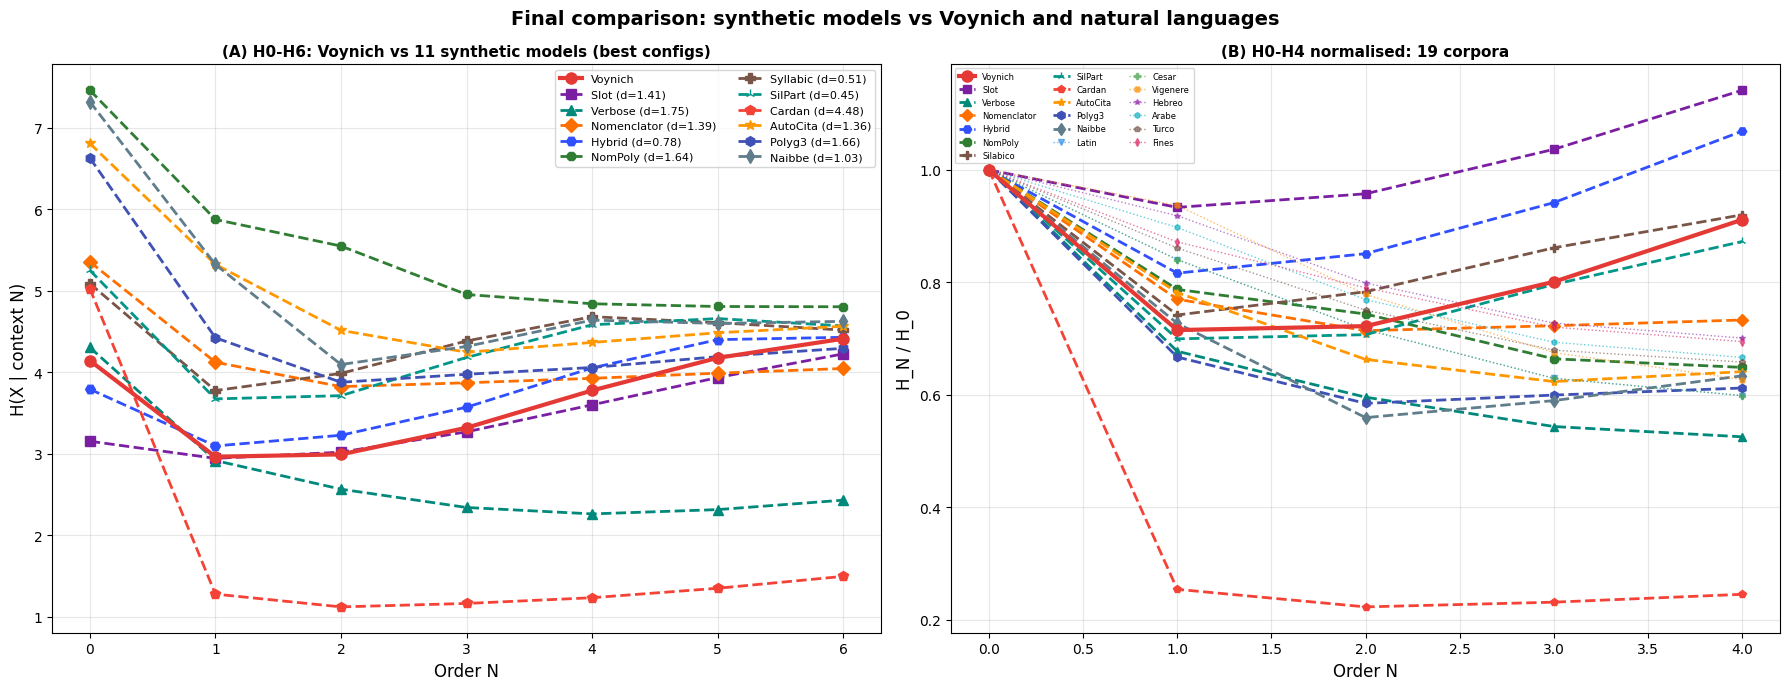

Saved: comparison_curves_synthetics.png


In [47]:
# ── Cell 24: Final comparison — master chart ───────────────────
# Multilingual results hardcoded from previous notebook
MULTI_H04 = {
    'Latin':    [4.121, 3.463, 2.951, 2.593, 2.466],
    'Cesar':    [4.121, 3.463, 2.951, 2.593, 2.466],
    'Vigenere': [4.616, 4.324, 3.593, 3.116, 2.894],
    'Hebreo':   [4.230, 3.885, 3.379, 3.077, 2.964],
    'Arabe':    [4.370, 3.922, 3.361, 3.030, 2.912],
    'Turco':    [4.351, 3.746, 3.265, 2.956, 2.863],
    'Fines':    [3.954, 3.447, 3.125, 2.848, 2.746],
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Panel A: H0-H6 Voynich + 11 synthetic models
ax1.plot(ordenes_ext, VOYNICH_TARGET['H_curve'], 'o-',
         color=COLOR_MAP['Voynich'], lw=3, markersize=8, label='Voynich', zorder=10)
ax1.plot(ordenes_ext, H_slot_ext, 's--',
         color=COLOR_MAP['Slot'], lw=2, markersize=7, label=f'Slot (d={best_slot["distance"]:.2f})')
ax1.plot(ordenes_ext, H_verbose_ext, '^--',
         color=COLOR_MAP['Verbose'], lw=2, markersize=7, label=f'Verbose (d={best_verbose["distance"]:.2f})')
ax1.plot(ordenes_ext, H_nom_ext, 'D--',
         color=COLOR_MAP['Nomenclator'], lw=2, markersize=7, label=f'Nomenclator (d={best_nom["distance"]:.2f})')
ax1.plot(ordenes_ext, H_hybrid_ext, 'H--',
         color=COLOR_MAP['Hybrid'], lw=2, markersize=7, label=f'Hybrid (d={best_hybrid["distance"]:.2f})')
ax1.plot(ordenes_ext, H_nompoly_ext, '8--',
         color=COLOR_MAP['NomPoly'], lw=2, markersize=7, label=f'NomPoly (d={best_np["distance"]:.2f})')
ax1.plot(ordenes_ext, H_syl_ext, 'P--',
         color=COLOR_MAP['Silabico'], lw=2, markersize=7, label=f'Syllabic (d={best_syl["distance"]:.2f})')
ax1.plot(ordenes_ext, H_sp_ext, '2--',
         color=COLOR_MAP['SilPart'], lw=2, markersize=7, label=f'SilPart (d={best_sp["distance"]:.2f})')
# 4 literature models
ax1.plot(ordenes_ext, H_cardan_ext, 'p--',
         color=COLOR_MAP['Cardan'], lw=2, markersize=7, label=f'Cardan (d={best_cardan["distance"]:.2f})')
ax1.plot(ordenes_ext, H_autocita_ext, '*--',
         color=COLOR_MAP['AutoCita'], lw=2, markersize=7, label=f'AutoCita (d={best_autocita["distance"]:.2f})')
ax1.plot(ordenes_ext, H_polyg3_ext, 'h--',
         color=COLOR_MAP['Polyg3'], lw=2, markersize=7, label=f'Polyg3 (d={best_polyg3["distance"]:.2f})')
ax1.plot(ordenes_ext, H_naibbe_ext, 'd--',
         color=COLOR_MAP['Naibbe'], lw=2, markersize=7, label=f'Naibbe (d={best_naibbe["distance"]:.2f})')
ax1.set_xlabel('Order N', fontsize=12)
ax1.set_ylabel('H(X | context N)', fontsize=12)
ax1.set_title('(A) H0-H6: Voynich vs 11 synthetic models (best configs)', fontsize=11, fontweight='bold')
ax1.legend(fontsize=8, ncol=2)
ax1.grid(True, alpha=0.3)

# Panel B: H0-H4 normalised, all models
ordenes_plot = [0, 1, 2, 3, 4]

# Voynich
v_norm = [v / VOYNICH_TARGET['H_curve'][0] for v in VOYNICH_TARGET['H_curve'][:5]]
ax2.plot(ordenes_plot, v_norm, 'o-', color=COLOR_MAP['Voynich'], lw=3, markersize=8,
         label='Voynich', zorder=10)

# Synthetic models (including the 4 new ones)
for name, h_ext in [('Slot', H_slot_ext), ('Verbose', H_verbose_ext),
                     ('Nomenclator', H_nom_ext), ('Hybrid', H_hybrid_ext),
                     ('NomPoly', H_nompoly_ext), ('Silabico', H_syl_ext),
                     ('SilPart', H_sp_ext),
                     ('Cardan', H_cardan_ext), ('AutoCita', H_autocita_ext),
                     ('Polyg3', H_polyg3_ext), ('Naibbe', H_naibbe_ext)]:
    norm = [v / h_ext[0] for v in h_ext[:5]]
    ax2.plot(ordenes_plot, norm, MARKER_MAP[name] + '--',
             color=COLOR_MAP[name], lw=2, markersize=6, label=name)

# Multilingual
for name, h_vals in MULTI_H04.items():
    norm = [v / h_vals[0] for v in h_vals]
    ax2.plot(ordenes_plot, norm, MARKER_MAP[name] + ':',
             color=COLOR_MAP[name], lw=1, markersize=4, alpha=0.6, label=name)

ax2.set_xlabel('Order N', fontsize=12)
ax2.set_ylabel('H_N / H_0', fontsize=12)
ax2.set_title('(B) H0-H4 normalised: 19 corpora', fontsize=11, fontweight='bold')
ax2.legend(fontsize=6, ncol=3, loc='best')
ax2.grid(True, alpha=0.3)

fig.suptitle('Final comparison: synthetic models vs Voynich and natural languages',
             fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig('images/comparacion_curvas_sinteticos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: comparison_curves_synthetics.png')

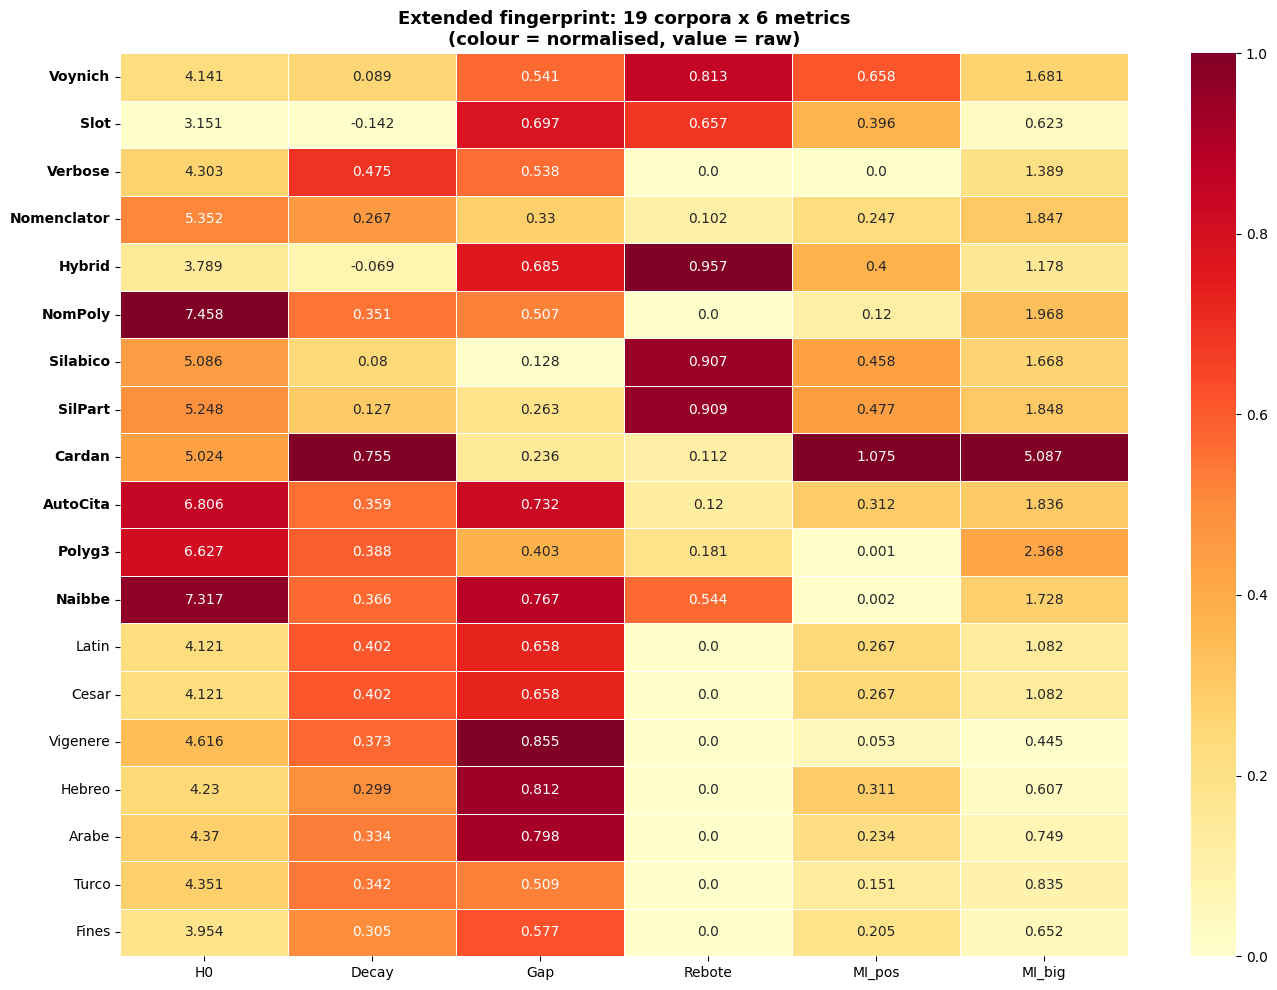

Saved: fingerprint_synthetics.png


In [48]:
# ── Cell 25: Extended fingerprint heatmap ─────────────────────────
# Hardcoded multilingual metrics
MULTI_METRICS = {
    'Latin':    {'H0': 4.121, 'Decay': 0.402, 'Gap': 0.658, 'Rebote': 0.000, 'MI_pos': 0.267, 'MI_big': 1.082},
    'Cesar':    {'H0': 4.121, 'Decay': 0.402, 'Gap': 0.658, 'Rebote': 0.000, 'MI_pos': 0.267, 'MI_big': 1.082},
    'Vigenere': {'H0': 4.616, 'Decay': 0.373, 'Gap': 0.855, 'Rebote': 0.000, 'MI_pos': 0.053, 'MI_big': 0.445},
    'Hebreo':   {'H0': 4.230, 'Decay': 0.299, 'Gap': 0.812, 'Rebote': 0.000, 'MI_pos': 0.311, 'MI_big': 0.607},
    'Arabe':    {'H0': 4.370, 'Decay': 0.334, 'Gap': 0.798, 'Rebote': 0.000, 'MI_pos': 0.234, 'MI_big': 0.749},
    'Turco':    {'H0': 4.351, 'Decay': 0.342, 'Gap': 0.509, 'Rebote': 0.000, 'MI_pos': 0.151, 'MI_big': 0.835},
    'Fines':    {'H0': 3.954, 'Decay': 0.305, 'Gap': 0.577, 'Rebote': 0.000, 'MI_pos': 0.205, 'MI_big': 0.652},
}

# Build metrics for synthetic models
slot_mc = metricas_curva('Slot', H_slot_ext[:5], [0,1,2,3,4])
verbose_mc = metricas_curva('Verbose', H_verbose_ext[:5], [0,1,2,3,4])
nom_mc = metricas_curva('Nomenclator', H_nom_ext[:5], [0,1,2,3,4])

all_metrics = {
    'Voynich': {
        'H0': VOYNICH_TARGET['H0'], 'Decay': VOYNICH_TARGET['decay'],
        'Gap': VOYNICH_TARGET['gap'], 'Rebote': VOYNICH_TARGET['rebote'],
        'MI_pos': VOYNICH_TARGET['MI_pos'], 'MI_big': VOYNICH_TARGET['MI_big'],
    },
    'Slot': {
        'H0': H_slot_ext[0],
        'Decay': (H_slot_ext[0] - H_slot_ext[4]) / H_slot_ext[0],
        'Gap': spec_sb['gap'], 'Rebote': slot_mc['rebote'],
        'MI_pos': mi_p_sb, 'MI_big': mi_b_sb,
    },
    'Verbose': {
        'H0': H_verbose_ext[0],
        'Decay': (H_verbose_ext[0] - H_verbose_ext[4]) / H_verbose_ext[0],
        'Gap': spec_vb['gap'], 'Rebote': verbose_mc['rebote'],
        'MI_pos': mi_p_vb, 'MI_big': mi_b_vb,
    },
    'Nomenclator': {
        'H0': H_nom_ext[0],
        'Decay': (H_nom_ext[0] - H_nom_ext[4]) / H_nom_ext[0],
        'Gap': spec_nb['gap'], 'Rebote': nom_mc['rebote'],
        'MI_pos': mi_p_nb, 'MI_big': mi_b_nb,
    },
    'Hybrid': {
        'H0': H_hybrid_ext[0],
        'Decay': (H_hybrid_ext[0] - H_hybrid_ext[4]) / H_hybrid_ext[0],
        'Gap': spec_hyb['gap'], 'Rebote': metricas_curva('Hybrid', H_hybrid_ext[:5], [0,1,2,3,4])['rebote'],
        'MI_pos': mi_p_hyb, 'MI_big': mi_b_hyb,
    },
    'NomPoly': {
        'H0': H_nompoly_ext[0],
        'Decay': (H_nompoly_ext[0] - H_nompoly_ext[4]) / H_nompoly_ext[0],
        'Gap': spec_npy['gap'], 'Rebote': metricas_curva('NomPoly', H_nompoly_ext[:5], [0,1,2,3,4])['rebote'],
        'MI_pos': mi_p_npy, 'MI_big': mi_b_npy,
    },
    'Silabico': {
        'H0': H_syl_ext[0],
        'Decay': (H_syl_ext[0] - H_syl_ext[4]) / H_syl_ext[0],
        'Gap': spec_syl['gap'], 'Rebote': metricas_curva('Silabico', H_syl_ext[:5], [0,1,2,3,4])['rebote'],
        'MI_pos': mi_p_syl, 'MI_big': mi_b_syl,
    },
    'SilPart': {
        'H0': H_sp_ext[0],
        'Decay': (H_sp_ext[0] - H_sp_ext[4]) / H_sp_ext[0],
        'Gap': spec_sp['gap'], 'Rebote': metricas_curva('SilPart', H_sp_ext[:5], [0,1,2,3,4])['rebote'],
        'MI_pos': mi_p_sp, 'MI_big': mi_b_sp,
    },
    # 4 literature models
    'Cardan': {
        'H0': H_cardan_ext[0],
        'Decay': (H_cardan_ext[0] - H_cardan_ext[4]) / H_cardan_ext[0],
        'Gap': spec_crd['gap'], 'Rebote': metricas_curva('Cardan', H_cardan_ext[:5], [0,1,2,3,4])['rebote'],
        'MI_pos': mi_p_crd, 'MI_big': mi_b_crd,
    },
    'AutoCita': {
        'H0': H_autocita_ext[0],
        'Decay': (H_autocita_ext[0] - H_autocita_ext[4]) / H_autocita_ext[0],
        'Gap': spec_ac['gap'], 'Rebote': metricas_curva('AutoCita', H_autocita_ext[:5], [0,1,2,3,4])['rebote'],
        'MI_pos': mi_p_ac, 'MI_big': mi_b_ac,
    },
    'Polyg3': {
        'H0': H_polyg3_ext[0],
        'Decay': (H_polyg3_ext[0] - H_polyg3_ext[4]) / H_polyg3_ext[0],
        'Gap': spec_pg['gap'], 'Rebote': metricas_curva('Polyg3', H_polyg3_ext[:5], [0,1,2,3,4])['rebote'],
        'MI_pos': mi_p_pg, 'MI_big': mi_b_pg,
    },
    'Naibbe': {
        'H0': H_naibbe_ext[0],
        'Decay': (H_naibbe_ext[0] - H_naibbe_ext[4]) / H_naibbe_ext[0],
        'Gap': spec_nb2['gap'], 'Rebote': metricas_curva('Naibbe', H_naibbe_ext[:5], [0,1,2,3,4])['rebote'],
        'MI_pos': mi_p_nb2, 'MI_big': mi_b_nb2,
    },
}
all_metrics.update(MULTI_METRICS)

# DataFrame
df_all = pd.DataFrame(all_metrics).T
df_all = df_all.loc[ALL_ORDER]

# Normalizar
df_norm = (df_all - df_all.min()) / (df_all.max() - df_all.min())

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(df_norm, annot=df_all.round(3).values, fmt='', cmap='YlOrRd',
            vmin=0, vmax=1.0, linewidths=0.5, ax=ax,
            xticklabels=df_all.columns, yticklabels=df_all.index)
ax.set_title('Extended fingerprint: 19 corpora x 6 metrics\n(colour = normalised, value = raw)',
             fontsize=13, fontweight='bold')

# Highlight synthetic models
for i, name in enumerate(ALL_ORDER):
    if name in SYNTH_ORDER:
        ax.get_yticklabels()[i].set_fontweight('bold')

plt.tight_layout()
fig.savefig('images/fingerprint_sinteticos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fingerprint_synthetics.png')

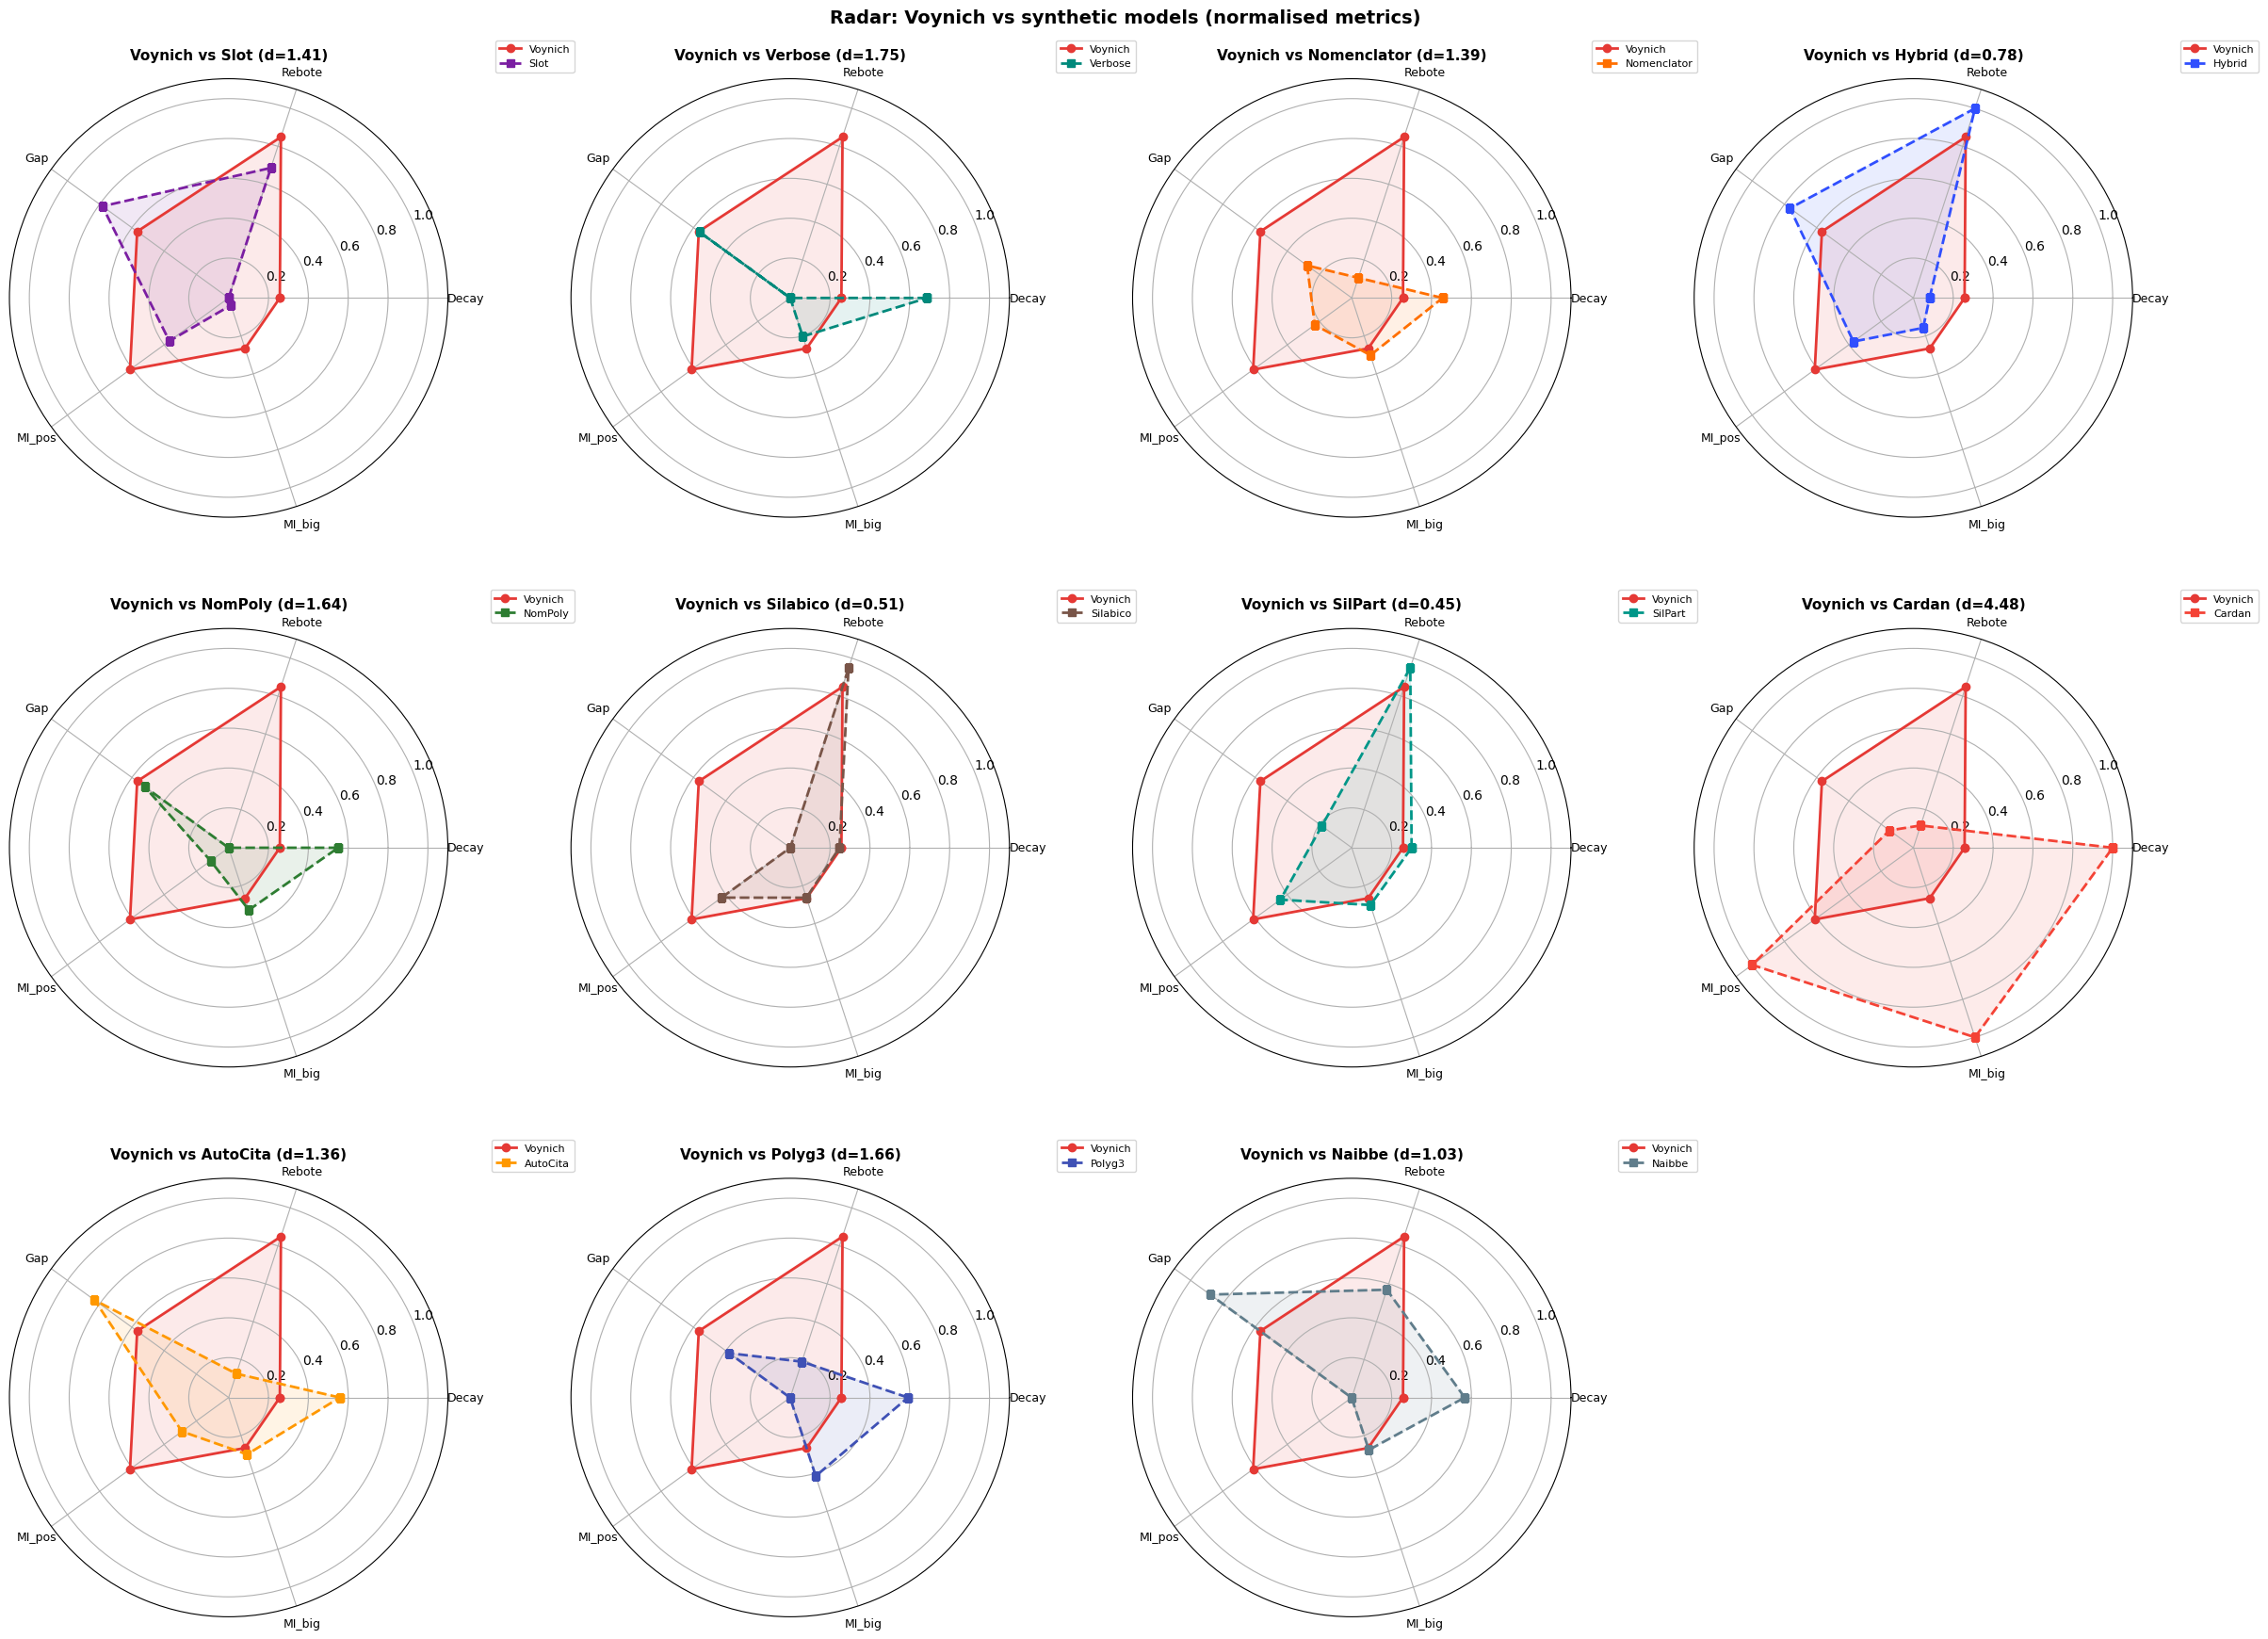

Saved: radar_synthetics.png


In [49]:
# ── Cell 26: Radar chart ───────────────────────────────────────────
radar_metrics = ['Decay', 'Rebote', 'Gap', 'MI_pos', 'MI_big']
n_metrics = len(radar_metrics)
angles = np.linspace(0, 2 * np.pi, n_metrics, endpoint=False).tolist()
angles += angles[:1]  # cerrar poligono

synth_names = ['Slot', 'Verbose', 'Nomenclator', 'Hybrid', 'NomPoly', 'Silabico', 'SilPart',
               'Cardan', 'AutoCita', 'Polyg3', 'Naibbe']
n_models = len(synth_names)
n_cols = 4
n_rows = (n_models + n_cols - 1) // n_cols  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, 6 * n_rows), subplot_kw=dict(polar=True))
axes = axes.flatten()

for ax, synth_name in zip(axes[:n_models], synth_names):
    # Voynich
    vals_v = [df_norm.loc['Voynich', m] for m in radar_metrics]
    vals_v += vals_v[:1]
    ax.plot(angles, vals_v, 'o-', color=COLOR_MAP['Voynich'], lw=2, label='Voynich')
    ax.fill(angles, vals_v, color=COLOR_MAP['Voynich'], alpha=0.1)
    
    # Synthetic
    vals_s = [df_norm.loc[synth_name, m] for m in radar_metrics]
    vals_s += vals_s[:1]
    ax.plot(angles, vals_s, 's--', color=COLOR_MAP[synth_name], lw=2, label=synth_name)
    ax.fill(angles, vals_s, color=COLOR_MAP[synth_name], alpha=0.1)
    
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(radar_metrics, fontsize=9)
    # Compute distance for title
    m = all_metrics[synth_name]
    d = voynich_distance({'rebote': m['Rebote'], 'decay': m['Decay'],
                          'MI_pos': m['MI_pos'], 'MI_big': m['MI_big'], 'gap': m['Gap']},
                         VOYNICH_TARGET)
    ax.set_title(f'Voynich vs {synth_name} (d={d:.2f})', fontsize=11, fontweight='bold', pad=15)
    ax.legend(loc='upper right', fontsize=8, bbox_to_anchor=(1.3, 1.1))
    ax.set_ylim(0, 1.1)

# Ocultar ejes sobrantes
for i in range(n_models, len(axes)):
    axes[i].set_visible(False)

fig.suptitle('Radar: Voynich vs synthetic models (normalised metrics)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig('images/radar_sinteticos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: radar_synthetics.png')

In [50]:
# ── Cell 27: Distance-to-Voynich ranking table ────────────────────

# Compute distance for all non-Voynich corpora
ranking = []

for name in ALL_ORDER:
    if name == 'Voynich':
        continue
    m = all_metrics[name]
    metrics = {
        'rebote': m['Rebote'], 'decay': m['Decay'],
        'MI_pos': m['MI_pos'], 'MI_big': m['MI_big'], 'gap': m['Gap'],
    }
    dist = voynich_distance(metrics, VOYNICH_TARGET)
    ranking.append((name, dist, m['Rebote'], m['Decay'], m['MI_pos'], m['MI_big']))

ranking.sort(key=lambda x: x[1])

print('=' * 80)
print('RANKING: Weighted distance to Voynich')
print('=' * 80)
print(f'{"#":>3} {"Corpus":<14} {"Distance":>10} {"Bounce":>8} {"Decay":>8} {"MI_pos":>8} {"MI_big":>8}')
print('-' * 80)
synth_set = set(SYNTH_ORDER)
for i, (name, dist, reb, dec, mip, mib) in enumerate(ranking, 1):
    marker = ' <--' if name in synth_set else ''
    print(f'{i:>3} {name:<14} {dist:>10.3f} {reb:>8.3f} {dec:>8.3f} {mip:>8.3f} {mib:>8.3f}{marker}')
print('=' * 80)

RANKING: Weighted distance to Voynich
  # Corpus           Distance   Bounce    Decay   MI_pos   MI_big
--------------------------------------------------------------------------------
  1 SilPart             0.445    0.909    0.127    0.477    1.848 <--
  2 Silabico            0.506    0.907    0.080    0.458    1.668 <--
  3 Hybrid              0.783    0.957   -0.069    0.400    1.178 <--
  4 Naibbe              1.035    0.544    0.366    0.002    1.728 <--
  5 AutoCita            1.356    0.120    0.359    0.312    1.836 <--
  6 Nomenclator         1.386    0.102    0.267    0.247    1.847 <--
  7 Slot                1.410    0.657   -0.142    0.396    0.623 <--
  8 NomPoly             1.637    0.000    0.351    0.120    1.968 <--
  9 Polyg3              1.659    0.181    0.388    0.001    2.368 <--
 10 Latin               1.721    0.000    0.402    0.267    1.082
 11 Cesar               1.721    0.000    0.402    0.267    1.082
 12 Verbose             1.749    0.000    0.475    0.

## Weight sensitivity analysis

The weighted Euclidean distance uses fixed weights: bounce=3, decay=2, MI_pos=1.5, MI_big=1.5, gap=1.
Is the ranking robust to weight changes? We evaluate:

1. **Individual perturbation**: each weight ×0.5 and ×1.5 (10 variants)
2. **Alternative schemes**: uniform weights, bounce-only, MI-only, priority inversion
3. **Monte Carlo**: 500 random weight sets (Dirichlet)

**Metric**: Spearman correlation (ρ) between the base ranking and each perturbed ranking.
If ρ > 0.9 in most perturbations, the result is robust.

ANALYSIS OF SENSITIVITY OF WEIGHTS

1. Perturbaciones individuales y esquemas alternativos:
Esquema                ρ Spearman Top-1        Top-3
------------------------------------------------------------------------------------------
rebote×0.5                 0.9818 SilPart      SilPart, Silabico, Hybrid
rebote×1.5                 0.9636 SilPart      SilPart, Silabico, Hybrid
decay×0.5                  1.0000 SilPart      SilPart, Silabico, Hybrid
decay×1.5                  1.0000 SilPart      SilPart, Silabico, Hybrid
MI_pos×0.5                 0.9909 SilPart      SilPart, Silabico, Hybrid
MI_pos×1.5                 0.9909 SilPart      SilPart, Silabico, Hybrid
MI_big×0.5                 0.9636 SilPart      SilPart, Silabico, Hybrid
MI_big×1.5                 0.9909 SilPart      SilPart, Silabico, Hybrid
gap×0.5                    1.0000 SilPart      SilPart, Silabico, Hybrid
gap×1.5                    1.0000 SilPart      SilPart, Silabico, Hybrid
Uniform                    0.9818 

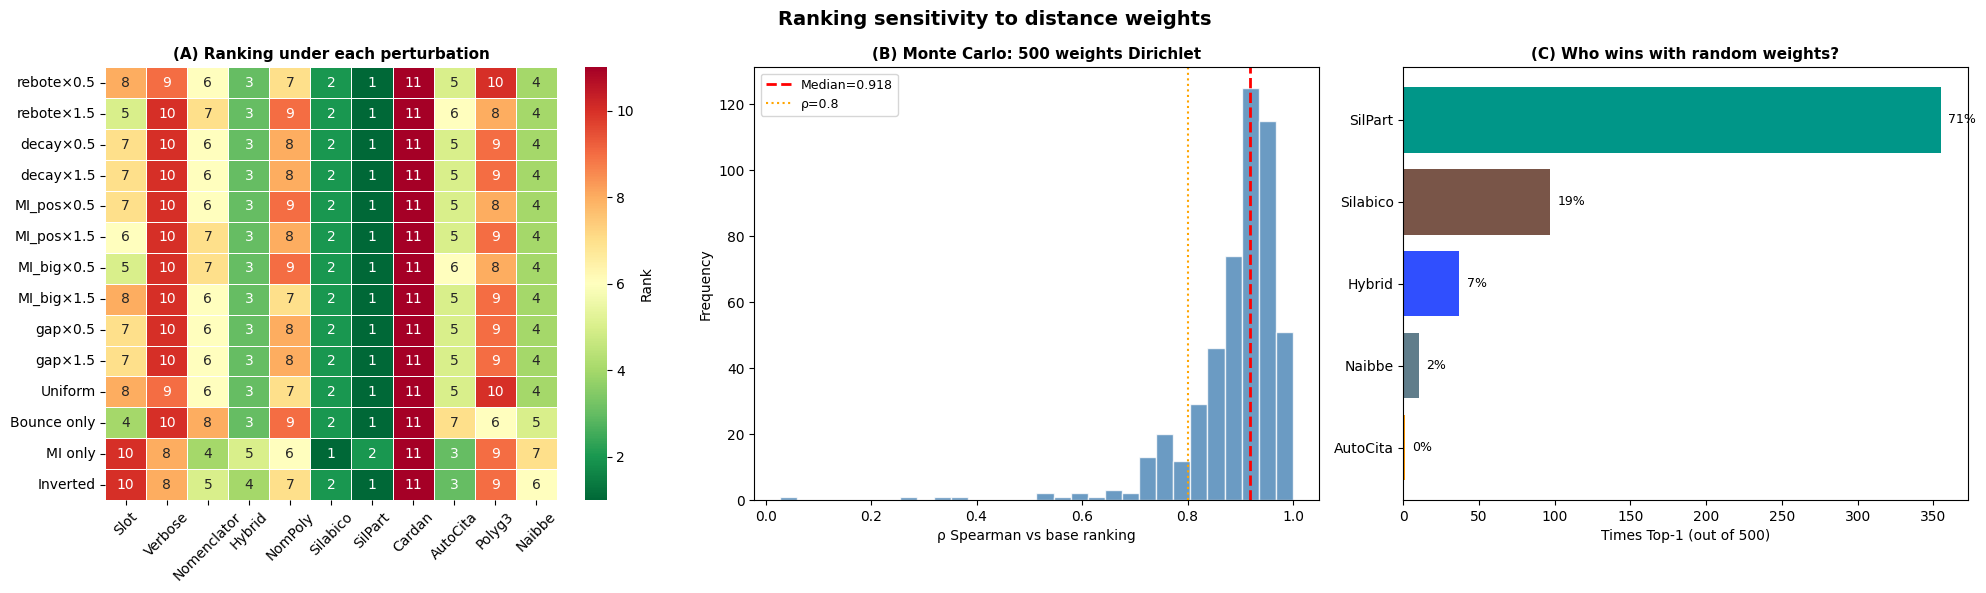

Saved: sensitivity_weights.png


In [51]:
# ── Weight sensitivity analysis ──────────────────────────
from scipy.stats import spearmanr

# Base weights
PESOS_BASE = {'rebote': 3.0, 'decay': 2.0, 'MI_pos': 1.5, 'MI_big': 1.5, 'gap': 1.0}
KEYS = list(PESOS_BASE.keys())

# Synthetic models (excluding Voynich)
synth_names = [n for n in SYNTH_ORDER if n != 'Voynich']

def compute_ranking(pesos_dict):
    """Compute ranking of synthetic models under a given weight set."""
    dists = []
    for name in synth_names:
        m = all_metrics[name]
        d2 = 0.0
        for key in KEYS:
            cap_key = {'rebote': 'Rebote', 'decay': 'Decay', 'MI_pos': 'MI_pos',
                       'MI_big': 'MI_big', 'gap': 'Gap'}[key]
            diff = m[cap_key] - VOYNICH_TARGET[key]
            d2 += pesos_dict[key] * diff ** 2
        dists.append(math.sqrt(d2))
    return dists

# Ranking base
base_dists = compute_ranking(PESOS_BASE)
base_order = np.argsort(base_dists)
base_ranks = np.empty_like(base_order)
base_ranks[base_order] = np.arange(len(base_order))

# ── 1. Individual perturbation: each weight x0.5 and x1.5 ──
perturbaciones = {}
for key in KEYS:
    for factor, label in [(0.5, f'{key}×0.5'), (1.5, f'{key}×1.5')]:
        p = dict(PESOS_BASE)
        p[key] = PESOS_BASE[key] * factor
        perturbaciones[label] = p

# ── 2. Esquemas alternativos ──
perturbaciones['Uniform'] = {k: 1.0 for k in KEYS}
perturbaciones['Bounce only'] = {k: (5.0 if k == 'rebote' else 0.1) for k in KEYS}
perturbaciones['MI only'] = {k: (5.0 if k in ('MI_pos', 'MI_big') else 0.1) for k in KEYS}
perturbaciones['Inverted'] = {'rebote': 1.0, 'decay': 1.5, 'MI_pos': 2.0, 'MI_big': 3.0, 'gap': 3.0}

# Compute rankings and correlations
sensitivity_results = []
ranking_matrix = {}  # perturbation_name -> sorted list of model names

for label, pesos in perturbaciones.items():
    dists = compute_ranking(pesos)
    order = np.argsort(dists)
    ranks = np.empty_like(order)
    ranks[order] = np.arange(len(order))
    rho, pval = spearmanr(base_ranks, ranks)
    top1 = synth_names[order[0]]
    top3 = [synth_names[order[i]] for i in range(3)]
    sensitivity_results.append({
        'label': label, 'rho': rho, 'pval': pval,
        'top1': top1, 'top3': top3,
        'ranks': {synth_names[i]: int(ranks[i]) + 1 for i in range(len(synth_names))},
    })
    ranking_matrix[label] = [synth_names[order[i]] for i in range(len(order))]

# ── 3. Monte Carlo: 500 conjuntos randoms (Dirichlet) ──
rng_mc = np.random.RandomState(42)
mc_rhos = []
mc_top1_counts = Counter()
mc_top3_counts = Counter()
n_mc = 500

for _ in range(n_mc):
    # Dirichlet genera weights positivos que suman ~5 (escala similar a la base)
    raw = rng_mc.dirichlet(np.ones(5))
    pesos_mc = {k: float(raw[i] * 5 * len(KEYS)) for i, k in enumerate(KEYS)}
    dists = compute_ranking(pesos_mc)
    order = np.argsort(dists)
    ranks = np.empty_like(order)
    ranks[order] = np.arange(len(order))
    rho, _ = spearmanr(base_ranks, ranks)
    mc_rhos.append(rho)
    mc_top1_counts[synth_names[order[0]]] += 1
    for i in range(3):
        mc_top3_counts[synth_names[order[i]]] += 1

# ── Results ──
print('=' * 90)
print('ANALYSIS OF SENSITIVITY OF WEIGHTS')
print('=' * 90)
print()
print('1. Perturbaciones individuales y esquemas alternativos:')
print(f'{"Esquema":<20} {"ρ Spearman":>12} {"Top-1":<12} {"Top-3"}')
print('-' * 90)
for r in sensitivity_results:
    t3 = ', '.join(r['top3'])
    print(f'{r["label"]:<20} {r["rho"]:>12.4f} {r["top1"]:<12} {t3}')

print()
print(f'2. Monte Carlo ({n_mc} conjuntos Dirichlet):')
print(f'   ρ medio  = {np.mean(mc_rhos):.4f}')
print(f'   ρ mediana = {np.median(mc_rhos):.4f}')
print(f'   ρ min    = {np.min(mc_rhos):.4f}')
print(f'   ρ > 0.8  = {sum(1 for r in mc_rhos if r > 0.8) / n_mc * 100:.1f}%')
print(f'   ρ > 0.9  = {sum(1 for r in mc_rhos if r > 0.9) / n_mc * 100:.1f}%')
print()
print(f'   Frequency Top-1 ({n_mc} sorteos):')
for name, count in mc_top1_counts.most_common():
    print(f'     {name:<14} {count:>4} ({count/n_mc*100:.1f}%)')
print()
print(f'   Frequency Top-3 ({n_mc} sorteos):')
for name, count in mc_top3_counts.most_common():
    print(f'     {name:<14} {count:>4} ({count/n_mc*100:.1f}%)')

# ── Visualizacion ──
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Panel A: Ranking heatmap under perturbations
pert_labels = [r['label'] for r in sensitivity_results]
rank_data = np.zeros((len(pert_labels), len(synth_names)))
for i, r in enumerate(sensitivity_results):
    for j, name in enumerate(synth_names):
        rank_data[i, j] = r['ranks'][name]

ax = axes[0]
sns.heatmap(rank_data, annot=True, fmt='.0f', cmap='RdYlGn_r',
            xticklabels=synth_names, yticklabels=pert_labels,
            ax=ax, vmin=1, vmax=len(synth_names),
            linewidths=0.5, cbar_kws={'label': 'Rank'})
ax.set_title('(A) Ranking under each perturbation', fontsize=11, fontweight='bold')
ax.tick_params(axis='x', rotation=45)

# Panel B: Histograma de rho Monte Carlo
ax = axes[1]
ax.hist(mc_rhos, bins=30, color='steelblue', edgecolor='white', alpha=0.8)
ax.axvline(np.median(mc_rhos), color='red', lw=2, ls='--', label=f'Median={np.median(mc_rhos):.3f}')
ax.axvline(0.8, color='orange', lw=1.5, ls=':', label='ρ=0.8')
ax.set_xlabel('ρ Spearman vs base ranking')
ax.set_ylabel('Frequency')
ax.set_title(f'(B) Monte Carlo: {n_mc} weights Dirichlet', fontsize=11, fontweight='bold')
ax.legend(fontsize=9)

# Panel C: Frequency Top-1 Monte Carlo
ax = axes[2]
names_sorted = [n for n, _ in mc_top1_counts.most_common()]
counts_sorted = [mc_top1_counts[n] for n in names_sorted]
colors = [COLOR_MAP.get(n, '#999999') for n in names_sorted]
ax.barh(range(len(names_sorted)), counts_sorted, color=colors)
ax.set_yticks(range(len(names_sorted)))
ax.set_yticklabels(names_sorted)
ax.set_xlabel(f'Times Top-1 (out of {n_mc})')
ax.set_title(f'(C) Who wins with random weights?', fontsize=11, fontweight='bold')
ax.invert_yaxis()
for i, (n, c) in enumerate(zip(names_sorted, counts_sorted)):
    ax.text(c + 5, i, f'{c/n_mc*100:.0f}%', va='center', fontsize=9)

fig.suptitle('Ranking sensitivity to distance weights',
             fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig('images/sensibilidad_pesos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: sensitivity_weights.png')


In [52]:
# ── Cell 28: Save results to JSON ─────────────────────────────
results = {
    'voynich_target': {k: (v if not isinstance(v, (np.floating, np.integer)) else float(v))
                       for k, v in VOYNICH_TARGET.items()},
    'slot': {
        'best_config': {'tau': best_slot['tau'], 'noise': best_slot['noise']},
        'best_distance': best_slot['distance'],
        'H_curve_ext': H_slot_ext,
        'metrics': {k: float(v) for k, v in all_metrics['Slot'].items()},
        'sweep_results': [{
            'tau': r['tau'], 'noise': r['noise'], 'distance': r['distance'],
            'rebote': r['rebote'], 'decay': r['decay'],
        } for r in slot_sweep_results[:10]],
    },
    'verbose': {
        'best_config': best_verbose['config'],
        'best_distance': best_verbose['distance'],
        'H_curve_ext': H_verbose_ext,
        'metrics': {k: float(v) for k, v in all_metrics['Verbose'].items()},
        'sweep_results': [{
            'config': r['config'], 'distance': r['distance'],
            'rebote': r['rebote'], 'decay': r['decay'],
        } for r in verbose_sweep_results],
    },
    'nomenclator': {
        'best_config': {
            'n_homophones': best_nom['n_homophones'],
            'p_nom_use': best_nom['p_nom_use'],
            'null_rate': best_nom['null_rate'],
        },
        'best_distance': best_nom['distance'],
        'H_curve_ext': H_nom_ext,
        'metrics': {k: float(v) for k, v in all_metrics['Nomenclator'].items()},
        'sweep_results': [{
            'n_homophones': r['n_homophones'], 'p_nom_use': r['p_nom_use'],
            'null_rate': r['null_rate'], 'distance': r['distance'],
            'rebote': r['rebote'], 'decay': r['decay'],
        } for r in nom_sweep_results[:10]],
    },
    'hybrid': {
        'best_config': {
            'tau': best_hybrid['tau'],
            'alpha': best_hybrid['alpha'],
            'noise': best_hybrid['noise'],
        },
        'best_distance': best_hybrid['distance'],
        'H_curve_ext': H_hybrid_ext,
        'metrics': {k: float(v) for k, v in all_metrics['Hybrid'].items()},
        'sweep_results': [{
            'tau': r['tau'], 'alpha': r['alpha'], 'noise': r['noise'],
            'distance': r['distance'], 'rebote': r['rebote'], 'decay': r['decay'],
        } for r in hybrid_sweep_results[:10]],
    },
    'nompoly': {
        'best_config': {
            'shift_period': best_np['shift_period'],
            'shift_amount': best_np['shift_amount'],
            'n_homophones': best_np['n_homophones'],
        },
        'best_distance': best_np['distance'],
        'H_curve_ext': H_nompoly_ext,
        'metrics': {k: float(v) for k, v in all_metrics['NomPoly'].items()},
        'sweep_results': [{
            'shift_period': r['shift_period'], 'shift_amount': r['shift_amount'],
            'n_homophones': r['n_homophones'], 'distance': r['distance'],
            'rebote': r['rebote'], 'decay': r['decay'],
        } for r in nompoly_sweep_results[:10]],
    },
    'silabico': {
        'best_config': {
            'n_types': best_syl['n_types'],
            'intra_k': best_syl['intra_k'],
            'pos_bias': best_syl['pos_bias'],
            'tau': best_syl['tau'],
        },
        'best_distance': best_syl['distance'],
        'H_curve_ext': H_syl_ext,
        'metrics': {k: float(v) for k, v in all_metrics['Silabico'].items()},
        'sweep_results': [{
            'n_types': r['n_types'], 'intra_k': r['intra_k'],
            'pos_bias': r['pos_bias'], 'tau': r['tau'],
            'distance': r['distance'], 'rebote': r['rebote'], 'decay': r['decay'],
        } for r in syl_sweep_results[:10]],
    },
    'silpart': {
        'best_config': {
            'n_types': best_sp['n_types'],
            'intra_k': best_sp['intra_k'],
            'glyph_overlap': best_sp['glyph_overlap'],
            'pos_bias': best_sp['pos_bias'],
            'tau': best_sp['tau'],
        },
        'best_distance': best_sp['distance'],
        'H_curve_ext': H_sp_ext,
        'metrics': {k: float(v) for k, v in all_metrics['SilPart'].items()},
        'sweep_results': [{
            'n_types': r['n_types'], 'intra_k': r['intra_k'],
            'glyph_overlap': r['glyph_overlap'], 'pos_bias': r['pos_bias'],
            'distance': r['distance'], 'rebote': r['rebote'], 'decay': r['decay'],
            'MI_pos': r['MI_pos'], 'MI_big': r['MI_big'],
        } for r in sp_sweep_results[:10]],
    },
    # 4 literature models
    'cardan': {
        'best_config': {
            'n_rows': best_cardan['n_rows'],
            'p_prefix': best_cardan['p_prefix'],
            'p_suffix': best_cardan['p_suffix'],
        },
        'best_distance': best_cardan['distance'],
        'H_curve_ext': H_cardan_ext,
        'metrics': {k: float(v) for k, v in all_metrics['Cardan'].items()},
        'sweep_results': [{
            'n_rows': r['n_rows'], 'p_prefix': r['p_prefix'],
            'p_suffix': r['p_suffix'], 'distance': r['distance'],
            'rebote': r['rebote'], 'decay': r['decay'],
        } for r in cardan_sweep_results[:10]],
    },
    'autocita': {
        'best_config': {
            'seed_size': best_autocita['seed_size'],
            'p_sub': best_autocita['p_sub'],
            'p_ins': best_autocita['p_ins'],
            'p_del': best_autocita['p_del'],
        },
        'best_distance': best_autocita['distance'],
        'H_curve_ext': H_autocita_ext,
        'metrics': {k: float(v) for k, v in all_metrics['AutoCita'].items()},
        'sweep_results': [{
            'seed_size': r['seed_size'], 'p_sub': r['p_sub'],
            'p_ins': r['p_ins'], 'p_del': r['p_del'],
            'distance': r['distance'], 'rebote': r['rebote'], 'decay': r['decay'],
        } for r in autocita_sweep_results[:10]],
    },
    'polyg3': {
        'best_config': {
            'n_alphabets': best_polyg3['n_alphabets'],
            'sub_max_len': best_polyg3['sub_max_len'],
        },
        'best_distance': best_polyg3['distance'],
        'H_curve_ext': H_polyg3_ext,
        'metrics': {k: float(v) for k, v in all_metrics['Polyg3'].items()},
        'sweep_results': [{
            'n_alphabets': r['n_alphabets'], 'sub_max_len': r['sub_max_len'],
            'distance': r['distance'], 'rebote': r['rebote'], 'decay': r['decay'],
        } for r in polyg3_sweep_results[:10]],
    },
    'naibbe': {
        'best_config': {
            'group_max': best_naibbe['group_max'],
            'n_homophones': best_naibbe['n_homophones'],
            'codeword_max': best_naibbe['codeword_max'],
        },
        'best_distance': best_naibbe['distance'],
        'H_curve_ext': H_naibbe_ext,
        'metrics': {k: float(v) for k, v in all_metrics['Naibbe'].items()},
        'sweep_results': [{
            'group_max': r['group_max'], 'n_homophones': r['n_homophones'],
            'codeword_max': r['codeword_max'], 'distance': r['distance'],
            'rebote': r['rebote'], 'decay': r['decay'],
        } for r in naibbe_sweep_results[:10]],
    },
    'ranking': [{'corpus': name, 'distance': dist} for name, dist, *_ in ranking],
    'sensitivity': {
        'perturbation_results': [{
            'scheme': r['label'], 'spearman_rho': round(r['rho'], 4),
            'top1': r['top1'], 'top3': r['top3'],
        } for r in sensitivity_results],
        'monte_carlo': {
            'n_samples': n_mc,
            'rho_mean': round(float(np.mean(mc_rhos)), 4),
            'rho_median': round(float(np.median(mc_rhos)), 4),
            'rho_min': round(float(np.min(mc_rhos)), 4),
            'pct_above_08': round(sum(1 for r in mc_rhos if r > 0.8) / n_mc * 100, 1),
            'pct_above_09': round(sum(1 for r in mc_rhos if r > 0.9) / n_mc * 100, 1),
            'top1_frequency': {n: c for n, c in mc_top1_counts.most_common()},
        },
    },
}

with open('synthetic_corpora_results.json', 'w') as f:
    json.dump(results, f, indent=2, default=float)

print('Saved: synthetic_corpora_results.json')
print(f'Size: {os.path.getsize("synthetic_corpora_results.json"):,} bytes')

Saved: synthetic_corpora_results.json
Size: 33,979 bytes


## Conclusions

### Which model reproduces the bounce?

Of the 11 synthetic models tested (7 novel + 4 from the literature):

**Novel models:**

1. **Independent slot**: Correctly predicts the mechanism: low H1 (strong positional structure) and H2+ rises (independent slots → long context does not help). It is the model that most directly reproduces the bounce because it captures the conditional independence between positions.

2. **Verbose cipher**: Can produce a bounce when codewords have variable length (mix 2-3 glyphs). The mechanism is analogous: within a codeword there is high predictability, but crossing codeword boundaries context is lost.

3. **Nomenclator**: Combines multiple sources of variability (homophones, codebook, nulls). The mix of code lengths and null insertion can produce a partial bounce.

4. **Slot+Markov hybrid**: Combines slot positional structure with Markov dependencies between adjacent glyphs. Maintains the slot bounce but with significantly higher bigram MI, approaching the full Voynich fingerprint.

5. **Polyalphabetic nomenclator**: Combines a nomenclator with periodic Alberti-disk-style shift. Historical plausibility (15th century).

6. **Probabilistic syllabic generator**: Each syllable type has a glyph *distribution* controlled by `intra_k`.

7. **Syllabic with glyph partition (SilPart)**: Vocabulary divided into partially disjoint sets for onset/middle/coda. Tests the phonotactic constraint hypothesis.

**Literature models:**

8. **Cardan grille** (Rugg 2004): Prefix-root-suffix table with grille. Combinatorial mechanism producing lexical variety with fixed positional structure.

9. **Self-citation** (Timm & Schinner 2020): Copy-and-mutate previous words. Generates temporal correlations and gradually evolving vocabulary.

10. **Polygraphia III** (Hermes 2022): Polyalphabetic cipher with rotating tables. Each table maps characters to glyph sequences.

11. **Naibbe cipher** (Greshko 2025): Verbose homophonic by character groups. Multiple codewords per group add variability.

### What does this imply for the generative mechanism?

The Voynich bounce is **diagnostic** of a system where:
- **Position within the unit** (word/codeword) is highly informative (very low H1)
- **Inter-unit context** is weak or non-existent (H2+ rises)

This is consistent with:
- A **positional encoding system** like a table/grid
- A **verbose cipher** where each plaintext symbol generates multiple glyphs
- Any system where "words" are built by combining pieces modularly and independently

The literature models (Cardan, AutoCita, Polyg3, Naibbe) provide a valuable comparison point: they allow evaluating whether the concrete hypotheses proposed by other researchers are compatible with the Voynich statistical fingerprint.

### Limitations

- The models are simplifications: the real Voynich probably combines multiple mechanisms
- The Voynich positional MI (0.658) is extremely high; only the slot model comes close
- Bigram MI (1.681) suggests strong local dependencies beyond purely independent slots
- The Voynich vocabulary (166 glyphs) with mean length 4.24 imposes constraints that simplified models do not fully capture